# M12.5.1-B — Análisis completo de ruido repetido

Notebook nuevo, sin ejecutar. Consume únicamente CSV/JSON externos de `full_v1`, `full_inference_v1` y `full_analysis_v1`. No genera señales, abre HDF5/checkpoints, ejecuta redes ni repite el bootstrap. Ejecutar secuencialmente en CPU con `CBC_PE_DATA_ROOT` configurado.

25 fuentes físicas (5 pares de masas × 5 pares de espines), cuatro SNR óptimas de red sin ruido, 128 ruidos por condición y cuatro checkpoints congelados. Las 12.800 observaciones **no son 12.800 BBH independientes**, ni las 25 fuentes una muestra aleatoria G1. Comparten entorno PSD/extrínsecos train predefinidos y colocación dependiente de fuente. El emparejamiento es entre checkpoints dentro de condición, no entre SNR.

Secciones: integridad; catálogo/tablas completas; mapas físicos; descomposición y SNR; contracción; contrastes; convergencia/colas; interpretación; conclusiones calculadas; exportación opcional.

Referencia: [protocolo M12.5.2](../../docs/experiments/M12_5_2_information_reference_protocol.md). El notebook del piloto se conserva intacto.


In [3]:
from pathlib import Path
from itertools import combinations
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
                     if (p / "src/paths.py").is_file()
                     and (p / "scripts/m12/analyze_m12_5_1_full.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Abra el notebook desde el repositorio CBC PE o notebooks/m12.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.paths import resolve_data_root
from scripts.m12 import m12_5_common as contracts
from scripts.m12 import analyze_m12_5_1_full as scalar_analysis

DATA_ROOT_OVERRIDE = None  # None usa CBC_PE_DATA_ROOT; alternativa: Path explícito.
DATA_ROOT = Path("/data/vserrano/cbc_pe_data")
STUDY_ROOT = DATA_ROOT / "results" / contracts.DATASET / "M12_5_1"
GEN_DIR = STUDY_ROOT / "full_v1"
INF_DIR = STUDY_ROOT / "full_inference_v1"
ANALYSIS_DIR = STUDY_ROOT / "full_analysis_v1"
EXPORT = False
EXPORT_DIR = STUDY_ROOT / "full_notebook_analysis_v1"  # Debe ser nuevo.
MODELS, LABELS, SNRS = list(contracts.MODEL_TAGS), list(contracts.LABELS), list(contracts.SNRS)
PREFIXES = list(scalar_analysis.PREFIXES)
PAIRS = list(combinations(MODELS, 2))
UNITS = dict(zip(LABELS, ["M⊙ (detector)", "M⊙ (detector)", "adimensional"]))
require = contracts.require
TABLE_COUNTS = {"conditional_metrics.csv": 1200, "paired_differences.csv": 1800,
                "convergence_metrics.csv": 4800, "convergence_paired.csv": 7200}
required = [GEN_DIR / n for n in ("generation.json", "conditions.csv", "observations.csv", "design.csv", "design.json")]
required += [INF_DIR / n for n in ("inference.json", "predictions.csv")]
required += [ANALYSIS_DIR / n for n in ("analysis.json", *TABLE_COUNTS)]
missing = [str(p) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError("Faltan artefactos requeridos: " + "; ".join(missing))
print("Datos externos:", STUDY_ROOT)

Datos externos: /data/vserrano/cbc_pe_data/results/M11_final_G1_500k/M12_5_1


## 1. Integridad y procedencia

`load_inputs` reutiliza los controles validados: hashes de CSV, vínculo generación–inferencia, diseño/código, checkpoints autorizados, metadatos físicos, semillas y alineación observación/tensor entre modelos. Se comprueba además el recibo del análisis y cada tabla, prefijo y contraste.

Los hashes de HDF5/checkpoints son los registrados en los recibos; aquí no se verifican de nuevo sus bytes ni el gate físico. Se admite traslado de CSV/JSON: se verifica contenido, sin depender de las rutas absolutas antiguas de recibos. No se importa una librería física ni se abre un checkpoint.


In [4]:
predictions, physical, inference, generation = scalar_analysis.load_inputs(INF_DIR, GEN_DIR)
analysis_receipt = contracts.read_json(ANALYSIS_DIR / "analysis.json")
require(analysis_receipt.get("schema") == "M12.5.1-B-analysis-v1"
        and analysis_receipt.get("complete") is True, "Análisis incompleto/esquema incorrecto")
for key, path in (("generation", GEN_DIR / "generation.json"), ("inference", INF_DIR / "inference.json")):
    require(analysis_receipt[key]["sha256"] == contracts.digest(path), f"Recibo desvinculado: {key}")
require(analysis_receipt["analysis_code_sha256"] == contracts.digest(scalar_analysis.__file__), "Código de análisis distinto")
require(analysis_receipt["common_code_sha256"] == contracts.digest(contracts.__file__), "Definiciones comunes distintas")
require(analysis_receipt["prefixes"] == PREFIXES
        and analysis_receipt["bootstrap_seed"] == scalar_analysis.BOOTSTRAP_SEED
        and 100 <= analysis_receipt["bootstrap"] <= 10000, "Contrato bootstrap incompatible")
tables = {}
for filename, expected_count in TABLE_COUNTS.items():
    path = ANALYSIS_DIR / filename
    record = analysis_receipt["artifacts"][filename]
    require(contracts.digest(path) == record["sha256"], f"Hash incorrecto: {filename}")
    frame = pd.read_csv(path)
    require(len(frame) == record["rows"] == expected_count, f"Recuento incorrecto: {filename}")
    tables[filename] = frame
summary = tables["conditional_metrics.csv"].copy()
paired = tables["paired_differences.csv"].copy()
convergence = tables["convergence_metrics.csv"].copy()
convergence_paired = tables["convergence_paired.csv"].copy()
require(len(predictions) == 153600 and predictions.observation_id.nunique() == 12800, "Recuento de observaciones incorrecto")
require(len(physical) == 100 and physical.source_id.nunique() == 25, "Recuento de condiciones/fuentes incorrecto")
require(set(physical.target_network_snr) == set(SNRS)
        and physical.groupby("source_id").target_network_snr.nunique().eq(4).all(), "SNR incompletas")
checkpoint_rows = []
train_mean = train_std = None
for name in MODELS:
    record = inference["checkpoints"][name]
    cfg = record["model_config"]
    require(record["sha256"] == contracts.MODEL_HASHES[name], "Checkpoint no autorizado")
    require(cfg["dataset_id"] == contracts.DATASET and cfg["label_names"] == LABELS
            and cfg["signal_length"] == 16384 and cfg["n_detectors"] == 3, "Contrato checkpoint distinto")
    require(cfg["input_normalization"] == dict(enabled=False, already_normalized=True,
            mode="per_sample_per_detector_zscore", eps=1e-6), "Normalización distinta")
    mu, sigma = np.asarray(record["y_mean"]), np.asarray(record["y_std"])
    require(mu.shape == sigma.shape == (3,) and np.isfinite(mu).all()
            and np.isfinite(sigma).all() and (sigma > 0).all(), "Escalador inválido")
    if train_mean is None:
        train_mean, train_std = mu, sigma
    require(np.array_equal(mu, train_mean) and np.array_equal(sigma, train_std), "Escaladores diferentes")
    checkpoint_rows.append(dict(model=name, epoch=record["epoch"], sha256=record["sha256"],
                                train_mean=mu.tolist(), train_std=sigma.tolist()))
display(pd.DataFrame(checkpoint_rows))
display(pd.DataFrame([dict(table=k, rows=len(v)) for k, v in tables.items()]))
print("Bootstrap registrado:", analysis_receipt["bootstrap"], analysis_receipt["ci"])
print("Inferencia registrada:", inference["device"], inference["torch_version"])

,model,epoch,sha256,train_mean,train_std
0,M11,75,3670f0dbe985cf4b3405ee47b970eedd56f573d0cd5741...,"[37.46354675292969, 94.98597717285156, -0.0002...","[16.508060455322266, 34.70329284667969, 0.4403..."
1,M12.1,51,2b573cc67b3bcee54881f174381706286db6a41ef20c52...,"[37.46354675292969, 94.98597717285156, -0.0002...","[16.508060455322266, 34.70329284667969, 0.4403..."
2,M12.2,83,8d33c89ebc670a0570aac7f88da012ac6975900f2ebcac...,"[37.46354675292969, 94.98597717285156, -0.0002...","[16.508060455322266, 34.70329284667969, 0.4403..."
3,M12.3-S1,29,45826a25ac854a8b85e2b65b186e810468e6646fe4b671...,"[37.46354675292969, 94.98597717285156, -0.0002...","[16.508060455322266, 34.70329284667969, 0.4403..."


,table,rows
0,conditional_metrics.csv,1200
1,paired_differences.csv,1800
2,convergence_metrics.csv,4800
3,convergence_paired.csv,7200


Bootstrap registrado: 2000 pointwise approximate 95% noise-bootstrap percentile; pairing across models; no multiplicity correction
Inferencia registrada: cuda 1.9.1+cu111


In [5]:
metric_keys = ["condition_id", "label", "model", "R"]
pair_keys = ["condition_id", "label", "model_a", "model_b", "R"]
physical_columns = ["mass_1", "mass_2", "spin_1z", "spin_2z", "mass_ratio", *LABELS]

def validate_table(frame, Rs, is_pair=False):
    keys = pair_keys if is_pair else metric_keys
    require(not frame.duplicated(keys).any(), "Claves repetidas")
    if is_pair:
        expected = {(cid, lab, a, b, R) for cid in range(100) for lab in LABELS for a, b in PAIRS for R in Rs}
        require(frame.sign.eq("a_minus_b").all(), "Signo de contraste no reconocido")
    else:
        expected = {(cid, lab, model, R) for cid in range(100) for lab in LABELS for model in MODELS for R in Rs}
    require(set(frame[keys].itertuples(index=False, name=None)) == expected, "Rejilla incompleta/IDs extra")
    expected_physical = physical.loc[frame.condition_id]
    require(np.allclose(frame[physical_columns], expected_physical[physical_columns], rtol=1e-12, atol=1e-12), "Parámetros inconsistentes")
    require(np.array_equal(frame.source_id, expected_physical.source_id)
            and np.array_equal(frame.target_snr, expected_physical.target_network_snr), "Fuente/SNR inconsistente")
    for label, group in frame.groupby("label"):
        require(np.allclose(group.truth, group[label], rtol=1e-12, atol=1e-12)
                and group.unit.eq(contracts.UNITS[LABELS.index(label)]).all(), "Verdad/unidad incorrecta")
    numeric = frame.select_dtypes(include=[np.number]).drop(columns=["squared_bias_fraction"], errors="ignore")
    require(np.isfinite(numeric).all().all(), "Métrica/IC no finito")
    for col in frame.columns:
        if col.endswith("_ci_low"):
            require((frame[col] <= frame[col.replace("_ci_low", "_ci_high")]).all(), "IC invertido")

for frame, Rs, is_pair in ((summary, [128], False), (convergence, PREFIXES, False),
                          (paired, [128], True), (convergence_paired, PREFIXES, True)):
    validate_table(frame, Rs, is_pair)
for primary, all_R, keys in ((summary, convergence, metric_keys), (paired, convergence_paired, pair_keys)):
    pd.testing.assert_frame_equal(primary.sort_values(keys).reset_index(drop=True),
        all_R[all_R.R.eq(128)].sort_values(keys).reset_index(drop=True), check_exact=False, rtol=1e-12, atol=1e-12)

# Sólo momentos escalares, sin bootstrap: comprobar cada prefijo frente al CSV de predicciones.
lookup = convergence.set_index(metric_keys)
for (cid, label, model), group in predictions.groupby(["condition_id", "label", "model"]):
    ordered = group.sort_values("realization_id")
    require(np.array_equal(ordered.realization_id, np.arange(128)), "Realizaciones ausentes")
    for R in PREFIXES:
        recorded = lookup.loc[(cid, label, model, R)]
        for key, value in contracts.moments(ordered.prediction.to_numpy()[:R], float(ordered.truth.iloc[0])).items():
            require(np.isclose(recorded[key], value, rtol=1e-9, atol=1e-10), f"Momento inconsistente: {cid}/{label}/{model}/{R}/{key}")
require(np.allclose(convergence.absolute_bias, abs(convergence.bias)), "Sesgo absoluto inconsistente")
require(np.allclose(convergence.noise_std**2, convergence.sample_variance), "Desviación inconsistente")
require(np.allclose(convergence.conditional_rmse**2, convergence.conditional_mse), "RMSE inconsistente")
expected_fraction = np.divide(convergence.bias_squared, convergence.conditional_mse,
    out=np.full(len(convergence), np.nan), where=convergence.conditional_mse.to_numpy() > 0)
require(np.allclose(convergence.squared_bias_fraction, expected_fraction, equal_nan=True), "Fracción MSE incorrecta")
idx_a = [(r.condition_id, r.label, r.model_a, r.R) for r in convergence_paired.itertuples()]
idx_b = [(r.condition_id, r.label, r.model_b, r.R) for r in convergence_paired.itertuples()]
for metric in (*scalar_analysis.METRICS, "absolute_bias"):
    delta = lookup[metric].reindex(idx_a).to_numpy() - lookup[metric].reindex(idx_b).to_numpy()
    require(np.allclose(convergence_paired["delta_"+metric], delta, rtol=1e-9, atol=1e-10), "Contraste no coincide con a-b: "+metric)
max_identity_residual = float(abs(convergence.conditional_mse - convergence.bias_squared
                                - (convergence.R-1)/convergence.R*convergence.sample_variance).max())
print("Integridad escalar verificada; residuo máximo finito-R:", max_identity_residual)

Integridad escalar verificada; residuo máximo finito-R: 1.0231815394945443e-12


## 2. Catálogo y resúmenes completos

Las 25 identidades conservan ambas masas, q=m2/m1, ambos espines y los tres targets verdaderos. No se agrupan espines opuestos por chi_eff. Las tablas contienen las 1.200 combinaciones fuente–SNR–modelo–target; `summary` conserva todos los IC originales y colas.

Bias=media−verdad; varianza insesgada ddof=1; desviación=sqrt(varianza); MSE=media del error cuadrado; RMSE=sqrt(MSE). Identidad exacta finita:
$$\widehat{MSE}=\widehat b^2+\frac{R-1}{R}s^2.$$

El cuadrado del sesgo muestral no estima insesgadamente el sesgo verdadero al cuadrado. Las fracciones son descomposición empírica. Los IC son aproximados, puntuales y de ruido condicionado, no posteriores, poblacionales, simultáneos ni de semillas de entrenamiento. R=16 es especialmente limitado; R=128 tampoco garantiza precisión de colas.


In [6]:
source_catalog = physical.reset_index().sort_values("condition_id").drop_duplicates("source_id").set_index("source_id")
SOURCES = source_catalog.index.tolist()
display(source_catalog[[*physical_columns, "inclination", "ra", "dec", "polarization_angle",
                        "actual_geocentric_time", "block_id", "psd_identity"]])
summary["finite_variance_fraction"] = np.divide(summary.finite_R_variance_component, summary.conditional_mse,
    out=np.full(len(summary), np.nan), where=summary.conditional_mse.to_numpy() > 0)
summary["dominant_component"] = np.select(
    [summary.conditional_mse.eq(0), summary.bias_squared.gt(summary.finite_R_variance_component),
     summary.bias_squared.lt(summary.finite_R_variance_component)],
    ["MSE cero", "sesgo²", "varianza finita"], default="empate")
core_columns = ["source_id", *physical_columns, "target_snr", "model", "label", "truth", "R", "unit",
    "mean_prediction", "bias", "absolute_bias", "sample_variance", "noise_std", "conditional_mse",
    "conditional_rmse", "bias_squared", "finite_R_variance_component", "squared_bias_fraction", "dominant_component"]
for label in LABELS:
    display(Markdown(f"### {label}: 400 filas exhaustivas"))
    with pd.option_context("display.max_rows", 400, "display.max_columns", None):
        display(summary.loc[summary.label.eq(label), core_columns].sort_values(["source_id", "target_snr", "model"]))

,mass_1,mass_2,spin_1z,spin_2z,mass_ratio,chirp_mass,total_mass,chi_eff,inclination,ra,dec,polarization_angle,actual_geocentric_time,block_id,psd_identity
source_id,,,,,,,,,,,,,,,
M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,2.338051,2.559352,0.779567,3.457311,1.261764e+09,M116_RB_00081,"{""H1"": ""3481c40f3c59006c5ceb3af31a04195df75843..."
M1251B_SRC_01,20.0,15.0,0.0,0.0,0.750000,15.047320,35.0,0.000000,2.338051,2.559352,0.779567,3.457311,1.261764e+09,M116_RB_00081,"{""H1"": ""3481c40f3c59006c5ceb3af31a04195df75843..."
M1251B_SRC_02,20.0,15.0,0.6,0.6,0.750000,15.047320,35.0,0.600000,2.338051,2.559352,0.779567,3.457311,1.261764e+09,M116_RB_00081,"{""H1"": ""3481c40f3c59006c5ceb3af31a04195df75843..."
M1251B_SRC_03,20.0,15.0,0.6,-0.6,0.750000,15.047320,35.0,0.085714,2.338051,2.559352,0.779567,3.457311,1.261764e+09,M116_RB_00081,"{""H1"": ""3481c40f3c59006c5ceb3af31a04195df75843..."
M1251B_SRC_04,20.0,15.0,-0.6,0.6,0.750000,15.047320,35.0,-0.085714,2.338051,2.559352,0.779567,3.457311,1.261764e+09,M116_RB_00081,"{""H1"": ""3481c40f3c59006c5ceb3af31a04195df75843..."
M1251B_SRC_05,40.0,30.0,-0.6,-0.6,0.750000,30.094639,70.0,-0.600000,2.338051,2.559352,0.779567,3.457311,1.261764e+09,M116_RB_00081,"{""H1"": ""3481c40f3c59006c5ceb3af31a04195df75843..."
M1251B_SRC_06,40.0,30.0,0.0,0.0,0.750000,30.094639,70.0,0.000000,2.338051,2.559352,0.779567,3.457311,1.261764e+09,M116_RB_00081,"{""H1"": ""3481c40f3c59006c5ceb3af31a04195df75843..."
M1251B_SRC_07,40.0,30.0,0.6,0.6,0.750000,30.094639,70.0,0.600000,2.338051,2.559352,0.779567,3.457311,1.261764e+09,M116_RB_00081,"{""H1"": ""3481c40f3c59006c5ceb3af31a04195df75843..."
M1251B_SRC_08,40.0,30.0,0.6,-0.6,0.750000,30.094639,70.0,0.085714,2.338051,2.559352,0.779567,3.457311,1.261764e+09,M116_RB_00081,"{""H1"": ""3481c40f3c59006c5ceb3af31a04195df75843..."


### chirp_mass: 400 filas exhaustivas

,source_id,mass_1,mass_2,spin_1z,spin_2z,mass_ratio,chirp_mass,total_mass,chi_eff,target_snr,model,label,truth,R,unit,mean_prediction,bias,absolute_bias,sample_variance,noise_std,conditional_mse,conditional_rmse,bias_squared,finite_R_variance_component,squared_bias_fraction,dominant_component
4,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M11,chirp_mass,15.047320,128,Msun_detector_frame,18.888237,3.840917,3.840917,15.779951,3.972399,30.409315,5.514464,14.752645,15.656670,0.485136,varianza finita
5,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M12.1,chirp_mass,15.047320,128,Msun_detector_frame,19.025162,3.977842,3.977842,14.213068,3.770022,29.925255,5.470398,15.823227,14.102028,0.528758,sesgo²
6,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M12.2,chirp_mass,15.047320,128,Msun_detector_frame,18.678110,3.630790,3.630790,16.221495,4.027592,29.277402,5.410860,13.182637,16.094765,0.450267,varianza finita
7,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M12.3-S1,chirp_mass,15.047320,128,Msun_detector_frame,17.781592,2.734272,2.734272,15.136220,3.890530,22.494212,4.742806,7.476243,15.017969,0.332363,varianza finita
16,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M11,chirp_mass,15.047320,128,Msun_detector_frame,17.142660,2.095340,2.095340,1.904725,1.380118,6.280296,2.506052,4.390451,1.889845,0.699083,sesgo²
17,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M12.1,chirp_mass,15.047320,128,Msun_detector_frame,16.505316,1.457996,1.457996,1.922097,1.386397,4.032834,2.008192,2.125754,1.907081,0.527112,sesgo²
18,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M12.2,chirp_mass,15.047320,128,Msun_detector_frame,16.584786,1.537467,1.537467,1.932526,1.390153,4.281233,2.069114,2.363804,1.917429,0.552132,sesgo²
19,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M12.3-S1,chirp_mass,15.047320,128,Msun_detector_frame,15.550483,0.503163,0.503163,2.040002,1.428286,2.277238,1.509052,0.253173,2.024065,0.111176,varianza finita
28,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,20.0,M11,chirp_mass,15.047320,128,Msun_detector_frame,17.059588,2.012269,2.012269,0.402292,0.634265,4.448374,2.109117,4.049225,0.399149,0.910271,sesgo²
29,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,20.0,M12.1,chirp_mass,15.047320,128,Msun_detector_frame,16.149049,1.101729,1.101729,0.508677,0.713216,1.718510,1.310920,1.213807,0.504703,0.706314,sesgo²


### total_mass: 400 filas exhaustivas

,source_id,mass_1,mass_2,spin_1z,spin_2z,mass_ratio,chirp_mass,total_mass,chi_eff,target_snr,model,label,truth,R,unit,mean_prediction,bias,absolute_bias,sample_variance,noise_std,conditional_mse,conditional_rmse,bias_squared,finite_R_variance_component,squared_bias_fraction,dominant_component
8,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M11,total_mass,35.0,128,Msun_detector_frame,51.157388,16.157388,16.157388,121.493146,11.022393,381.605172,19.534717,261.061191,120.543981,0.684113,sesgo²
9,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M12.1,total_mass,35.0,128,Msun_detector_frame,52.080048,17.080048,17.080048,105.140542,10.253806,396.047156,19.900934,291.728025,104.319131,0.736599,sesgo²
10,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M12.2,total_mass,35.0,128,Msun_detector_frame,52.827742,17.827742,17.827742,126.256442,11.236389,443.098441,21.049904,317.828377,125.270064,0.717286,sesgo²
11,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M12.3-S1,total_mass,35.0,128,Msun_detector_frame,48.785119,13.785119,13.785119,111.174507,10.543932,300.335457,17.330189,190.029501,110.305956,0.632724,sesgo²
20,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M11,total_mass,35.0,128,Msun_detector_frame,45.799438,10.799438,10.799438,19.140623,4.375000,135.618944,11.645555,116.627858,18.991087,0.859967,sesgo²
21,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M12.1,total_mass,35.0,128,Msun_detector_frame,44.910529,9.910529,9.910529,15.913920,3.989225,114.008176,10.677461,98.218584,15.789592,0.861505,sesgo²
22,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M12.2,total_mass,35.0,128,Msun_detector_frame,45.377438,10.377438,10.377438,21.237543,4.608421,128.762848,11.347372,107.691224,21.071624,0.836353,sesgo²
23,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M12.3-S1,total_mass,35.0,128,Msun_detector_frame,42.220885,7.220885,7.220885,17.653591,4.201618,69.656859,8.346068,52.141187,17.515672,0.748543,sesgo²
32,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,20.0,M11,total_mass,35.0,128,Msun_detector_frame,44.590040,9.590040,9.590040,7.688077,2.772738,99.596890,9.979824,91.968877,7.628014,0.923411,sesgo²
33,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,20.0,M12.1,total_mass,35.0,128,Msun_detector_frame,43.516874,8.516874,8.516874,9.105888,3.017596,81.571885,9.031716,72.537137,9.034748,0.889242,sesgo²


### chi_eff: 400 filas exhaustivas

,source_id,mass_1,mass_2,spin_1z,spin_2z,mass_ratio,chirp_mass,total_mass,chi_eff,target_snr,model,label,truth,R,unit,mean_prediction,bias,absolute_bias,sample_variance,noise_std,conditional_mse,conditional_rmse,bias_squared,finite_R_variance_component,squared_bias_fraction,dominant_component
0,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M11,chi_eff,-0.600000,128,dimensionless,-0.075525,0.524475,0.524475,0.080638,0.283968,0.355082,0.595887,2.750738e-01,0.080008,7.746777e-01,sesgo²
1,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M12.1,chi_eff,-0.600000,128,dimensionless,-0.077783,0.522217,0.522217,0.073474,0.271060,0.345610,0.587886,2.727102e-01,0.072900,7.890695e-01,sesgo²
2,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M12.2,chi_eff,-0.600000,128,dimensionless,-0.038656,0.561344,0.561344,0.089176,0.298623,0.403586,0.635284,3.151073e-01,0.088479,7.807683e-01,sesgo²
3,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,10.0,M12.3-S1,chi_eff,-0.600000,128,dimensionless,-0.029490,0.570510,0.570510,0.086497,0.294104,0.411303,0.641329,3.254815e-01,0.085822,7.913420e-01,sesgo²
12,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M11,chi_eff,-0.600000,128,dimensionless,-0.243254,0.356746,0.356746,0.033981,0.184340,0.160983,0.401227,1.272676e-01,0.033716,7.905646e-01,sesgo²
13,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M12.1,chi_eff,-0.600000,128,dimensionless,-0.294430,0.305570,0.305570,0.036922,0.192150,0.130006,0.360564,9.337320e-02,0.036633,7.182202e-01,sesgo²
14,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M12.2,chi_eff,-0.600000,128,dimensionless,-0.264284,0.335716,0.335716,0.045335,0.212920,0.157686,0.397097,1.127052e-01,0.044981,7.147455e-01,sesgo²
15,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,15.0,M12.3-S1,chi_eff,-0.600000,128,dimensionless,-0.239190,0.360810,0.360810,0.034472,0.185666,0.164386,0.405446,1.301837e-01,0.034203,7.919375e-01,sesgo²
24,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,20.0,M11,chi_eff,-0.600000,128,dimensionless,-0.280198,0.319802,0.319802,0.014610,0.120873,0.116770,0.341716,1.022734e-01,0.014496,8.758562e-01,sesgo²
25,M1251B_SRC_00,20.0,15.0,-0.6,-0.6,0.750000,15.047320,35.0,-0.600000,20.0,M12.1,chi_eff,-0.600000,128,dimensionless,-0.353343,0.246657,0.246657,0.018608,0.136413,0.079303,0.281607,6.083957e-02,0.018463,7.671821e-01,sesgo²


## 3. Mapas exhaustivos y descomposición

Filas: 25 fuentes, en bloques de masas y cinco pares de espines por bloque. Etiquetas: ID, masas, q, espines y chi_eff; el catálogo anterior da los tres targets verdaderos. Columnas: SNR; paneles: checkpoints. Todas las figuras usan escala común entre paneles por métrica/target. Sesgo y contrastes centran el color en cero; blanco indica valor omitido, no cero.

Se muestran sesgo, RMSE, varianza y fracción de MSE por sesgo² para toda la rejilla. La figura de barras separa componentes a SNR 24,5 para cada fuente. Los colores no representan certeza estadística.


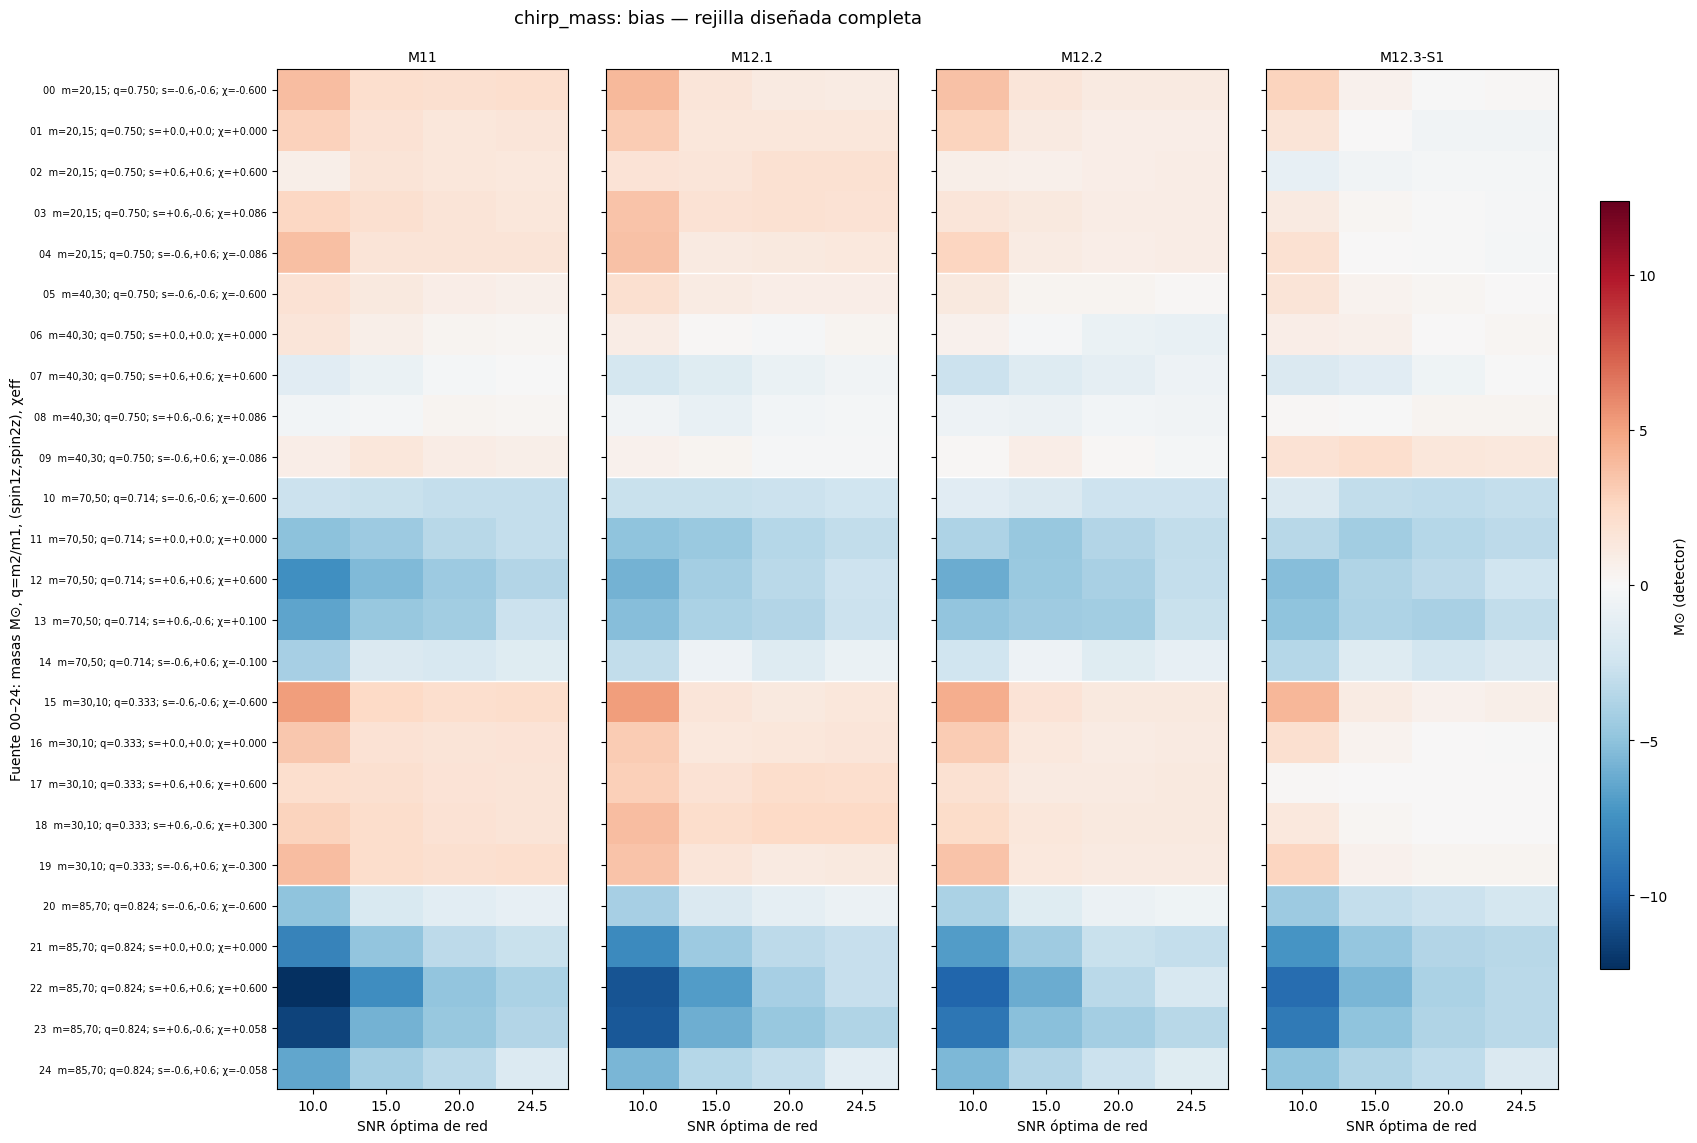

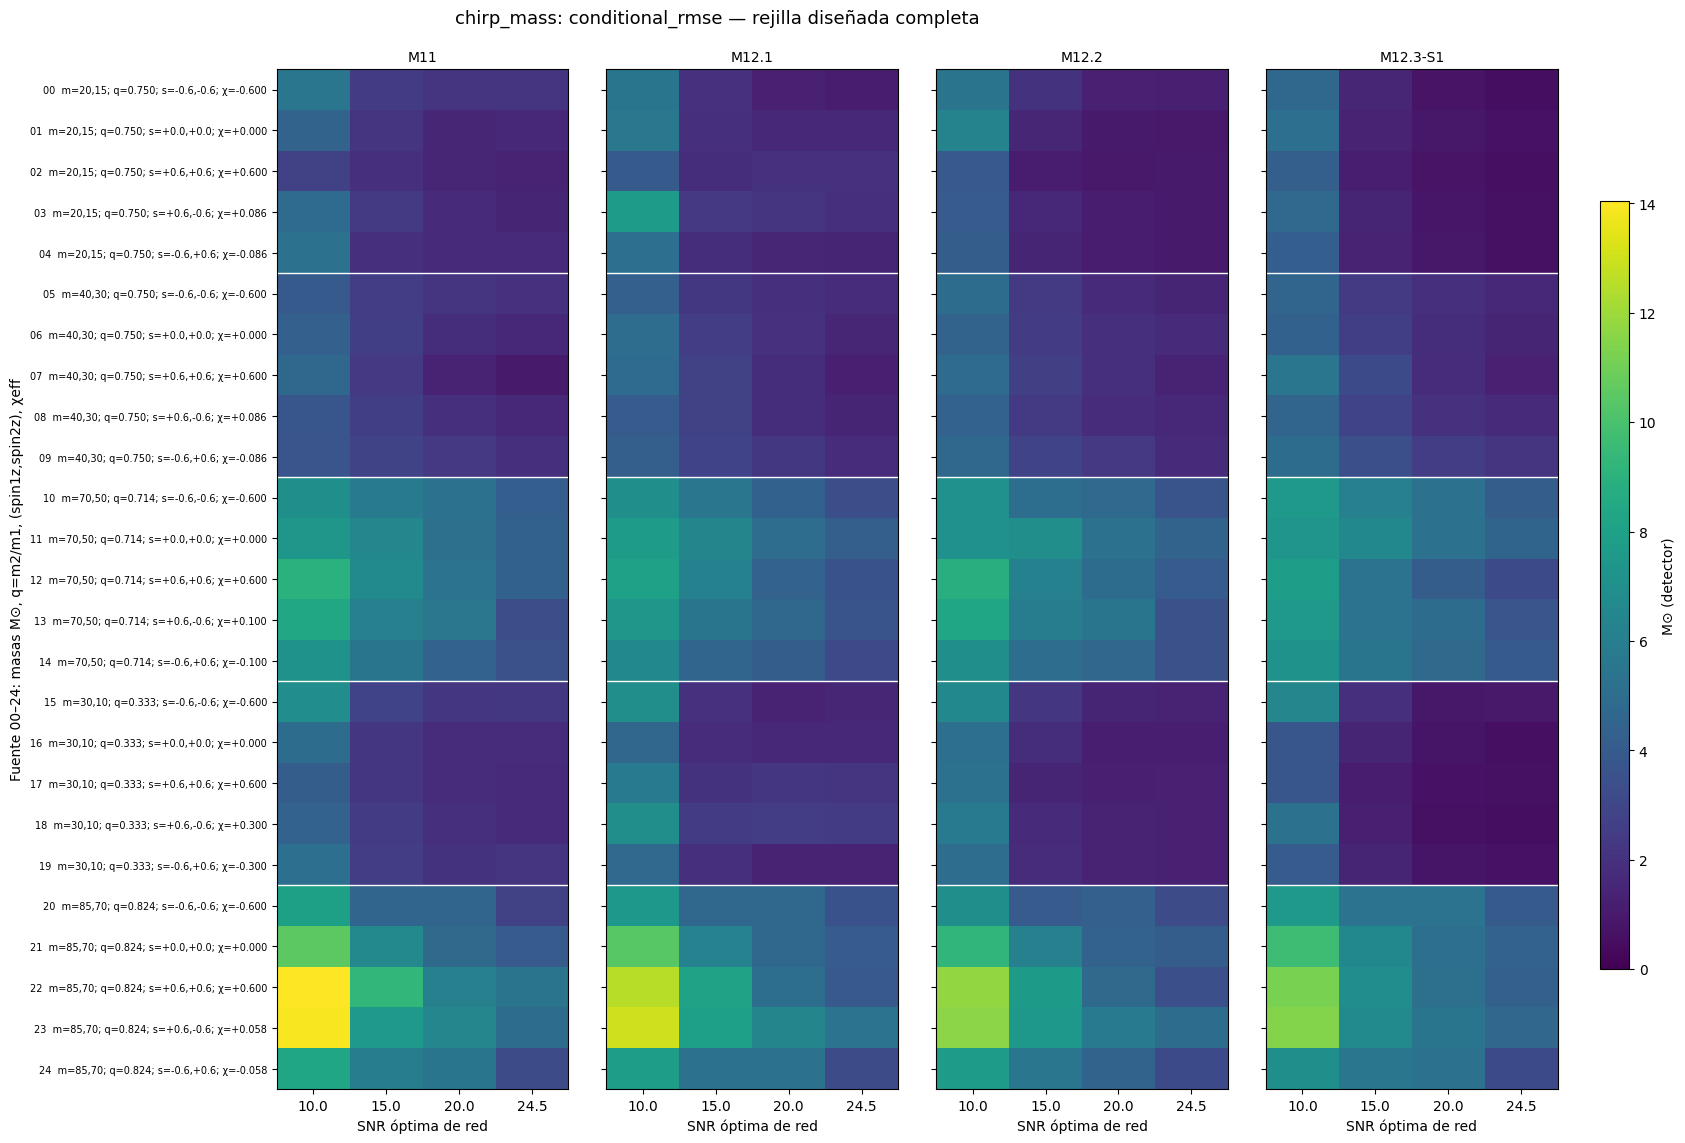

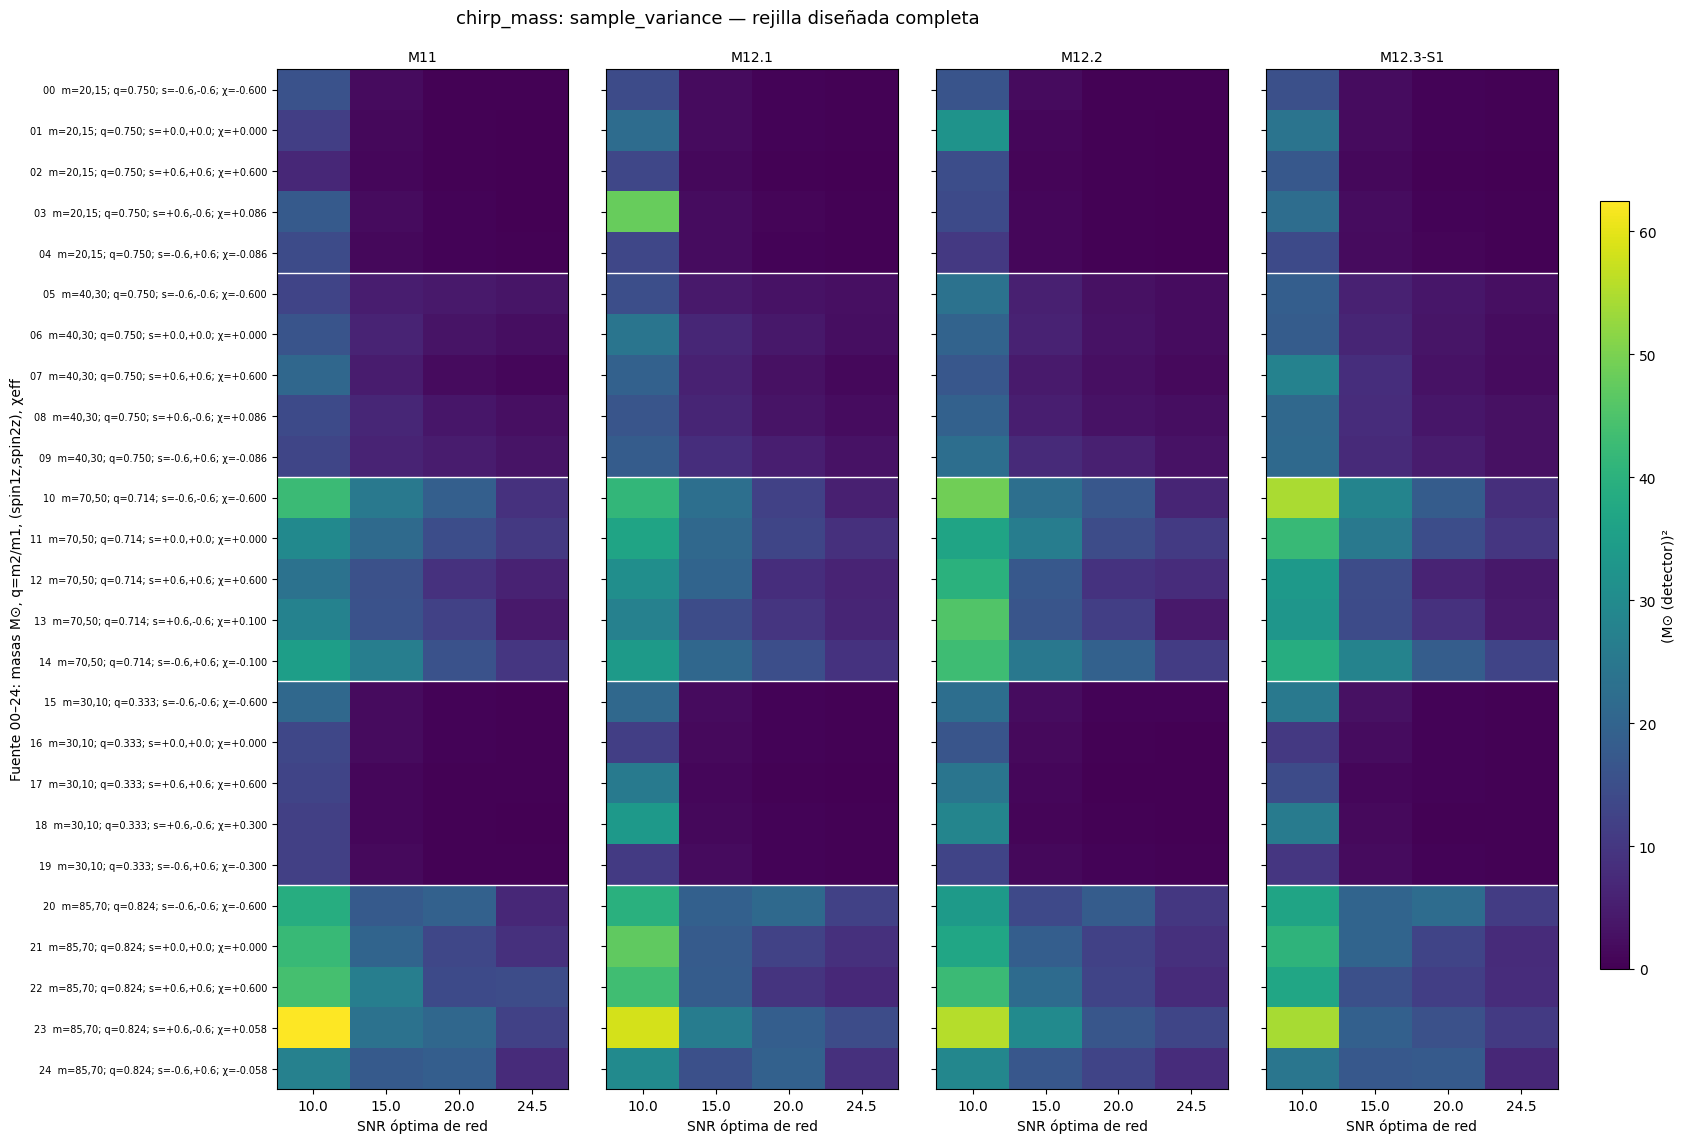

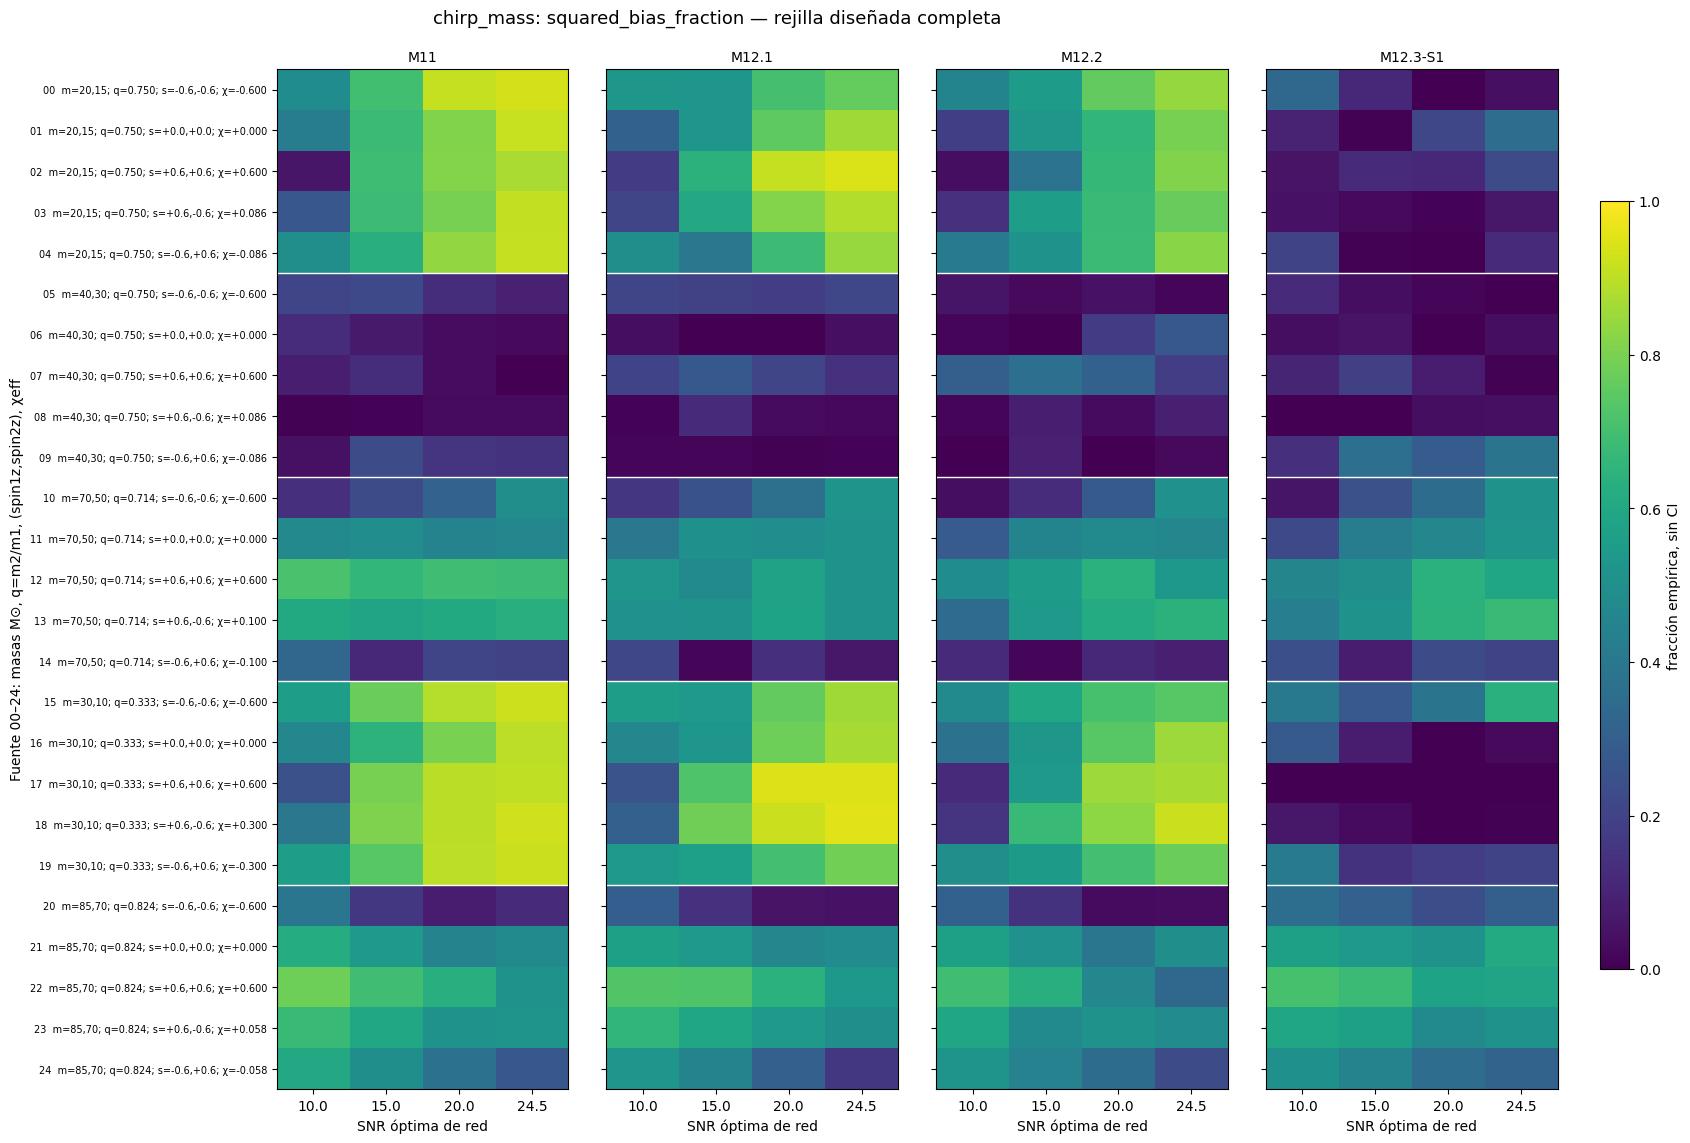

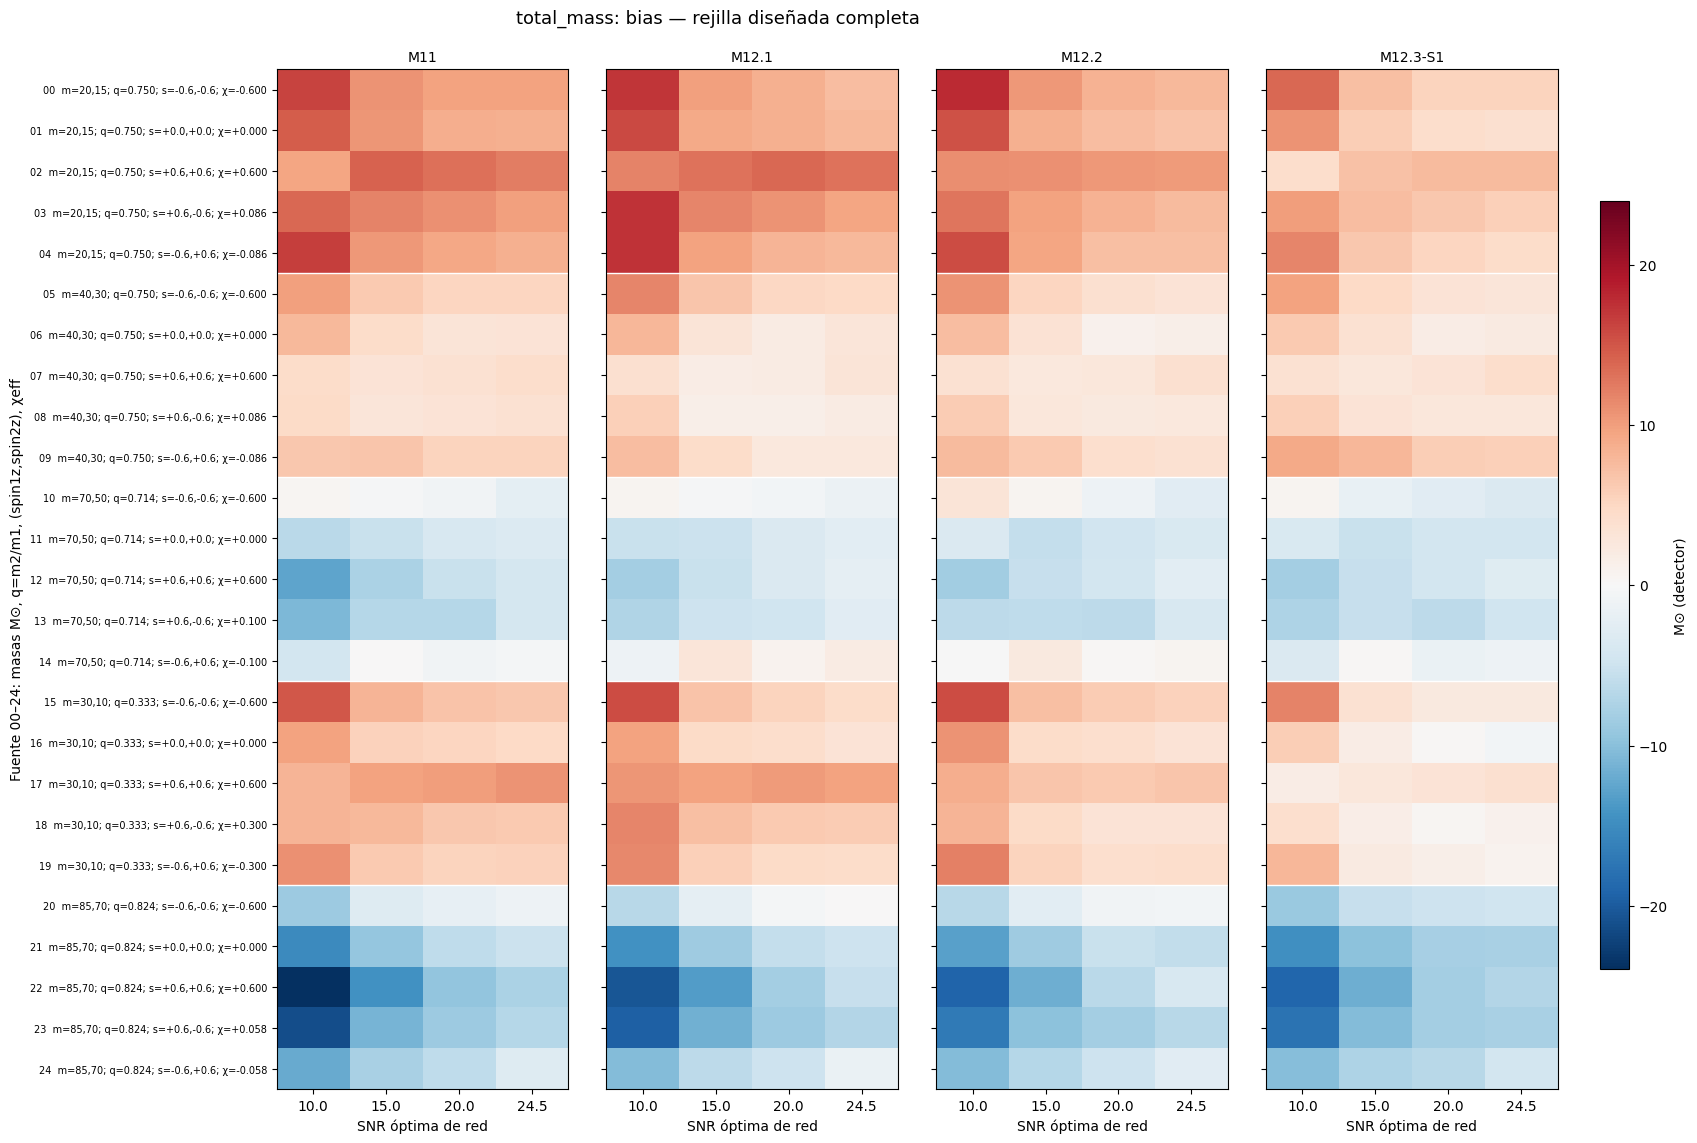

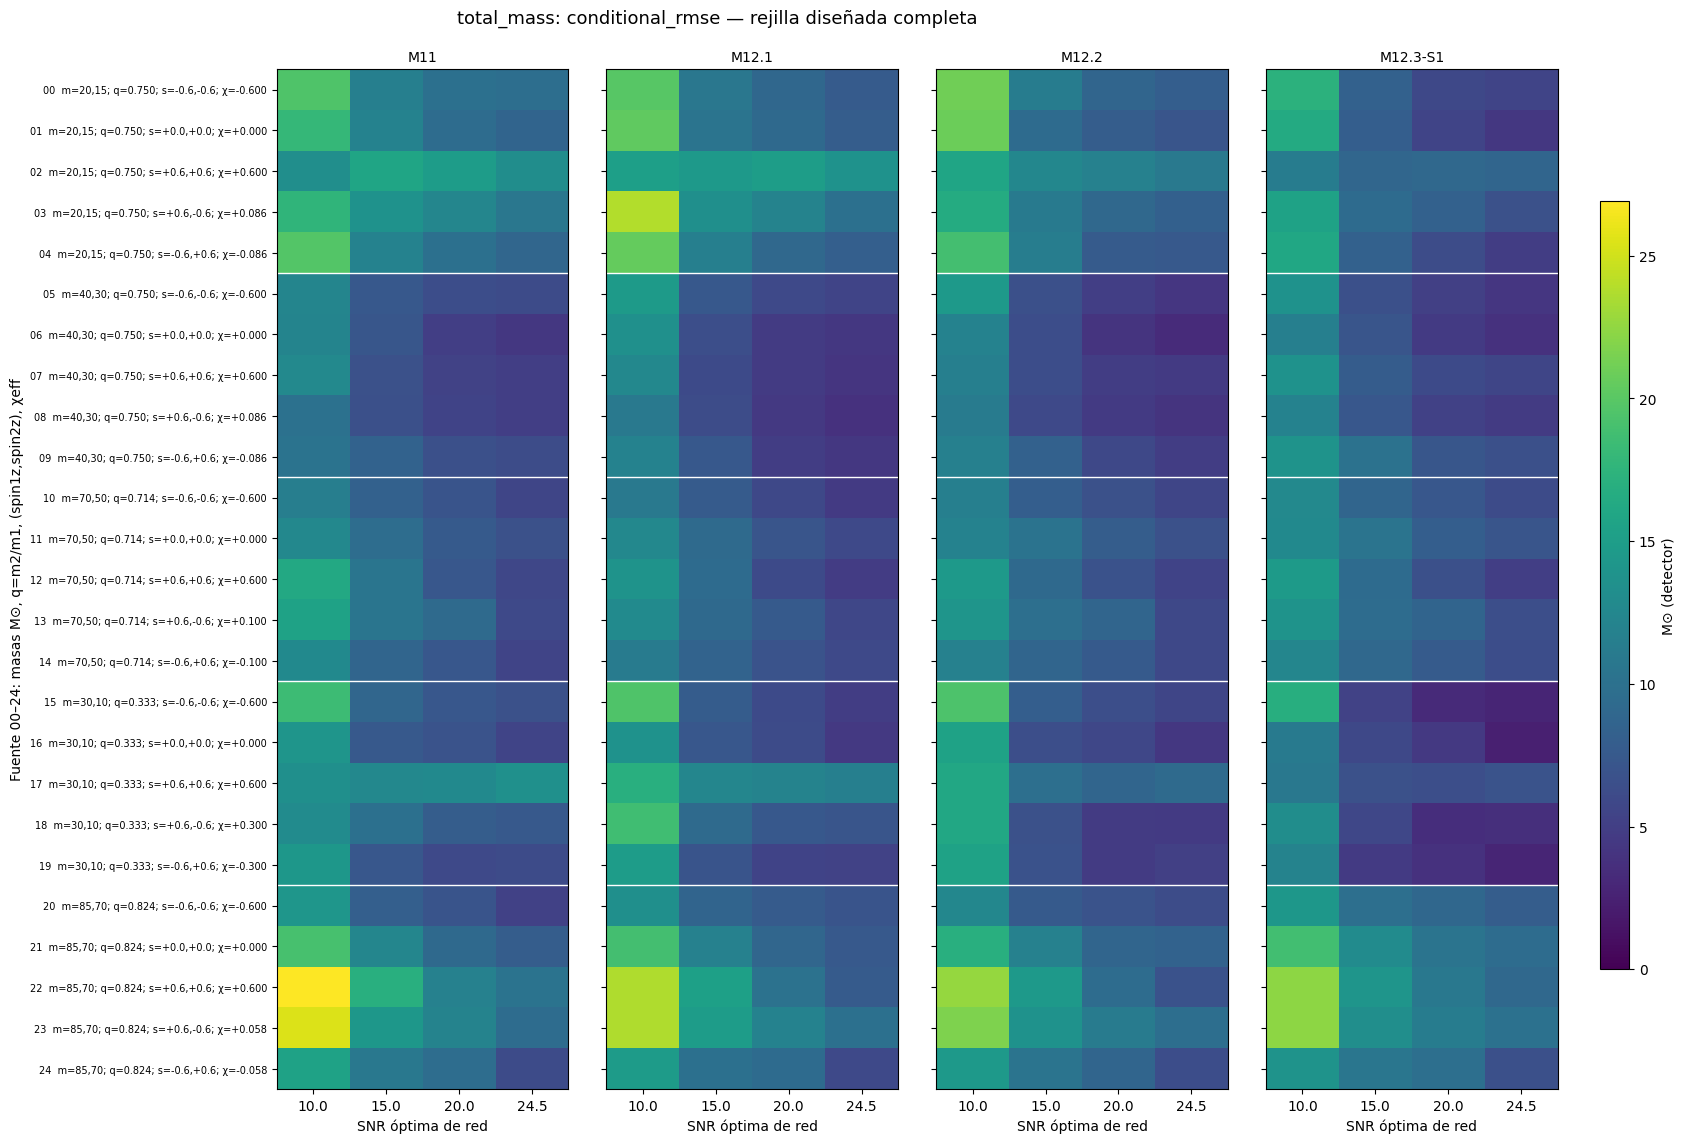

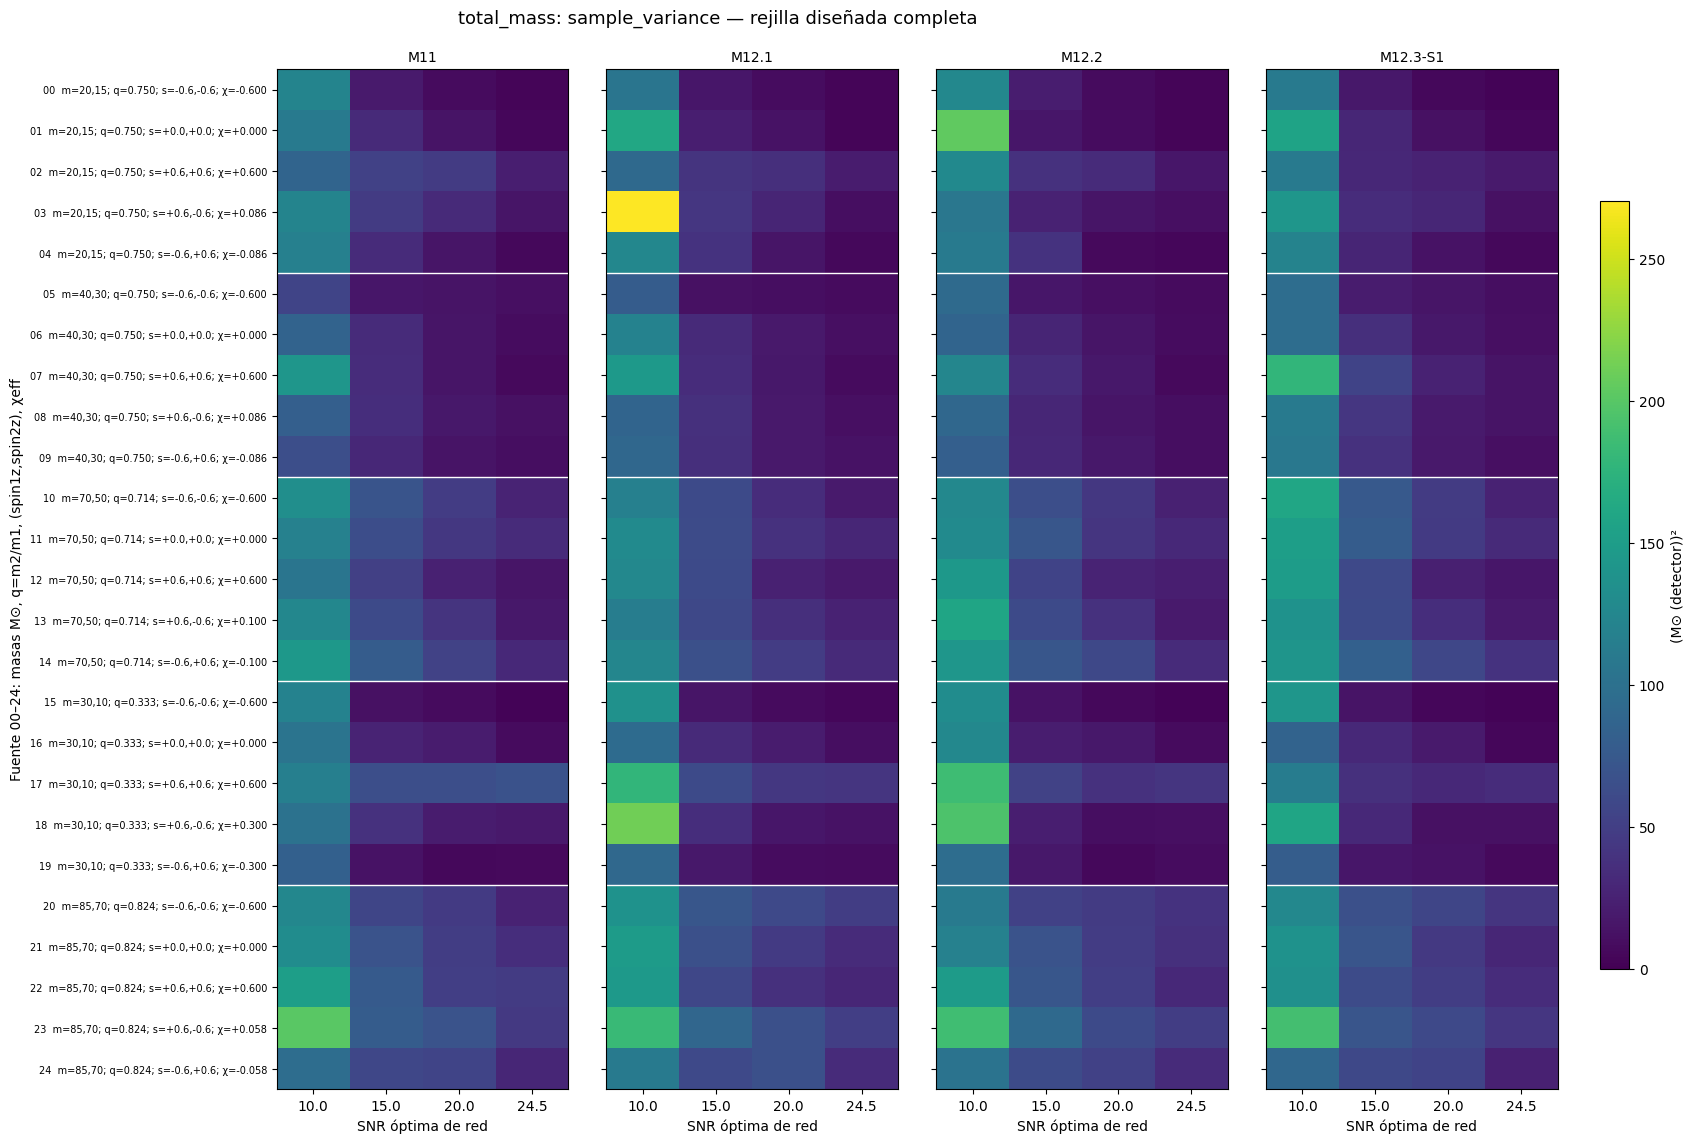

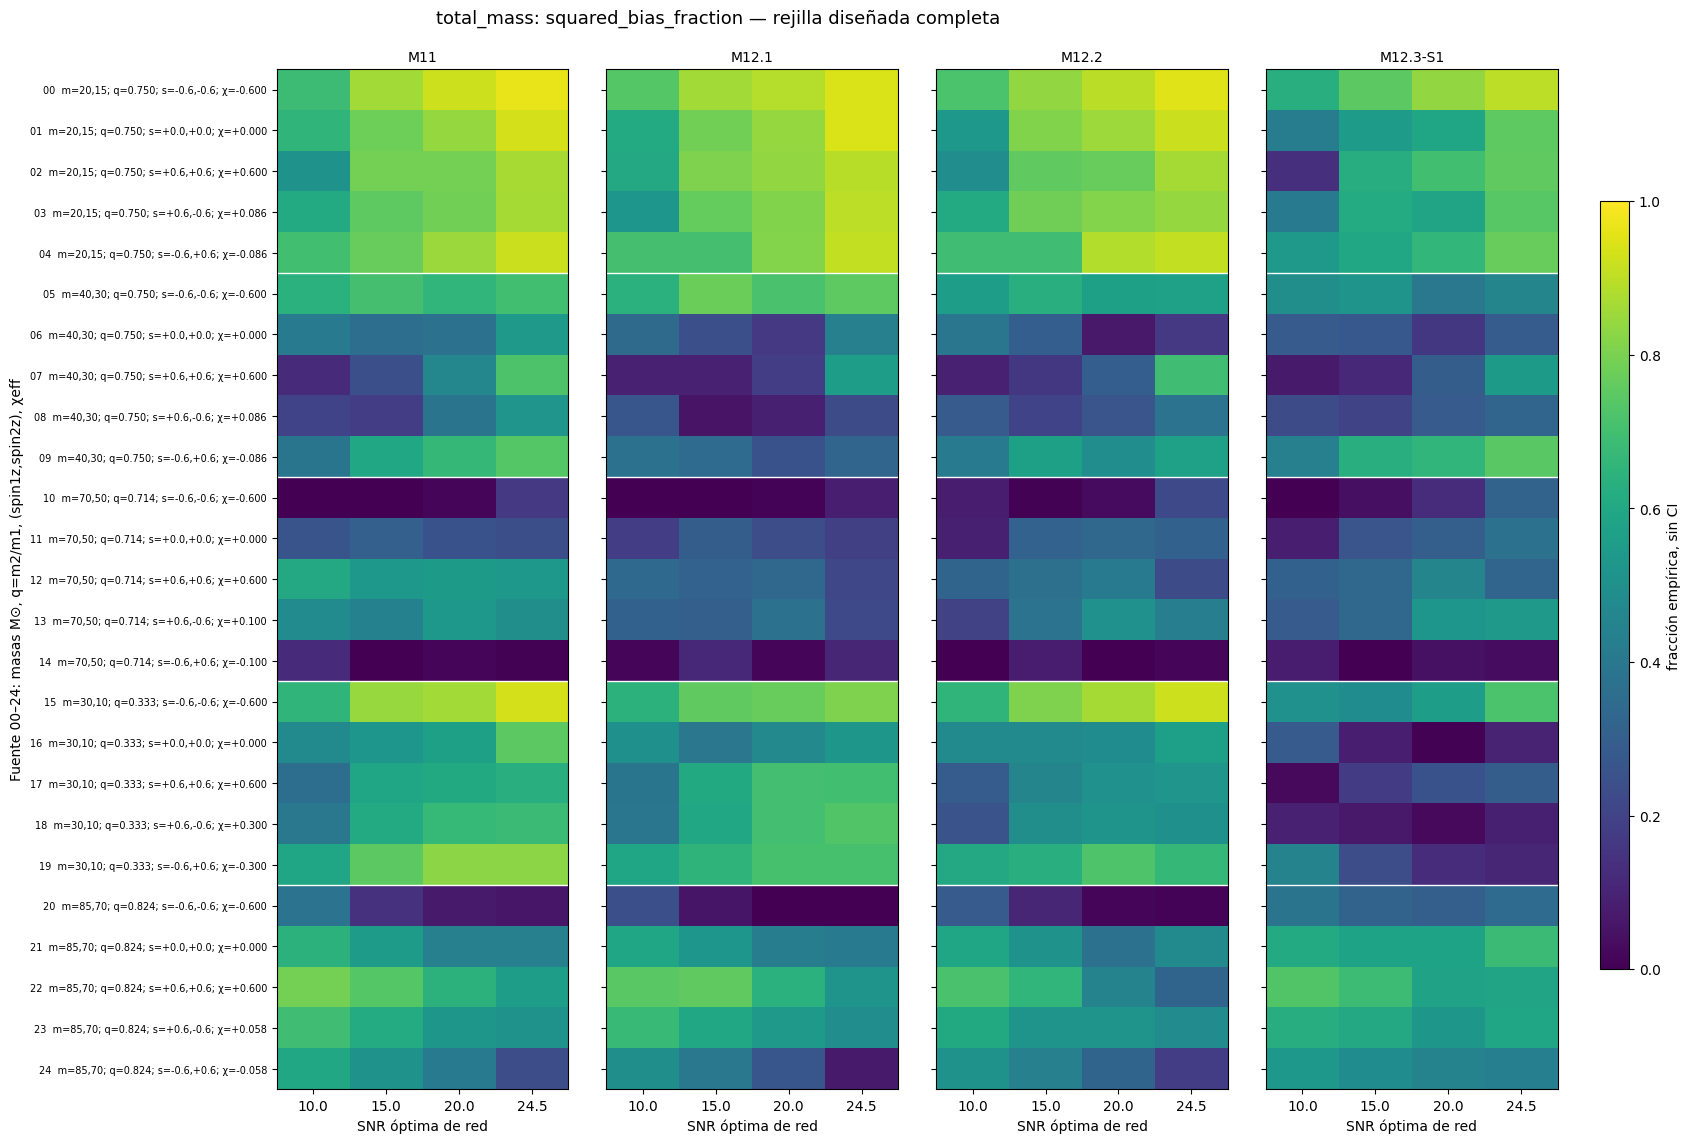

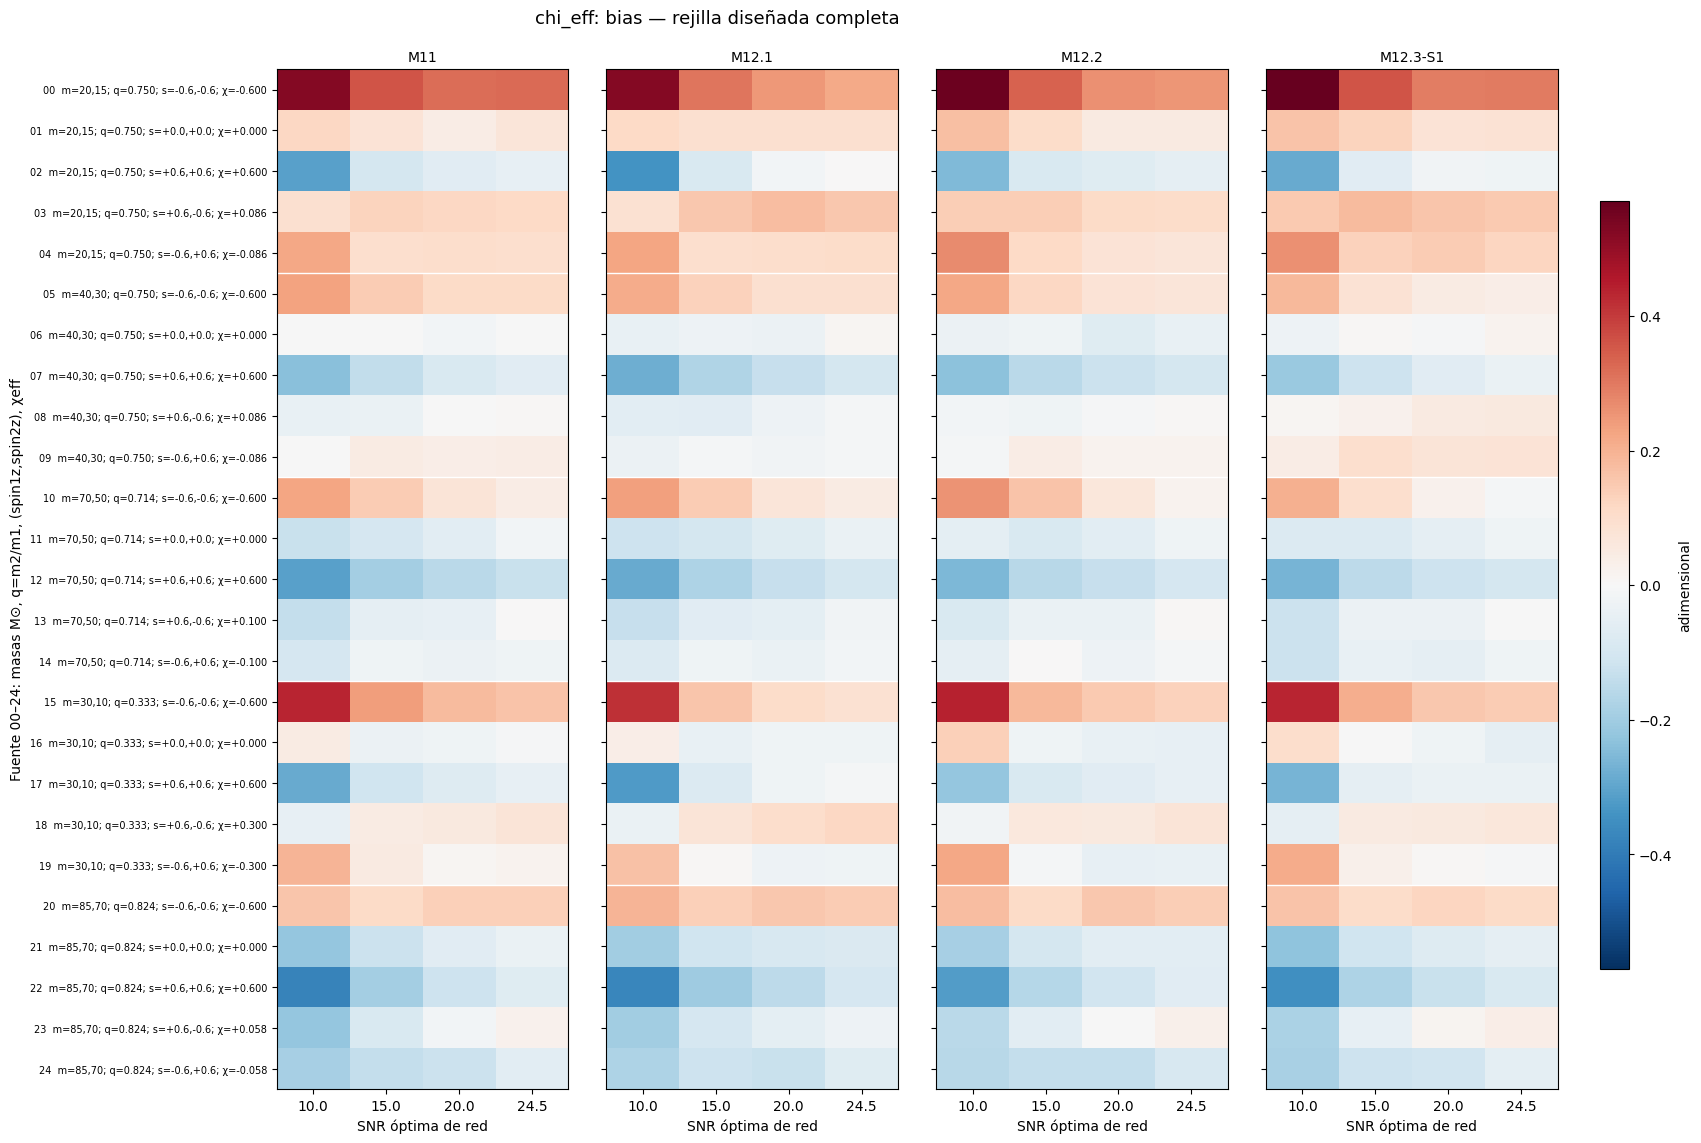

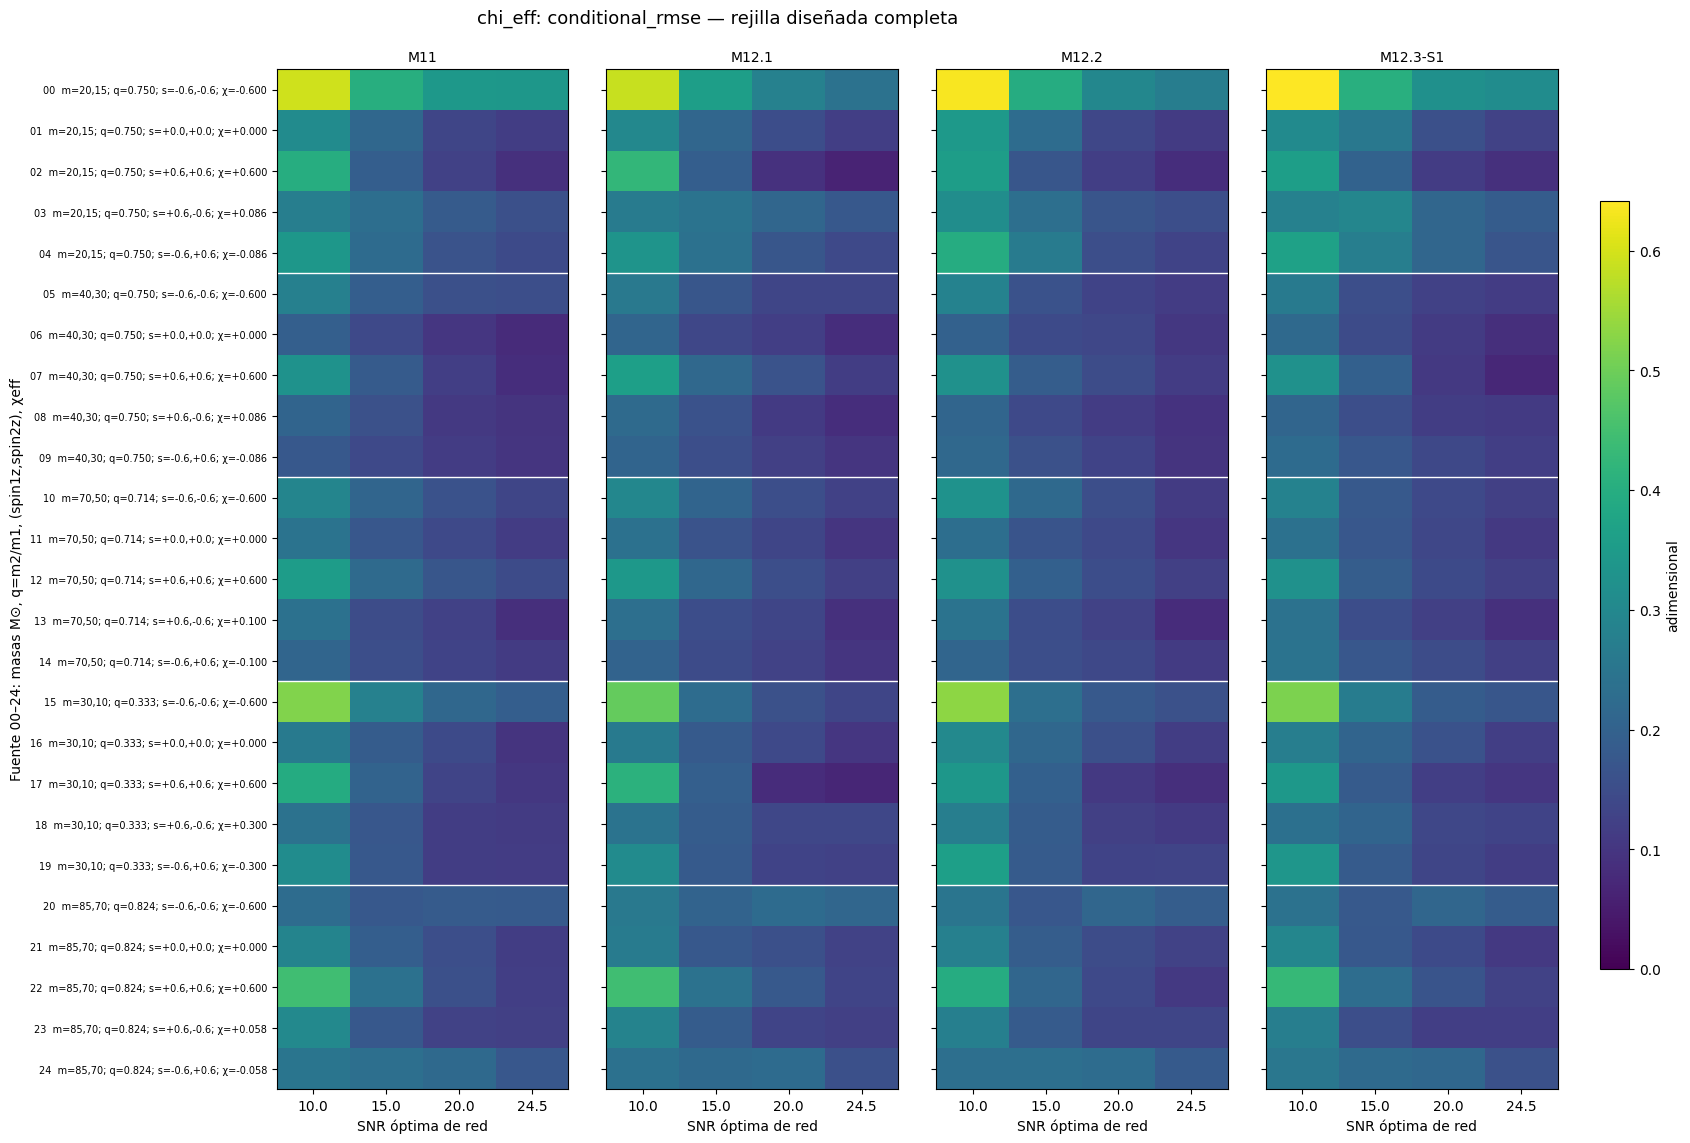

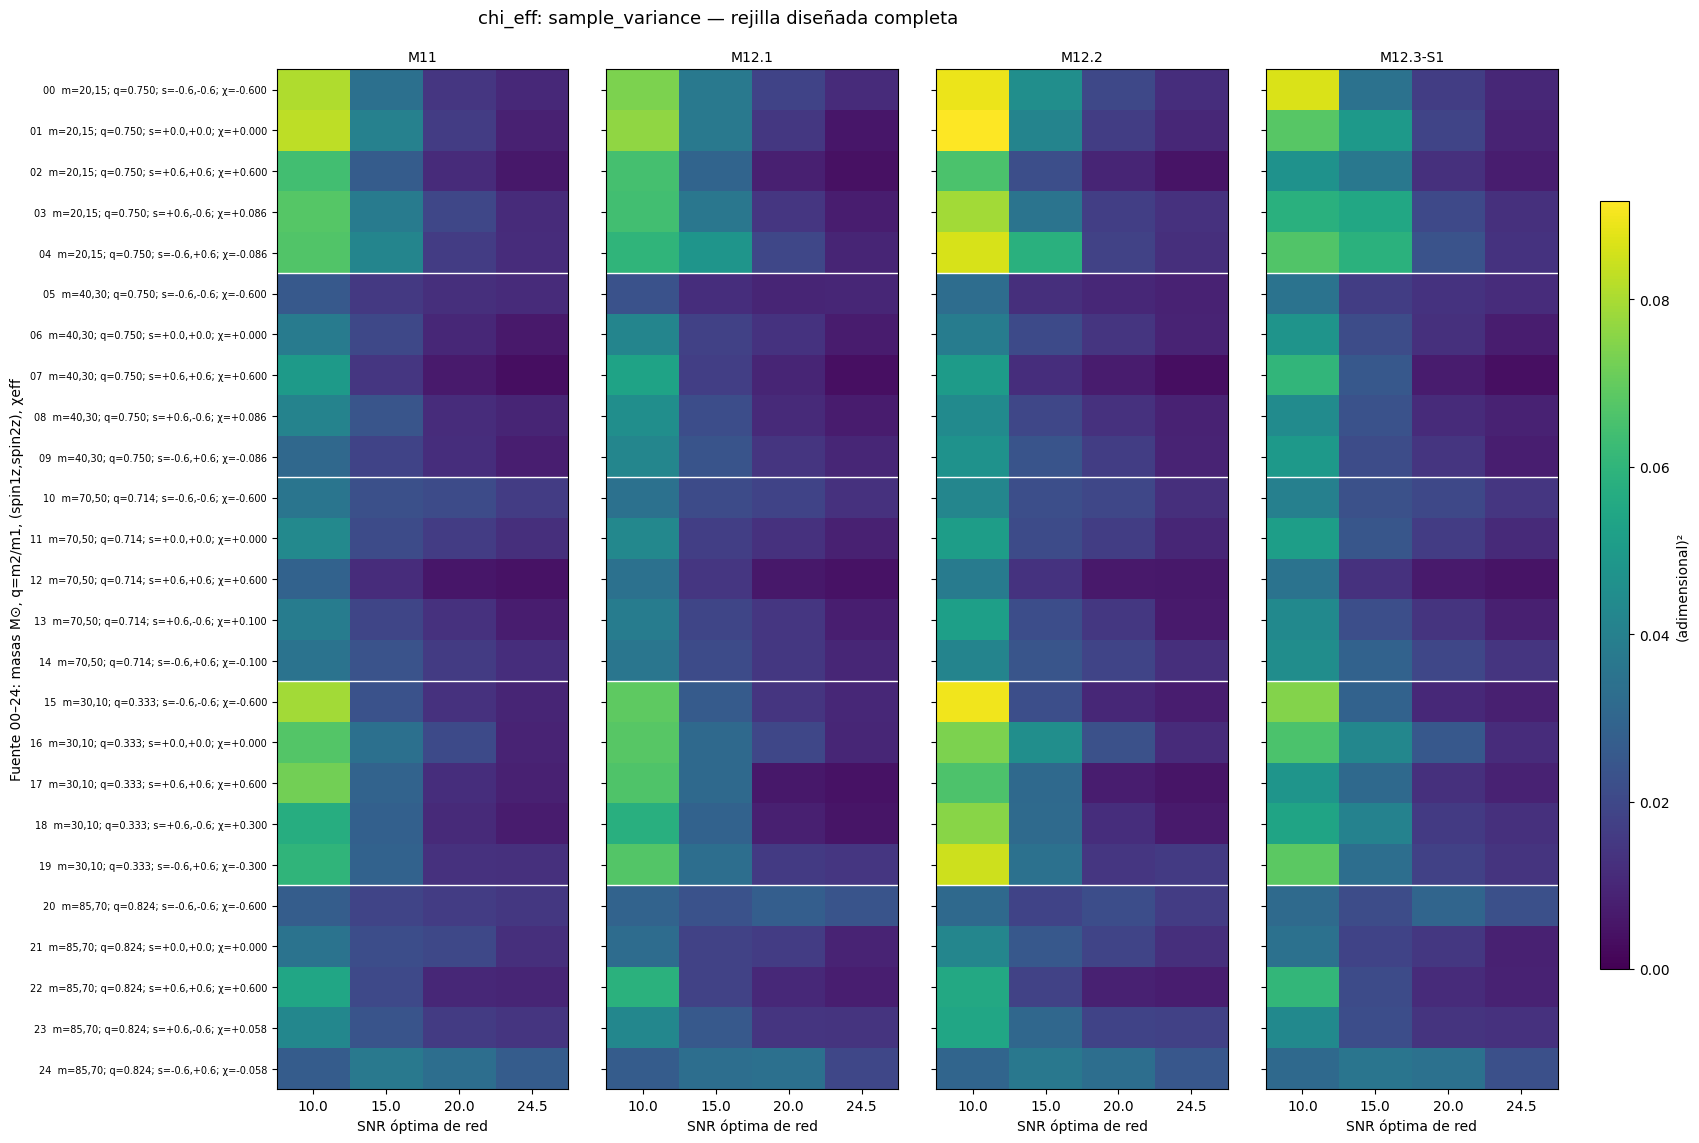

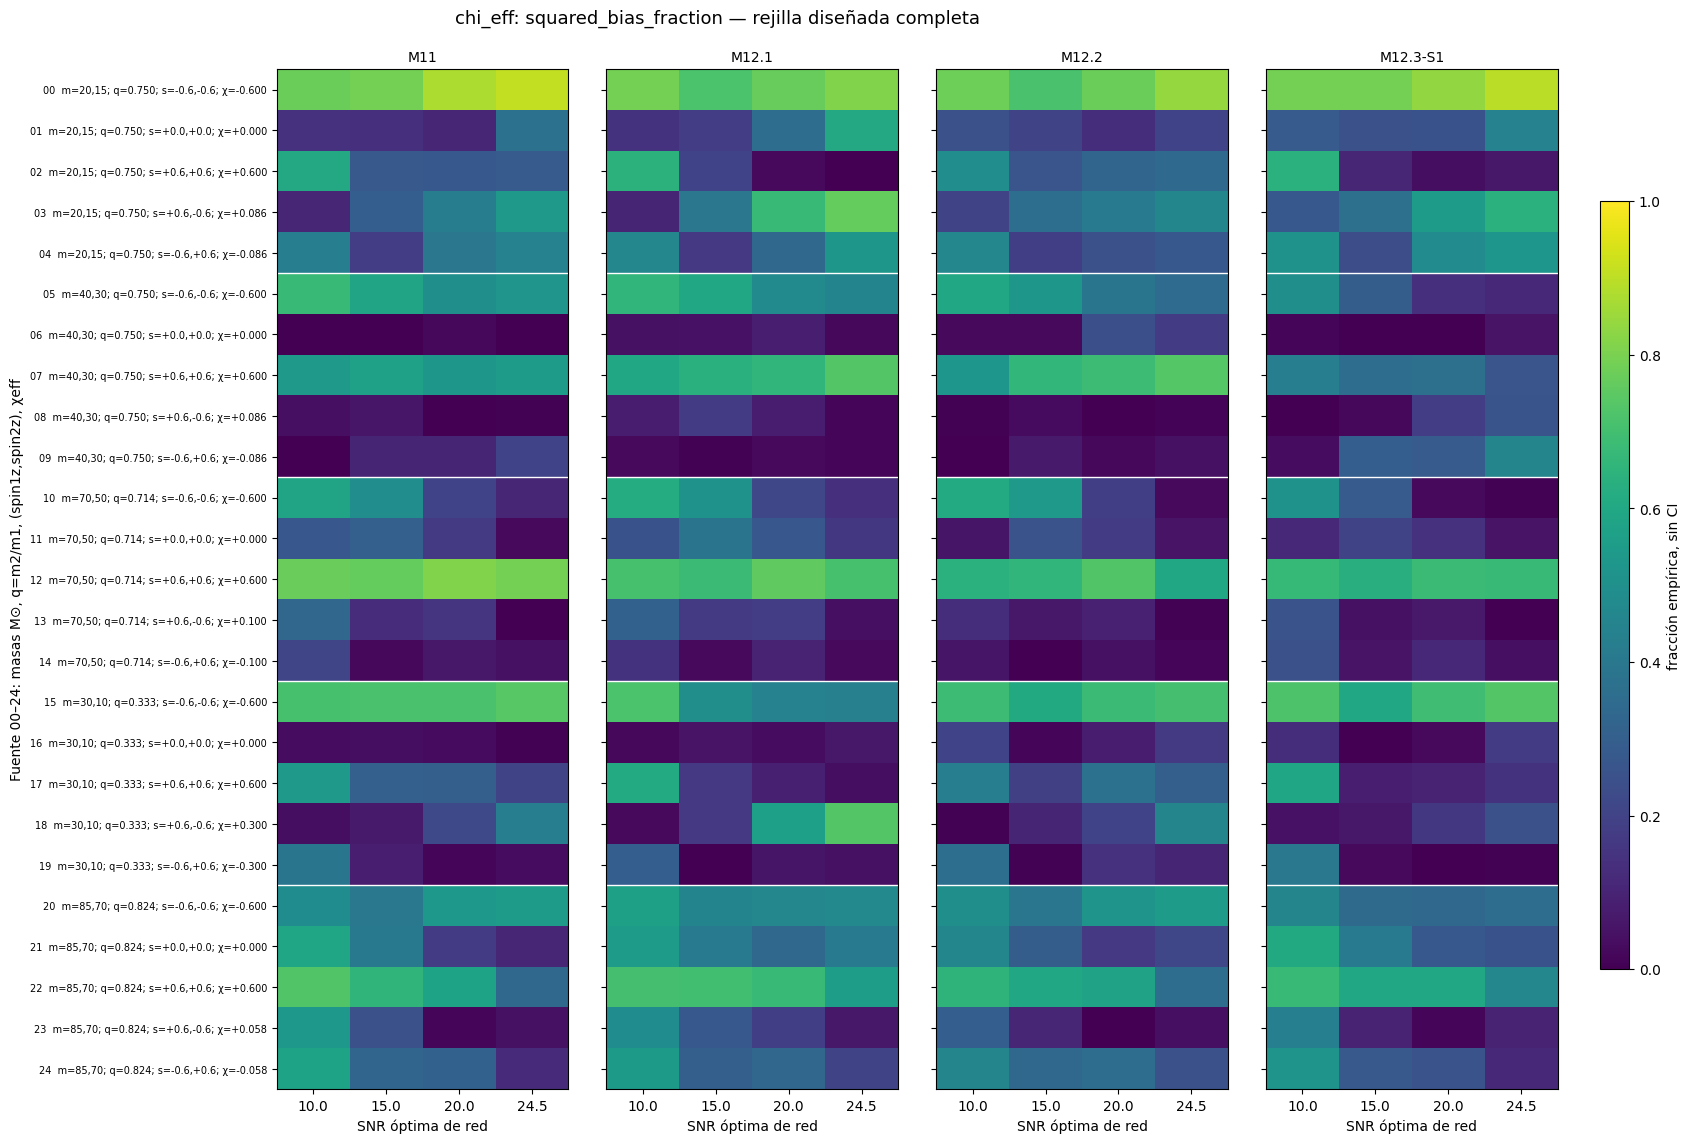

In [7]:
OUTPUT = contracts.output_directory(DATA_ROOT, Path(EXPORT_DIR)) if EXPORT else None
saved_plots = []
def finish_figure(fig, name):
    if OUTPUT is not None:
        dest = OUTPUT / (name + ".png")
        with dest.open("xb") as stream:
            fig.savefig(stream, format="png", dpi=140, bbox_inches="tight")
        saved_plots.append(dest.name)
    plt.show()
    plt.close(fig)

def row_label(sid):
    s = source_catalog.loc[sid]
    return (f"{sid[-2:]}  m={s.mass_1:g},{s.mass_2:g}; q={s.mass_ratio:.3f}; "
            f"s={s.spin_1z:+.1f},{s.spin_2z:+.1f}; χ={s.chi_eff:+.3f}")

def heatmaps(frame, metric, label, column="model", panels=None, signed=False,
             fixed_limits=None, name=None, color_unit=None):
    panels = MODELS if panels is None else panels
    data = frame.loc[frame.label.eq(label)]
    values = data[metric].to_numpy(dtype=float)
    finite = values[np.isfinite(values)]
    if fixed_limits is not None:
        lo, hi = fixed_limits
    elif signed:
        bound = max(float(np.max(abs(finite))) if len(finite) else 0., 1e-12)
        lo, hi = -bound, bound
    else:
        lo, hi = 0., max(float(np.max(finite)) if len(finite) else 0., 1e-12)
    fig, axes = plt.subplots(1, len(panels), figsize=(4*len(panels)+5, 12), sharey=True, squeeze=False)
    cmap = plt.get_cmap("RdBu_r" if signed else "viridis").copy()
    cmap.set_bad("white")
    for ax, panel in zip(axes.flat, panels):
        matrix = (data.loc[data[column].eq(panel)].pivot(index="source_id", columns="target_snr", values=metric)
                  .reindex(index=SOURCES, columns=SNRS))
        image = ax.imshow(np.ma.masked_invalid(matrix.to_numpy()), aspect="auto", interpolation="nearest",
                          cmap=cmap, vmin=lo, vmax=hi)
        ax.set_title(str(panel), fontsize=10)
        ax.set_xticks(range(4)); ax.set_xticklabels(SNRS)
        ax.set_xlabel("SNR óptima de red")
        ax.set_yticks(range(25)); ax.set_yticklabels([row_label(sid) for sid in SOURCES], fontsize=7)
        for y in (4.5, 9.5, 14.5, 19.5): ax.axhline(y, color="white", linewidth=1)
    axes[0, 0].set_ylabel("Fuente 00–24: masas M⊙, q=m2/m1, (spin1z,spin2z), χeff")
    fig.suptitle(f"{label}: {metric} — rejilla diseñada completa", fontsize=13)
    fig.subplots_adjust(left=.29, right=.90, bottom=.08, top=.93, wspace=.13)
    bar_ax = fig.add_axes([.92, .18, .014, .64])
    fig.colorbar(image, cax=bar_ax, label=color_unit or UNITS[label])
    finish_figure(fig, name or f"{label}_{metric}")

for label in LABELS:
    for metric, signed, limits, unit in (
            ("bias", True, None, UNITS[label]),
            ("conditional_rmse", False, None, UNITS[label]),
            ("sample_variance", False, None, f"({UNITS[label]})²"),
            ("squared_bias_fraction", False, (0, 1), "fracción empírica, sin CI")):
        heatmaps(summary, metric, label, signed=signed, fixed_limits=limits, color_unit=unit)

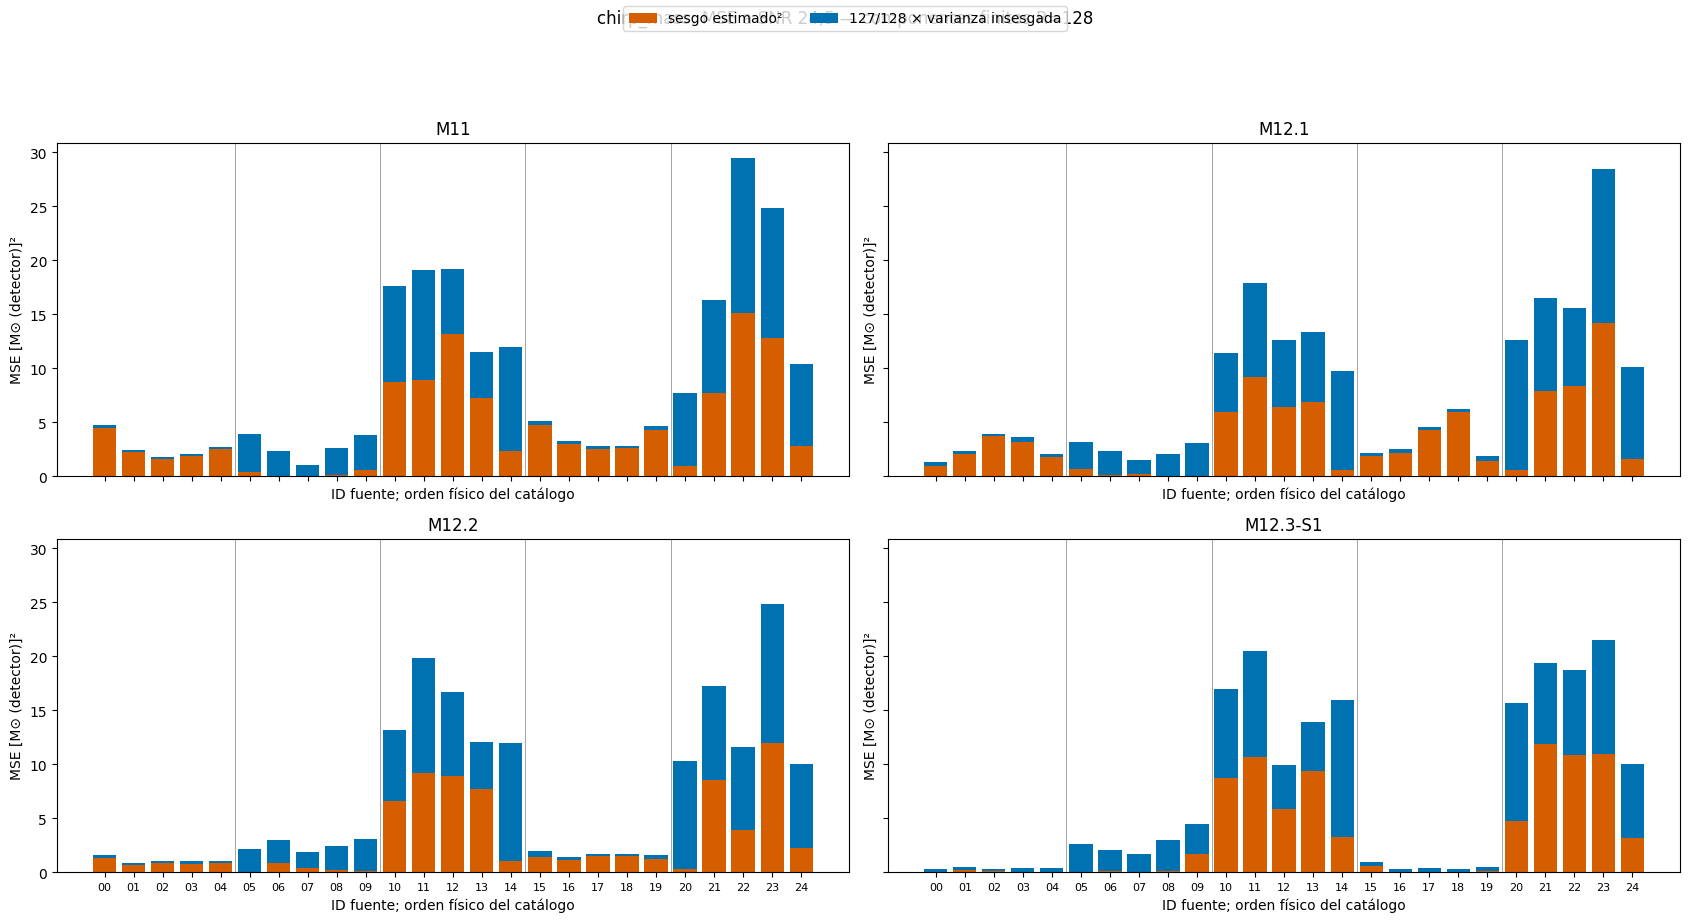

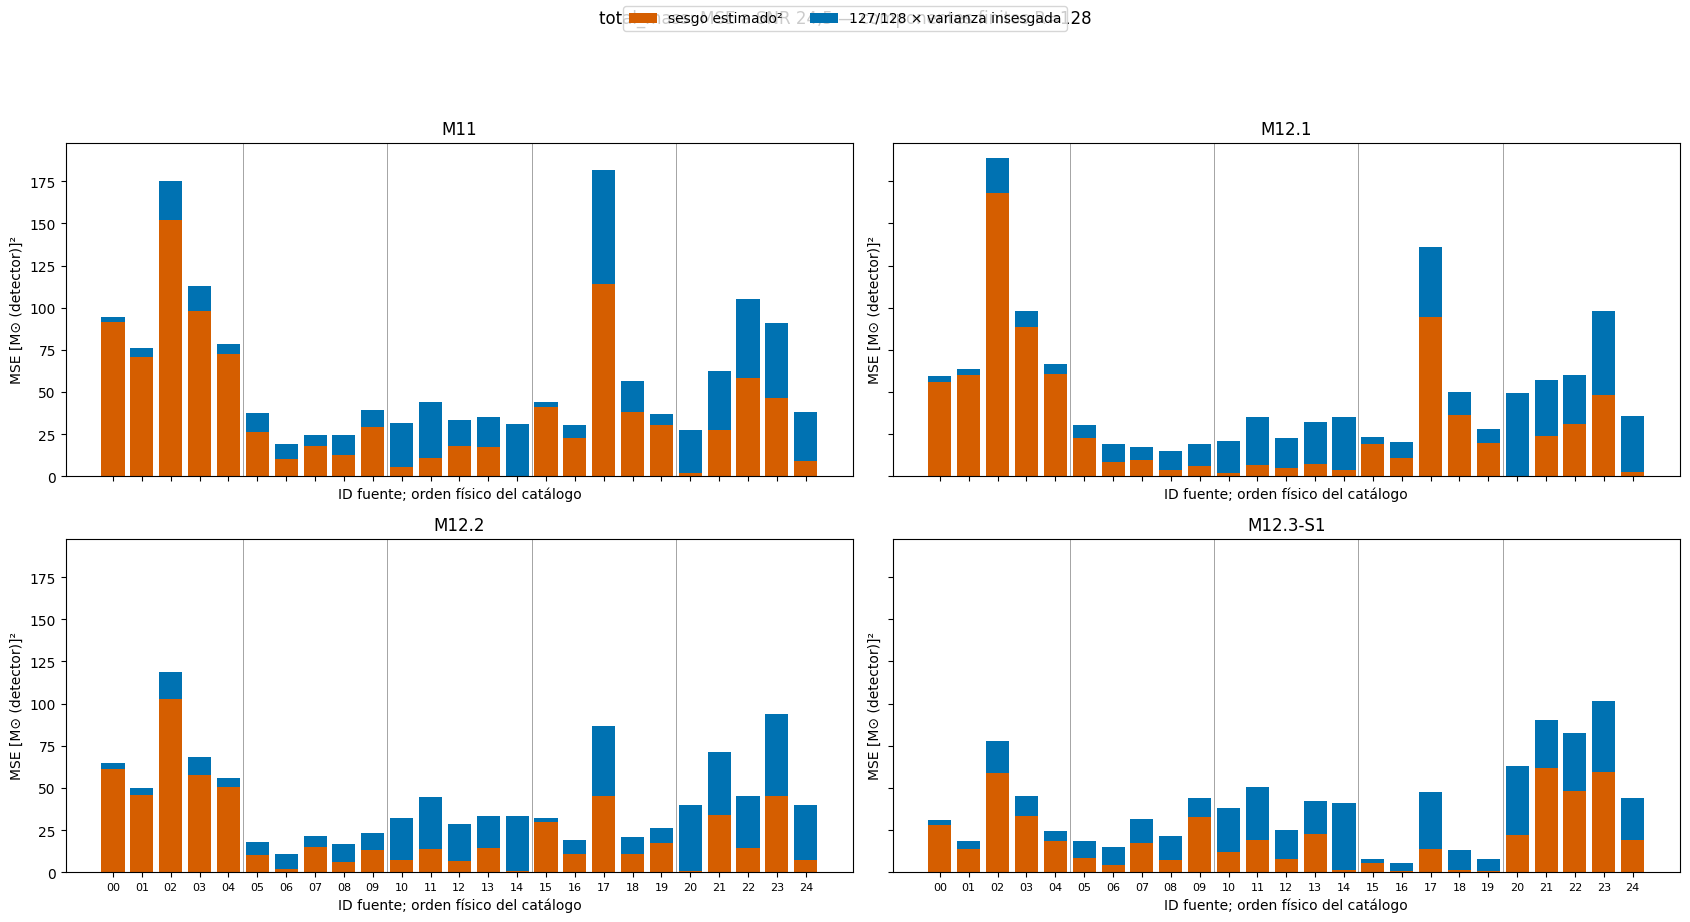

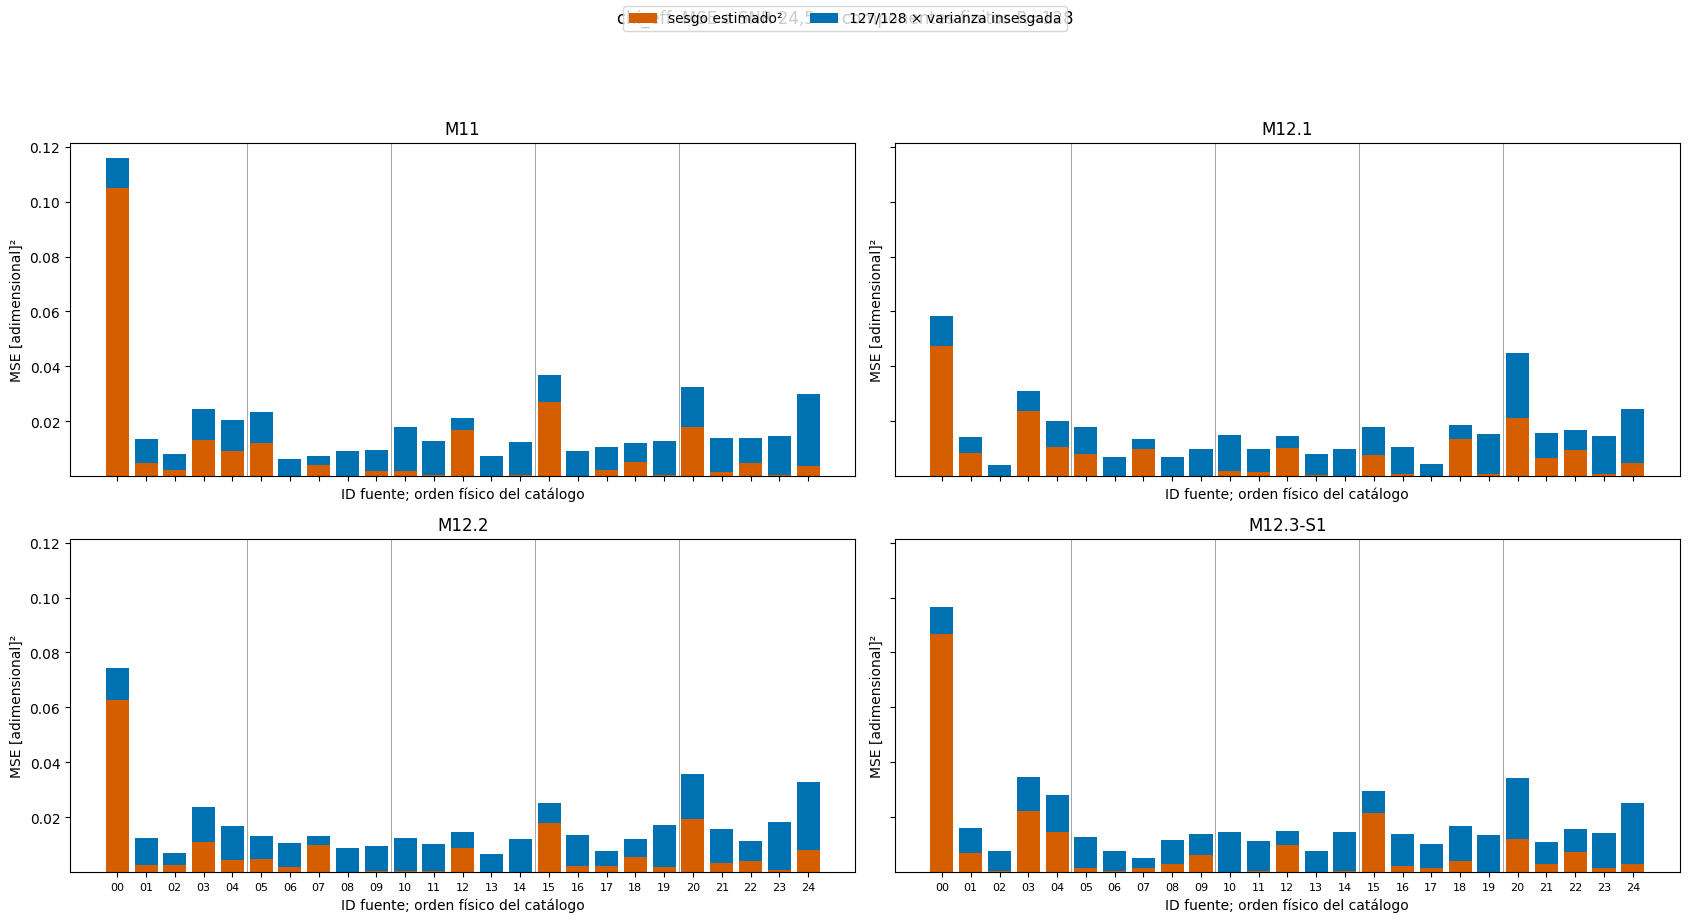

In [8]:
high_snr = summary.loc[summary.target_snr.eq(24.5)].copy()
high_snr["bias_ci_excludes_zero"] = high_snr.bias_ci_low.gt(0) | high_snr.bias_ci_high.lt(0)
for label in LABELS:
    fig, axes = plt.subplots(2, 2, figsize=(17, 9), sharex=True, sharey=True)
    for ax, model in zip(axes.flat, MODELS):
        frame = high_snr.loc[high_snr.label.eq(label) & high_snr.model.eq(model)].set_index("source_id").loc[SOURCES]
        ax.bar(np.arange(25), frame.bias_squared, label="sesgo estimado²", color="#d55e00")
        ax.bar(np.arange(25), frame.finite_R_variance_component, bottom=frame.bias_squared,
               label="127/128 × varianza insesgada", color="#0072b2")
        ax.set_title(model); ax.set_ylabel(f"MSE [{UNITS[label]}]²")
        ax.set_xticks(range(25)); ax.set_xticklabels([sid[-2:] for sid in SOURCES], fontsize=8)
        ax.set_xlabel("ID fuente; orden físico del catálogo")
        for y in (4.5, 9.5, 14.5, 19.5): ax.axvline(y, color="gray", lw=.5)
    handles, legends = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, legends, loc="upper center", ncol=2)
    fig.suptitle(f"{label}: MSE a SNR 24,5 — componentes finitos R=128", y=1.02)
    fig.tight_layout(rect=(0, 0, 1, .95))
    finish_figure(fig, f"{label}_mse_decomposition_high_snr")

## 4. Dependencia de SNR y sesgo persistente

Contraste SNR 24,5 − 10 para las 300 combinaciones fuente–modelo–target. Los cambios son diferencias puntuales: no se construye un CI del cambio restando extremos de IC, ni se emparejan ruidos entre SNR. Se conservan los IC precomputados del sesgo a 24,5. Excluir cero es una bandera exploratoria puntual, no descubrimiento corregido por 300 comparaciones.

“Persistente” significa presente al máximo SNR ensayado, no una meseta asintótica. Menor varianza puede coexistir con mayor sesgo. Los promedios entre fuentes describen únicamente esta rejilla; media de RMSE condicional no equivale a RMSE de G1.


In [9]:
endpoint_keys = ["source_id", "model", "label"]
endpoint_metrics = ["bias", "absolute_bias", "sample_variance", "noise_std", "conditional_mse", "conditional_rmse", "squared_bias_fraction"]
low = summary.loc[summary.target_snr.eq(10)].set_index(endpoint_keys)
high = high_snr.set_index(endpoint_keys)
endpoints = high[[*physical_columns, "truth", "unit", "bias_ci_low", "bias_ci_high",
                  "bias_ci_excludes_zero", "dominant_component"]].copy()
for metric in endpoint_metrics:
    endpoints[metric+"_snr10"] = low[metric]
    endpoints[metric+"_snr24p5"] = high[metric]
    endpoints["delta_"+metric] = high[metric] - low[metric]
endpoints = endpoints.reset_index()
require(len(endpoints) == 300, "Faltan contrastes SNR")
endpoint_summary = endpoints.groupby(["label", "model"]).agg(
    sources=("source_id", "size"),
    variance_decreases=("delta_sample_variance", lambda v: int((v < 0).sum())),
    rmse_decreases=("delta_conditional_rmse", lambda v: int((v < 0).sum())),
    absolute_bias_decreases=("delta_absolute_bias", lambda v: int((v < 0).sum())),
    mean_rmse_snr10=("conditional_rmse_snr10", "mean"),
    mean_rmse_snr24p5=("conditional_rmse_snr24p5", "mean"),
    mean_abs_bias_snr24p5=("absolute_bias_snr24p5", "mean"),
    high_snr_pointwise_bias_flags=("bias_ci_excludes_zero", "sum"),
    high_snr_bias_dominant=("dominant_component", lambda v: int((v == "sesgo²").sum())))
display(endpoint_summary)
with pd.option_context("display.max_rows", 300, "display.max_columns", None):
    display(endpoints[[*endpoint_keys, "truth", "bias_snr24p5", "bias_ci_low", "bias_ci_high",
        "delta_bias", "delta_absolute_bias", "delta_sample_variance", "delta_conditional_rmse",
        "squared_bias_fraction_snr24p5", "dominant_component"]])

sources  variance_decreases  rmse_decreases  \
label      model                                                   
chi_eff    M11            25                  25              25   
           M12.1          25                  25              25   
           M12.2          25                  25              25   
           M12.3-S1       25                  25              25   
chirp_mass M11            25                  25              25   
           M12.1          25                  25              25   
           M12.2          25                  25              25   
           M12.3-S1       25                  25              25   
total_mass M11            25                  25              24   
           M12.1          25                  25              25   
           M12.2          25                  25              25   
           M12.3-S1       25                  25              25   

                     absolute_bias_decreases  mean_rmse_snr10  \
label      model                                                
chi_eff    M11                            21         0.307398   
           M12.1                          23         0.307911   
           M12.2                          22         0.314616   
           M12.3-S1                       21         0.308980   
chirp_mass M11                            23         6.506571   
           M12.1                          24         6.710516   
           M12.2                          21         6.424184   
           M12.3-S1                       23         6.190613   
total_mass M11                            22        15.535723   
           M12.1                          22        16.114017   
           M12.2                          22        15.570126   
           M12.3-S1                       20        14.524286   

                     mean_rmse_snr24p5  mean_abs_bias_snr24p5  \
label      model                                                
chi_eff    M11                0.130861               0.069305   
           M12.1              0.124032               0.068466   
           M12.2              0.125870               0.065695   
           M12.3-S1           0.130880               0.068402   
chirp_mass M11                2.644497               1.822715   
           M12.1              2.511987               1.636553   
           M12.2              2.299709               1.429967   
           M12.3-S1           2.185107               1.281967   
total_mass M11                7.426178               5.684728   
           M12.1              6.730522               4.727367   
           M12.2              6.348722               4.405314   
           M12.3-S1           5.931514               4.050504   

                     high_snr_pointwise_bias_flags  high_snr_bias_dominant  
label      model                                                            
chi_eff    M11                                  20                       7  
           M12.1                                20                       8  
           M12.2                                21                       5  
           M12.3-S1                             22                       5  
chirp_mass M11                                  23                      14  
           M12.1                                23                      15  
           M12.2                                23                      13  
           M12.3-S1                             20                       8  
total_mass M11                                  24                      18  
           M12.1                                24                      13  
           M12.2                                23                      13  
           M12.3-S1                             25                      12

,source_id,model,label,truth,bias_snr24p5,bias_ci_low,bias_ci_high,delta_bias,delta_absolute_bias,delta_sample_variance,delta_conditional_rmse,squared_bias_fraction_snr24p5,dominant_component
0,M1251B_SRC_00,M11,chi_eff,-0.600000,0.324247,0.306462,0.341349,-0.200228,-0.200228,-0.069985,-0.255731,0.908648,sesgo²
1,M1251B_SRC_00,M12.1,chi_eff,-0.600000,0.217464,0.199063,0.235213,-0.304753,-0.304753,-0.062336,-0.346346,0.810579,sesgo²
2,M1251B_SRC_00,M12.2,chi_eff,-0.600000,0.250127,0.232036,0.268388,-0.311217,-0.311217,-0.077239,-0.362509,0.840835,sesgo²
3,M1251B_SRC_00,M12.3-S1,chi_eff,-0.600000,0.294378,0.277039,0.311569,-0.276131,-0.276131,-0.076461,-0.330497,0.896932,sesgo²
4,M1251B_SRC_00,M11,chirp_mass,15.047320,2.111329,2.015098,2.206105,-1.729588,-1.729588,-15.467969,-3.331060,0.935069,sesgo²
5,M1251B_SRC_00,M12.1,chirp_mass,15.047320,0.996923,0.901916,1.091797,-2.980919,-2.980919,-13.905506,-4.330655,0.765084,sesgo²
6,M1251B_SRC_00,M12.2,chirp_mass,15.047320,1.144657,1.062465,1.229389,-2.486133,-2.486133,-15.975058,-4.163963,0.842733,sesgo²
7,M1251B_SRC_00,M12.3-S1,chirp_mass,15.047320,0.103577,0.015484,0.194806,-2.630695,-2.630695,-14.872551,-4.220946,0.039393,varianza finita
8,M1251B_SRC_00,M11,total_mass,35.000000,9.556912,9.244549,9.878030,-6.600476,-6.600476,-118.141967,-9.805402,0.964874,sesgo²
9,M1251B_SRC_00,M12.1,total_mass,35.000000,7.479751,7.163554,7.794220,-9.600296,-9.600296,-101.767156,-12.200693,0.943552,sesgo²


## 5. Contracción respecto a medias train G1

Medias/escalas exclusivamente de los checkpoints congelados. Distinguir dirección hacia media (`bias × (mu_train−truth)>0`), acercamiento efectivo (reducción de distancia absoluta) y sobrepaso. La razón `bias/(mu_train−truth)` es 0 en la verdad y 1 en la media train; puede ser negativa o >1. Omitirla si |mu_train−truth| ≤1% de la desviación train evita divisiones inestables; es un umbral descriptivo, especialmente relevante en chi_eff próximo a cero.

Se cubren masas y chi_eff. Contracción no demuestra Bayes-optimalidad, prior posterior efectivo ni incertidumbre irreducible. Los objetivos ponderados y muestreo de los entrenamientos pueden cambiar sus óptimos.


sources  toward_mean  closer_to_mean  \
label      model    target_snr                                         
chi_eff    M11      10.0             25           19              14   
                    15.0             25           20              17   
                    20.0             25           20              16   
                    24.5             25           17              13   
           M12.1    10.0             25           19              14   
                    15.0             25           19              15   
                    20.0             25           18              14   
                    24.5             25           16              13   
           M12.2    10.0             25           19              14   
                    15.0             25           20              16   
                    20.0             25           19              15   
                    24.5             25           16              12   
           M12.3-S1 10.0             25           19              14   
                    15.0             25           18              15   
                    20.0             25           18              14   
                    24.5             25           15              12   
chirp_mass M11      10.0             25           23              23   
                    15.0             25           23              23   
                    20.0             25           24              24   
                    24.5             25           24              24   
           M12.1    10.0             25           23              23   
                    15.0             25           23              23   
                    20.0             25           21              21   
                    24.5             25           22              22   
           M12.2    10.0             25           23              23   
                    15.0             25           22              22   
                    20.0             25           22              22   
                    24.5             25           21              21   
           M12.3-S1 10.0             25           23              23   
                    15.0             25           22              22   
                    20.0             25           19              19   
                    24.5             25           19              19   
total_mass M11      10.0             25           24              24   
                    15.0             25           24              24   
                    20.0             25           25              25   
                    24.5             25           25              25   
           M12.1    10.0             25           24              24   
                    15.0             25           24              24   
                    20.0             25           24              24   
                    24.5             25           23              23   
           M12.2    10.0             25           24              24   
                    15.0             25           23              23   
                    20.0             25           24              24   
                    24.5             25           24              24   
           M12.3-S1 10.0             25           24              24   
                    15.0             25           24              24   
                    20.0             25           25              25   
                    24.5             25           24              24   

                                crosses_mean  omitted_ratio  median_ratio  
label      model    target_snr                                             
chi_eff    M11      10.0                   6              5      0.487443  
                    15.0                   6              5      0.243402  
                    20.0                   5              5      0.162940  
                    24.5                   5       

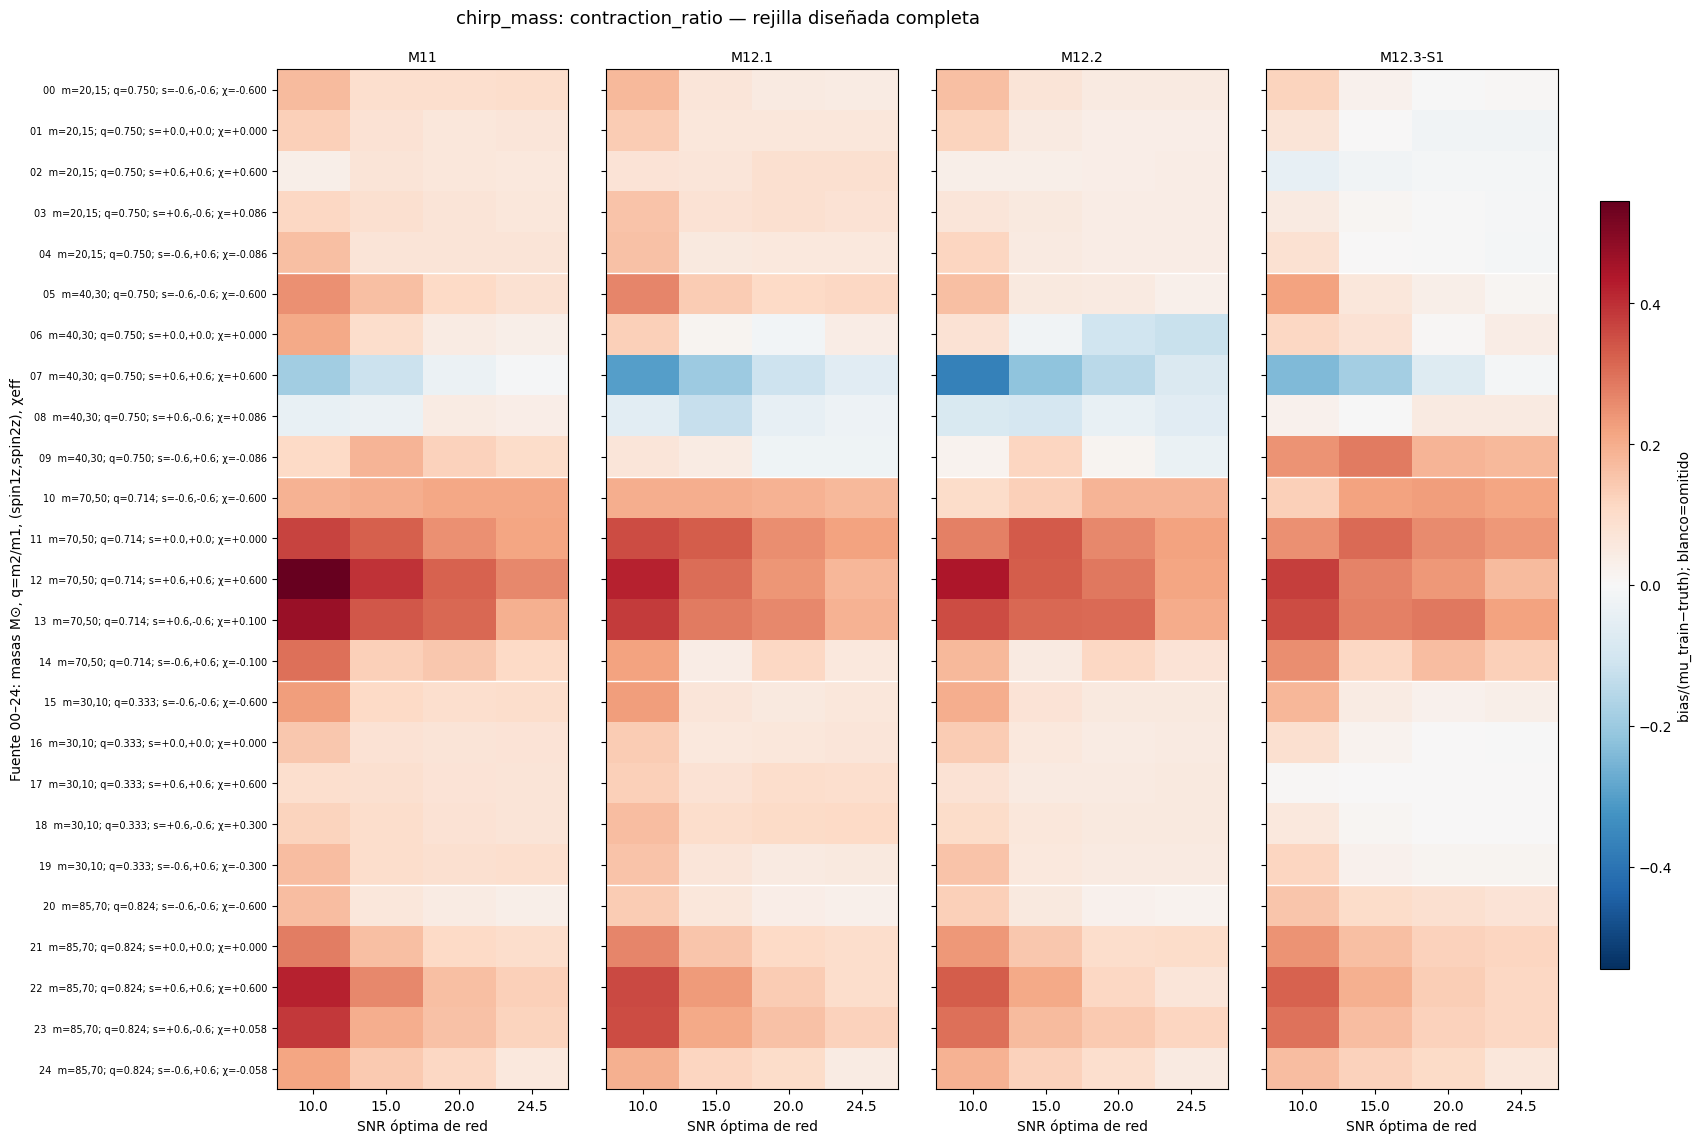

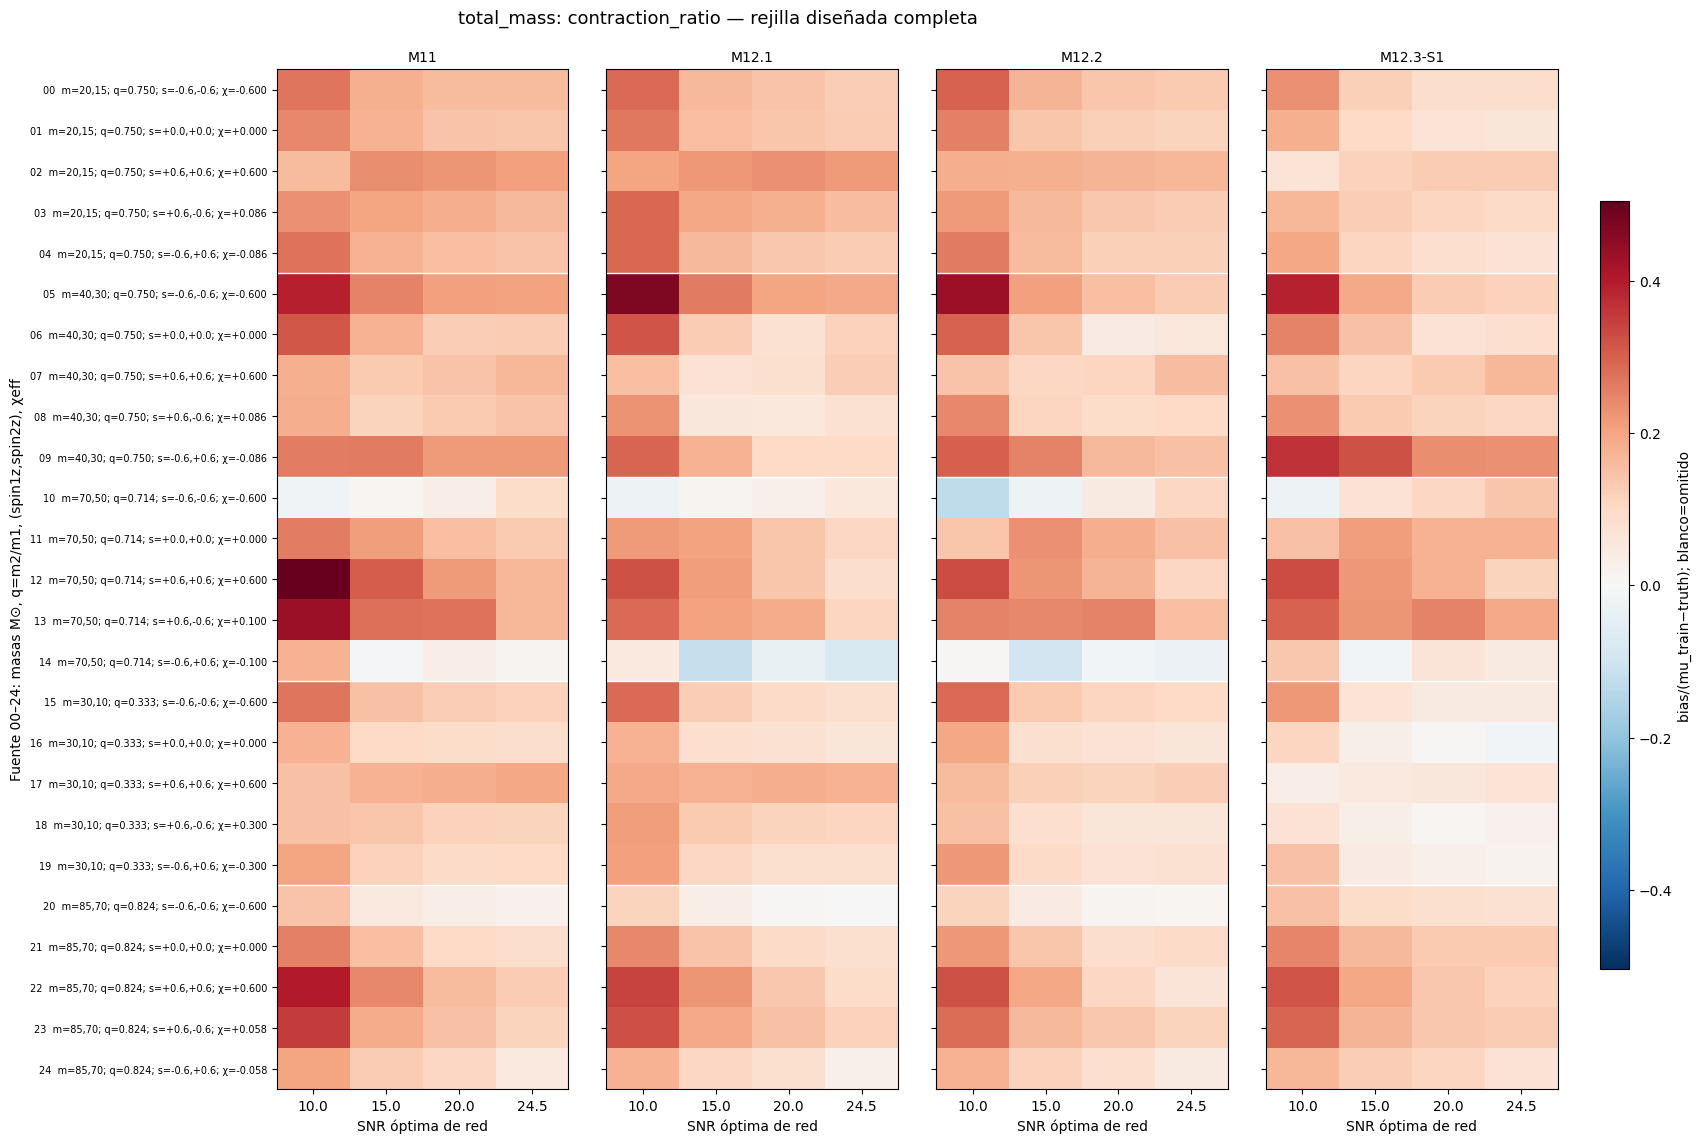

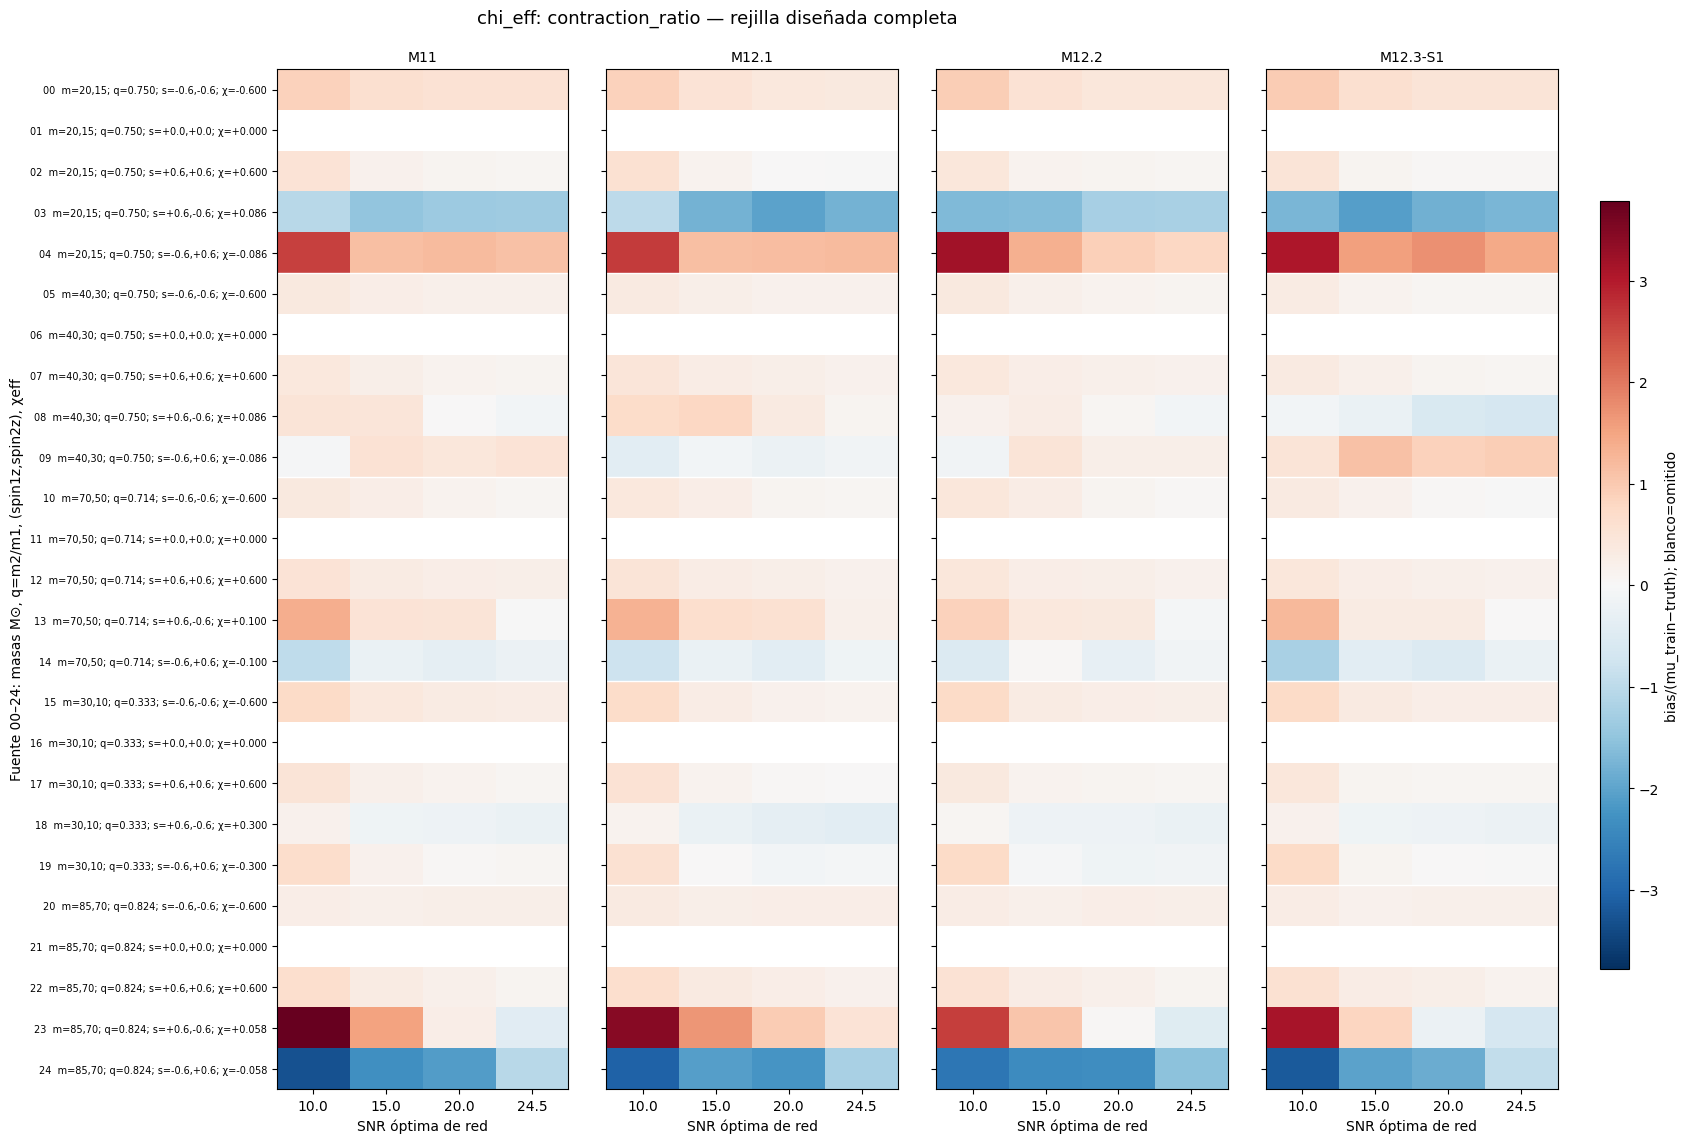

In [10]:
contraction = summary.copy()
contraction["G1_train_mean"] = contraction.label.map(dict(zip(LABELS, train_mean)))
contraction["G1_train_std"] = contraction.label.map(dict(zip(LABELS, train_std)))
gap = contraction.G1_train_mean - contraction.truth
contraction["near_train_mean"] = abs(gap) <= .01*contraction.G1_train_std
contraction["toward_mean_direction"] = contraction.bias*gap > 0
contraction["distance_reduction"] = abs(gap) - abs(contraction.mean_prediction-contraction.G1_train_mean)
contraction["closer_to_mean"] = contraction.distance_reduction > 0
contraction["crosses_mean"] = (contraction.mean_prediction-contraction.G1_train_mean)*(contraction.truth-contraction.G1_train_mean) < 0
contraction["contraction_ratio"] = contraction.bias/gap.where(~contraction.near_train_mean)
lo = contraction.bias_ci_low/gap.where(~contraction.near_train_mean)
hi = contraction.bias_ci_high/gap.where(~contraction.near_train_mean)
contraction["contraction_ratio_ci_low"] = np.minimum(lo, hi)
contraction["contraction_ratio_ci_high"] = np.maximum(lo, hi)
contraction_summary = contraction.groupby(["label", "model", "target_snr"]).agg(
    sources=("source_id", "size"), toward_mean=("toward_mean_direction", "sum"),
    closer_to_mean=("closer_to_mean", "sum"), crosses_mean=("crosses_mean", "sum"),
    omitted_ratio=("near_train_mean", "sum"), median_ratio=("contraction_ratio", "median"))
with pd.option_context("display.max_rows", 48): display(contraction_summary)
for label in LABELS:
    heatmaps(contraction, "contraction_ratio", label, signed=True,
             color_unit="bias/(mu_train−truth); blanco=omitido")

## 6. Diferencias emparejadas de checkpoints

Se usan las 1.800 filas precomputadas y seis parejas, sin bootstrap nuevo. Convención **a−b**: para RMSE/varianza/|bias|, negativo favorece a; positivo favorece b. En sesgo firmado, negativo es desplazamiento hacia abajo, no mejor precisión.

IC puntuales aproximados: la envolvente Bonferroni de |bias| combina dos intervalos por contraste y no corrige toda la rejilla. Contar IC que excluyen cero no es un test global ni selección de ganador poblacional. Los mapas muestran todas las parejas de sesgo y RMSE.


conditions  a_lower_rmse  b_lower_rmse  \
label      pair                                                       
chi_eff    M11 − M12.1              100            48            52   
           M11 − M12.2              100            51            49   
           M11 − M12.3-S1           100            53            47   
           M12.1 − M12.2            100            56            44   
           M12.1 − M12.3-S1         100            59            41   
           M12.2 − M12.3-S1         100            58            42   
chirp_mass M11 − M12.1              100            34            66   
           M11 − M12.2              100            24            76   
           M11 − M12.3-S1           100            34            66   
           M12.1 − M12.2            100            35            65   
           M12.1 − M12.3-S1         100            40            60   
           M12.2 − M12.3-S1         100            41            59   
total_mass M11 − M12.1              100            22            78   
           M11 − M12.2              100            22            78   
           M11 − M12.3-S1           100            34            66   
           M12.1 − M12.2            100            40            60   
           M12.1 − M12.3-S1         100            46            54   
           M12.2 − M12.3-S1         100            49            51   

                             pointwise_ci_excludes_zero  mean_delta_rmse  \
label      pair                                                            
chi_eff    M11 − M12.1                               38         0.002410   
           M11 − M12.2                               48         0.000104   
           M11 − M12.3-S1                            51        -0.002060   
           M12.1 − M12.2                             53        -0.002306   
           M12.1 − M12.3-S1                          48        -0.004469   
           M12.2 − M12.3-S1                          40        -0.002164   
chirp_mass M11 − M12.1                               60         0.097641   
           M11 − M12.2                               56         0.325055   
           M11 − M12.3-S1                            65         0.439326   
           M12.1 − M12.2                             47         0.227414   
           M12.1 − M12.3-S1                          64         0.341685   
           M12.2 − M12.3-S1                          54         0.114271   
total_mass M11 − M12.1                               54         0.348788   
           M11 − M12.2                               58         0.842134   
           M11 − M12.3-S1                            74         1.427266   
           M12.1 − M12.2                             51         0.493347   
           M12.1 − M12.3-S1                          82         1.078479   
           M12.2 − M12.3-S1                          65         0.585132   

                             mean_delta_bias  mean_delta_absolute_bias  
label      pair                                                         
chi_eff    M11 − M12.1              0.008057                 -0.000327  
           M11 − M12.2             -0.003024                  0.006147  
           M11 − M12.3-S1          -0.010419                  0.004098  
           M12.1 − M12.2           -0.011081                  0.006474  
           M12.1 − M12.3-S1        -0.018476                  0.004425  
           M12.2 − M12.3-S1        -0.007395                 -0.002049  
chirp_mass M11 − M12.1             -0.098827                  0.243794  
           M11 − M12.2              0.084460                  0.569569  
           M11 − M12.3-S1           0.448062                  0.785214  
           M12.1 − M12.2            0.183286                  0.325776  
           M12.1 − M12.3-S1         0.546889                  0.541420  
           M12.2 − M12.3-S1         0.363603                  0.215645  
total_mass M11 − M12.1             -0.339731                  0.6

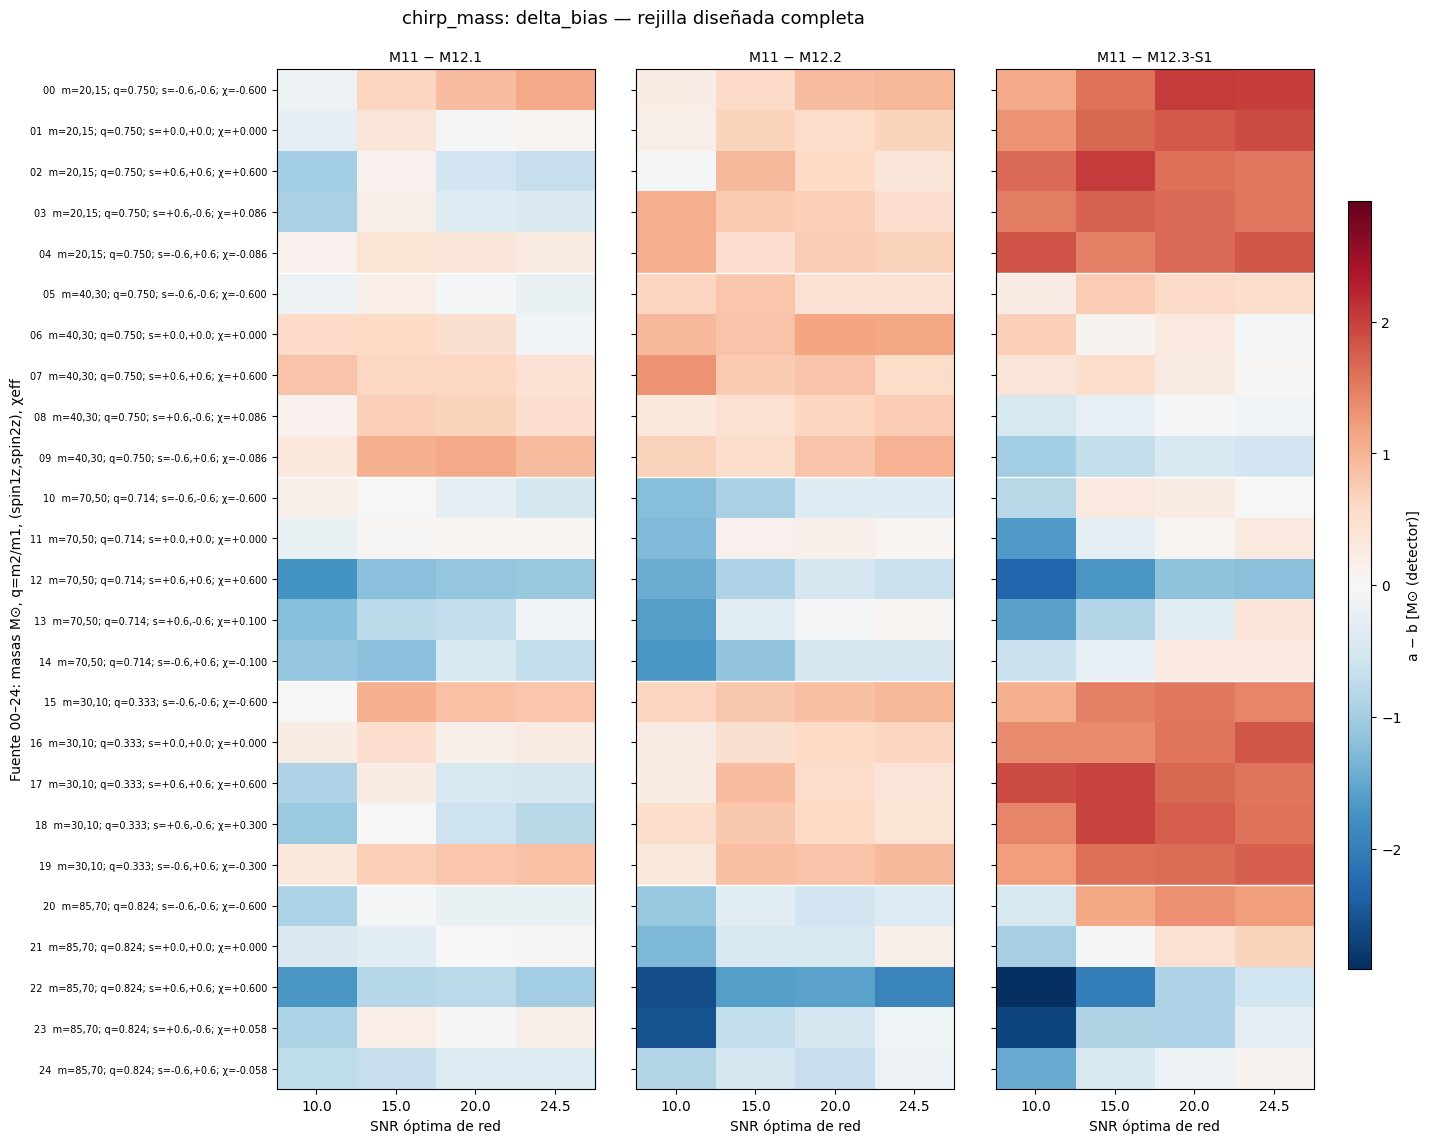

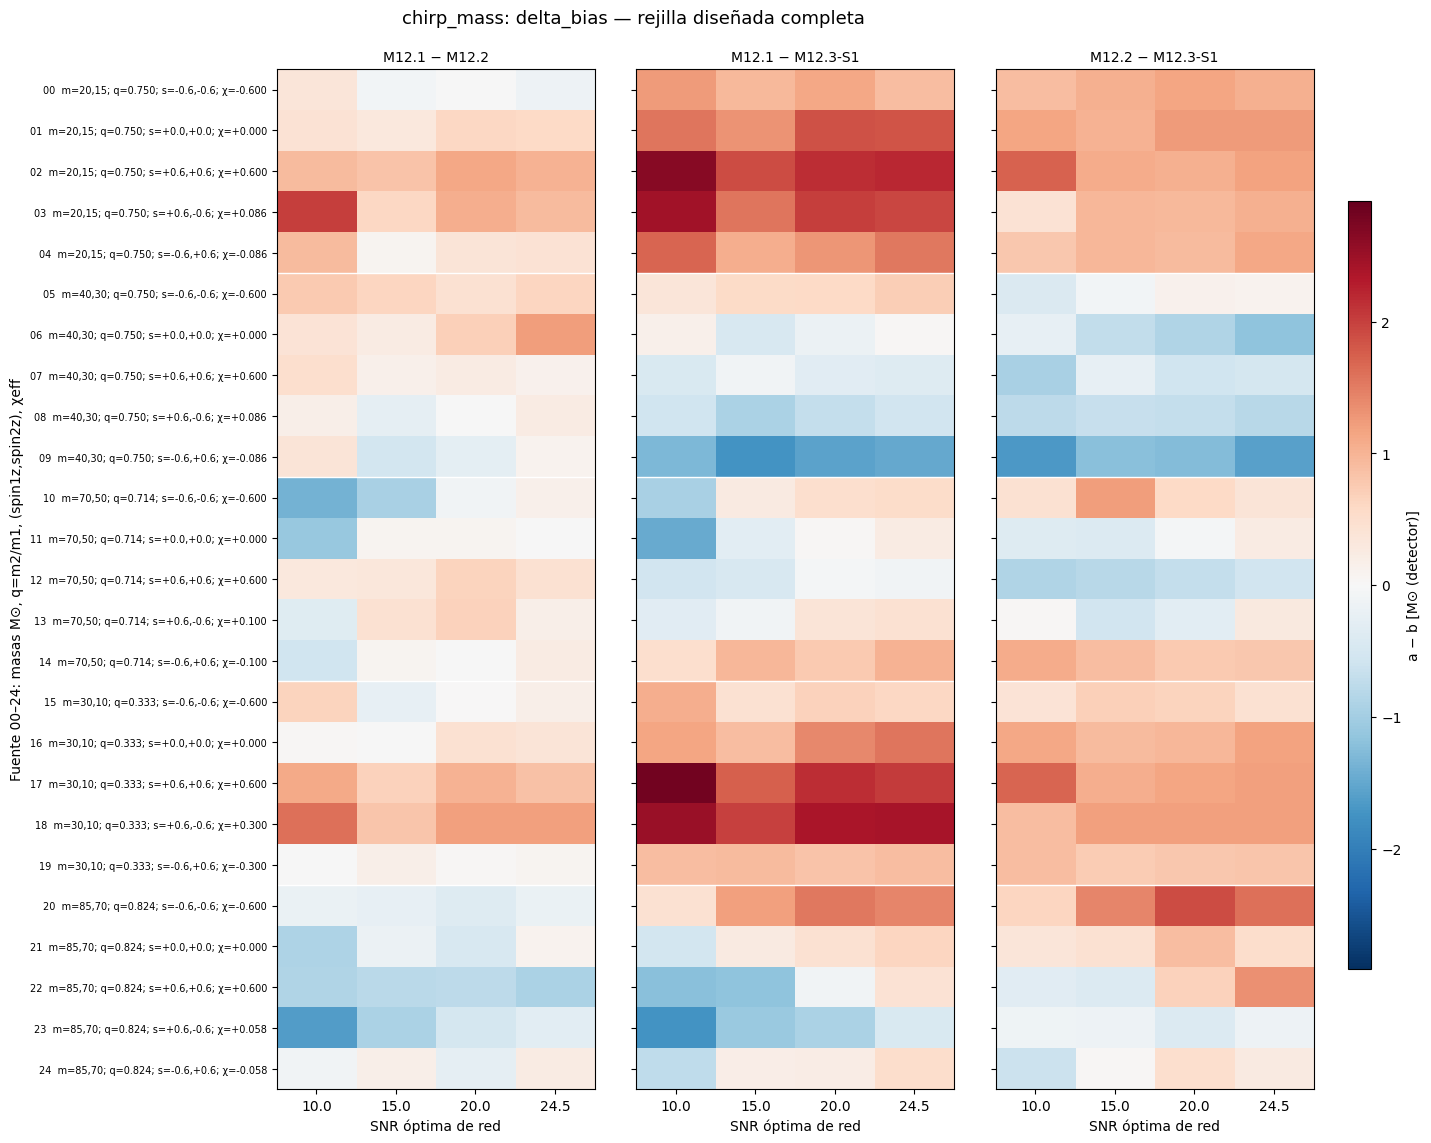

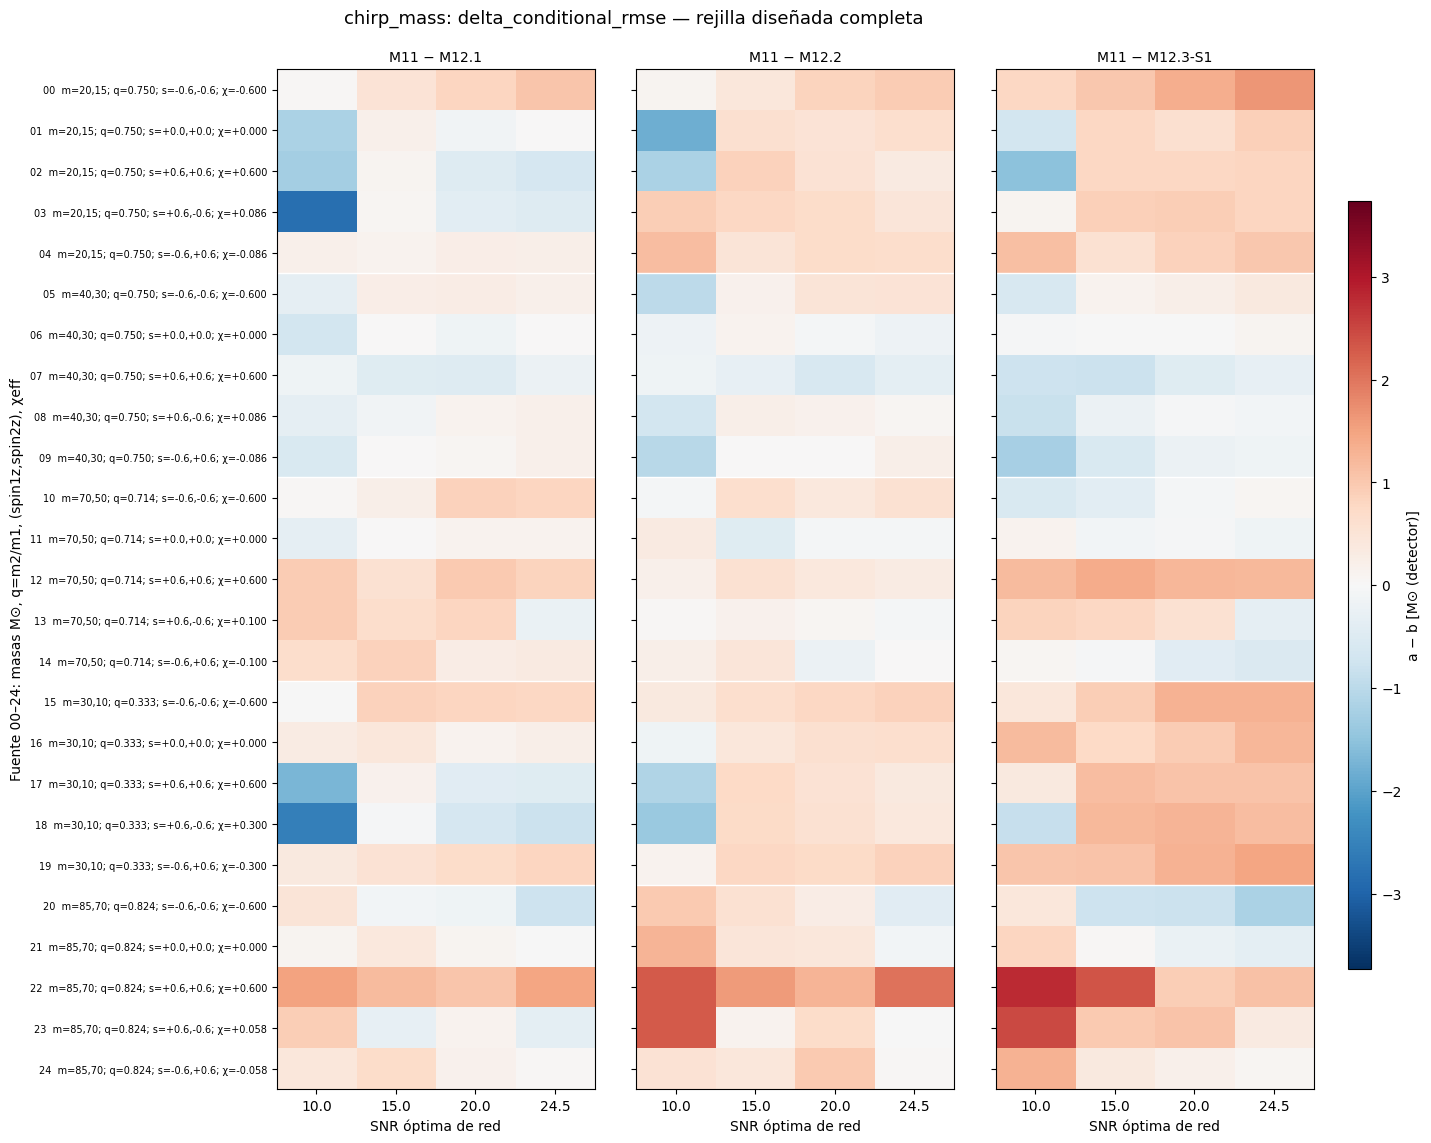

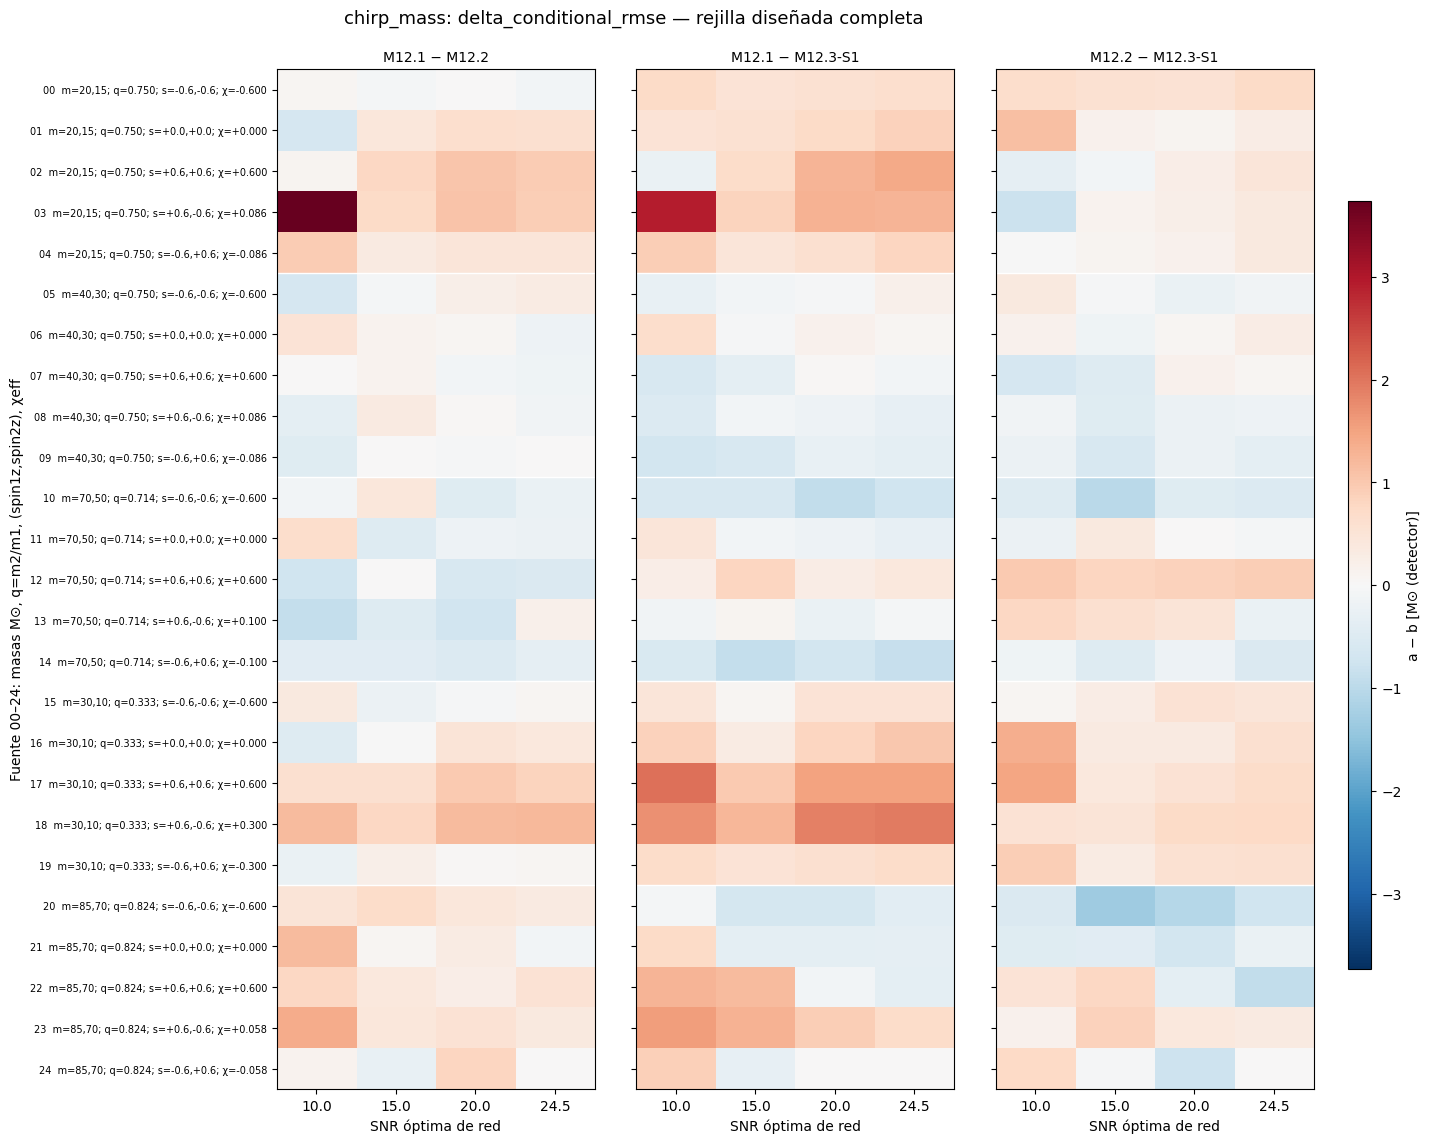

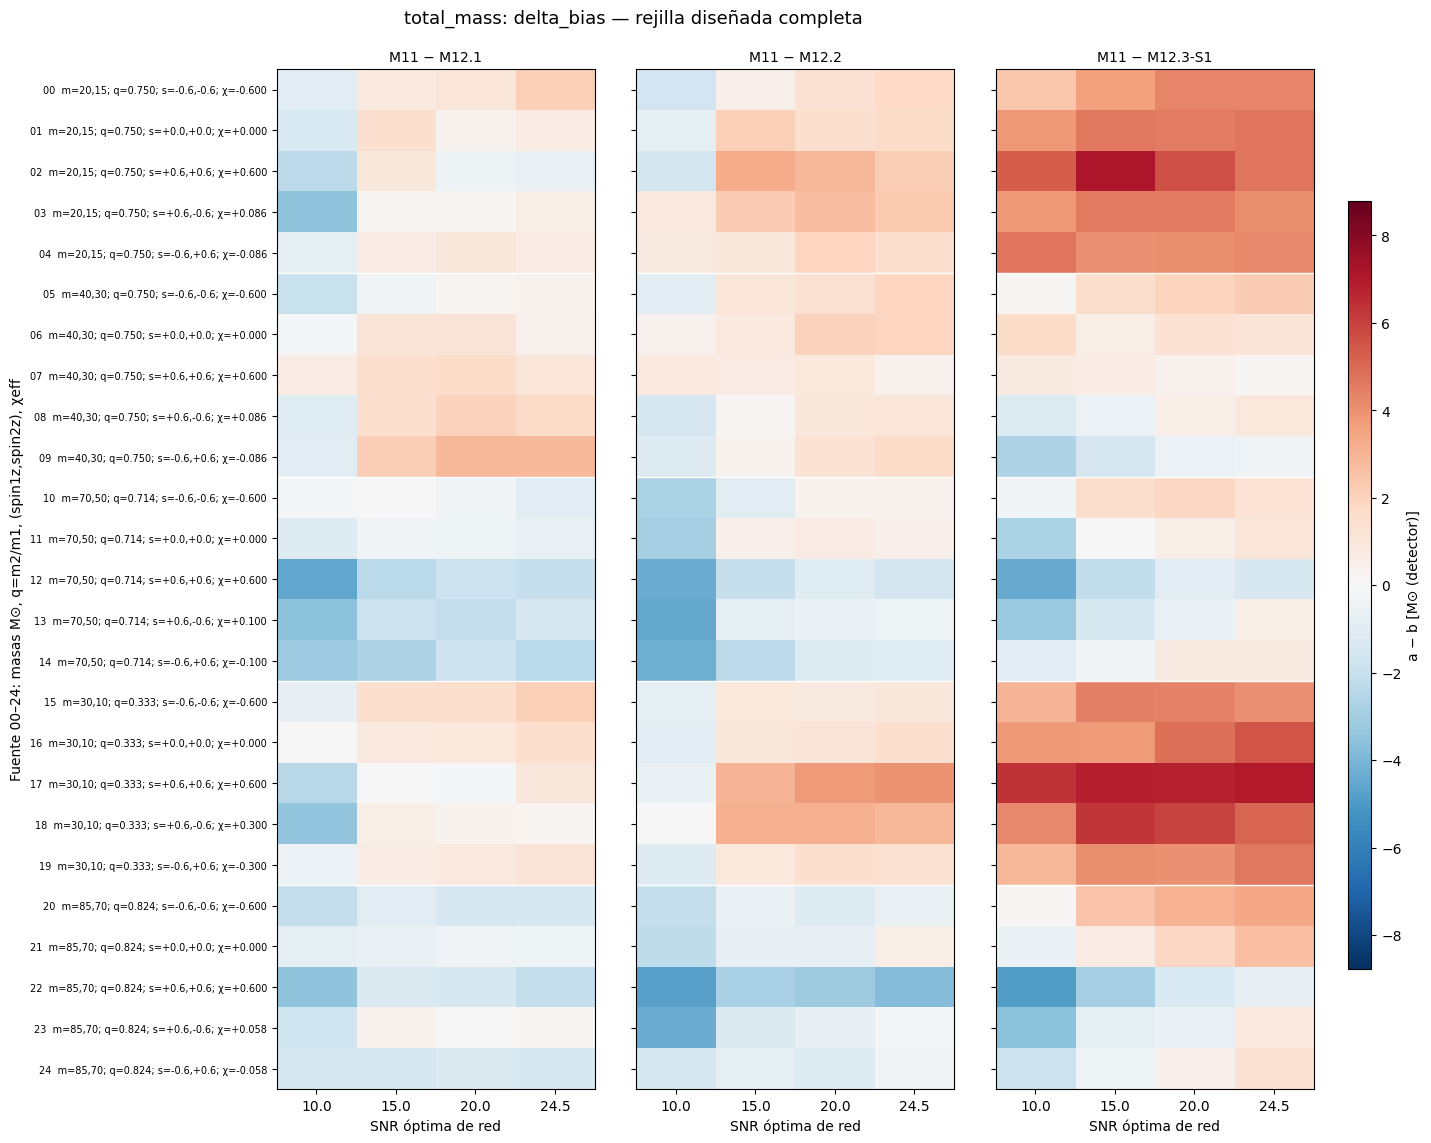

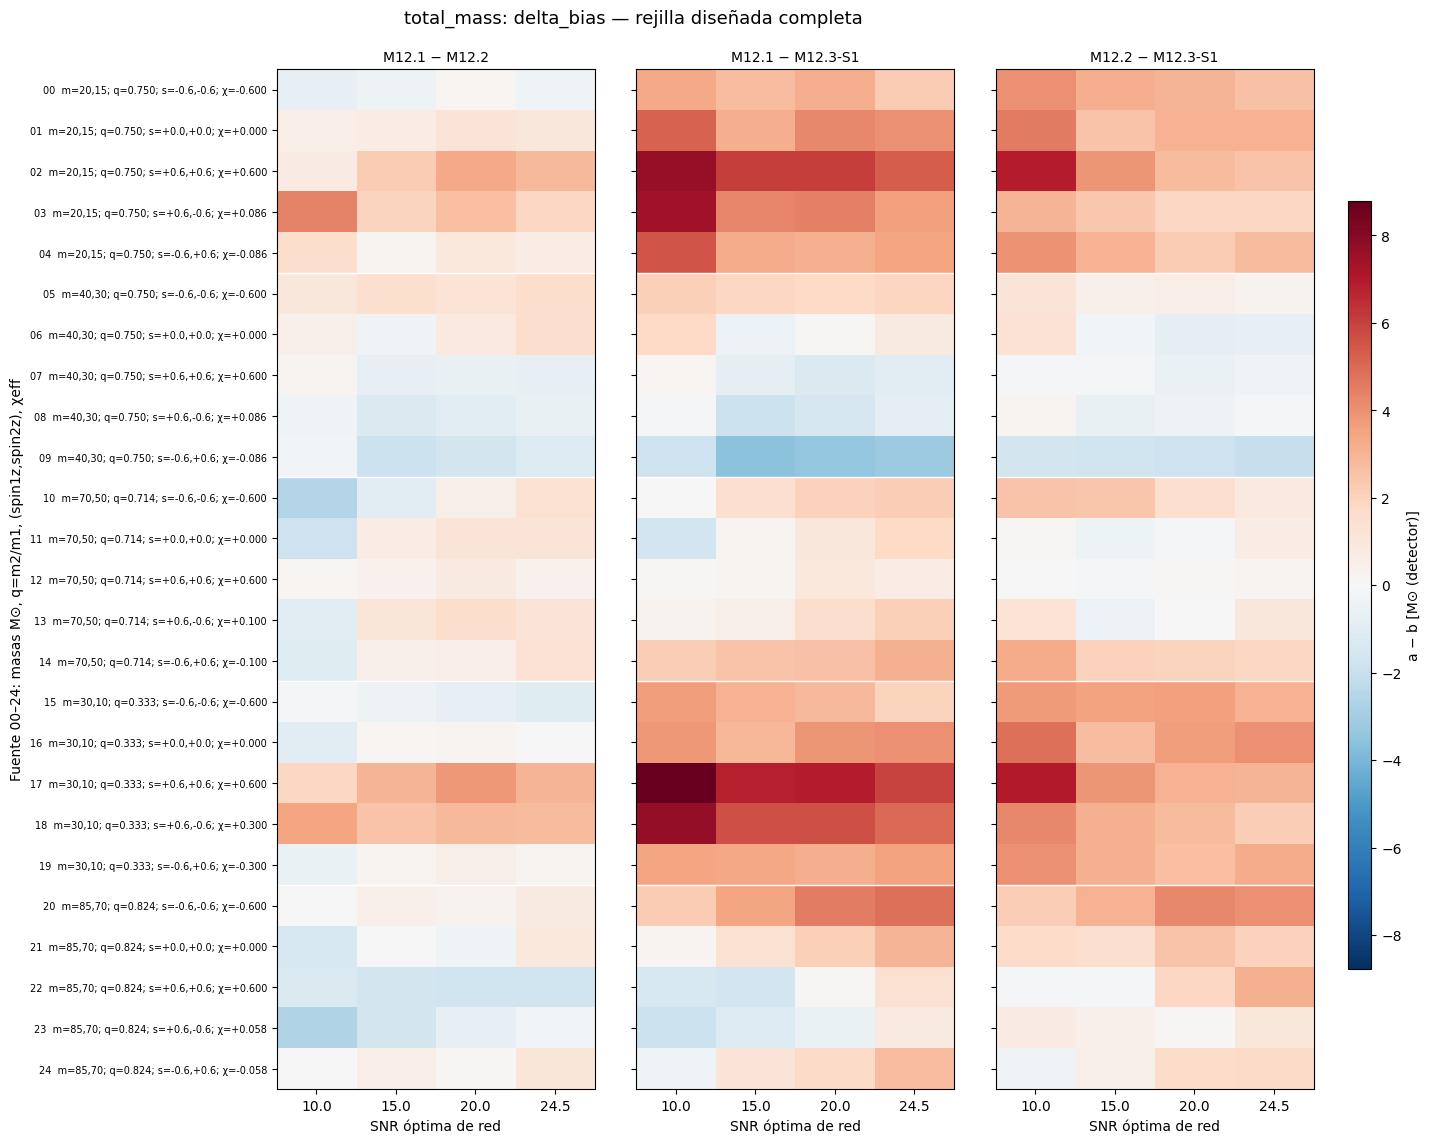

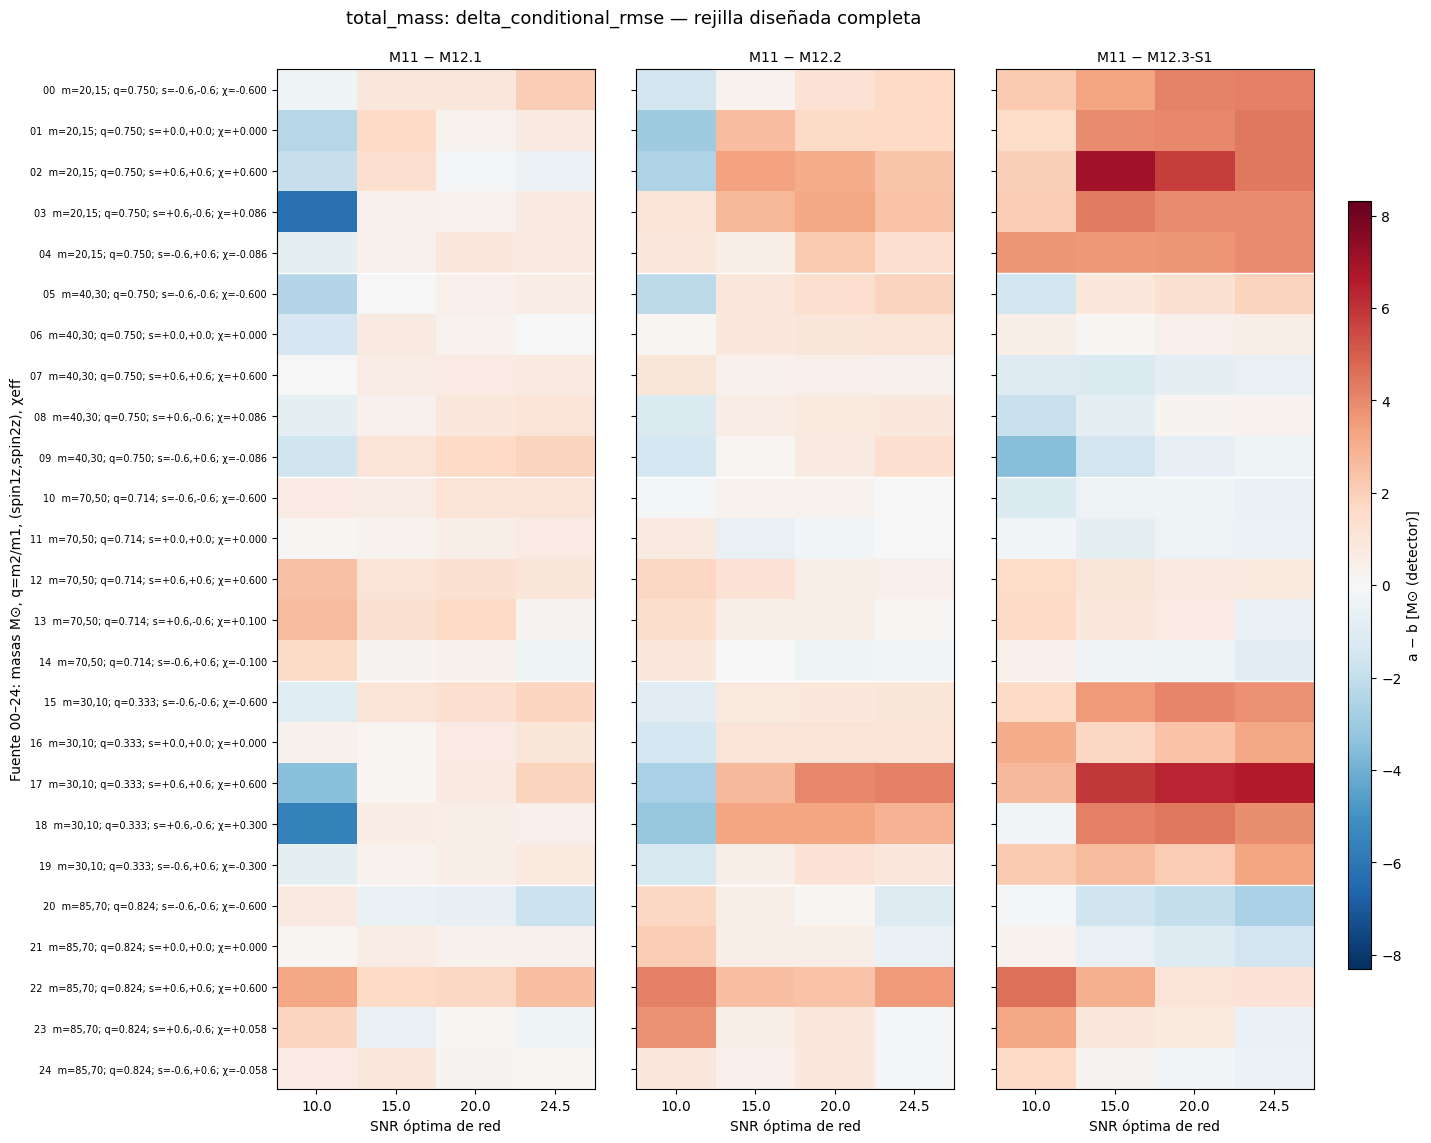

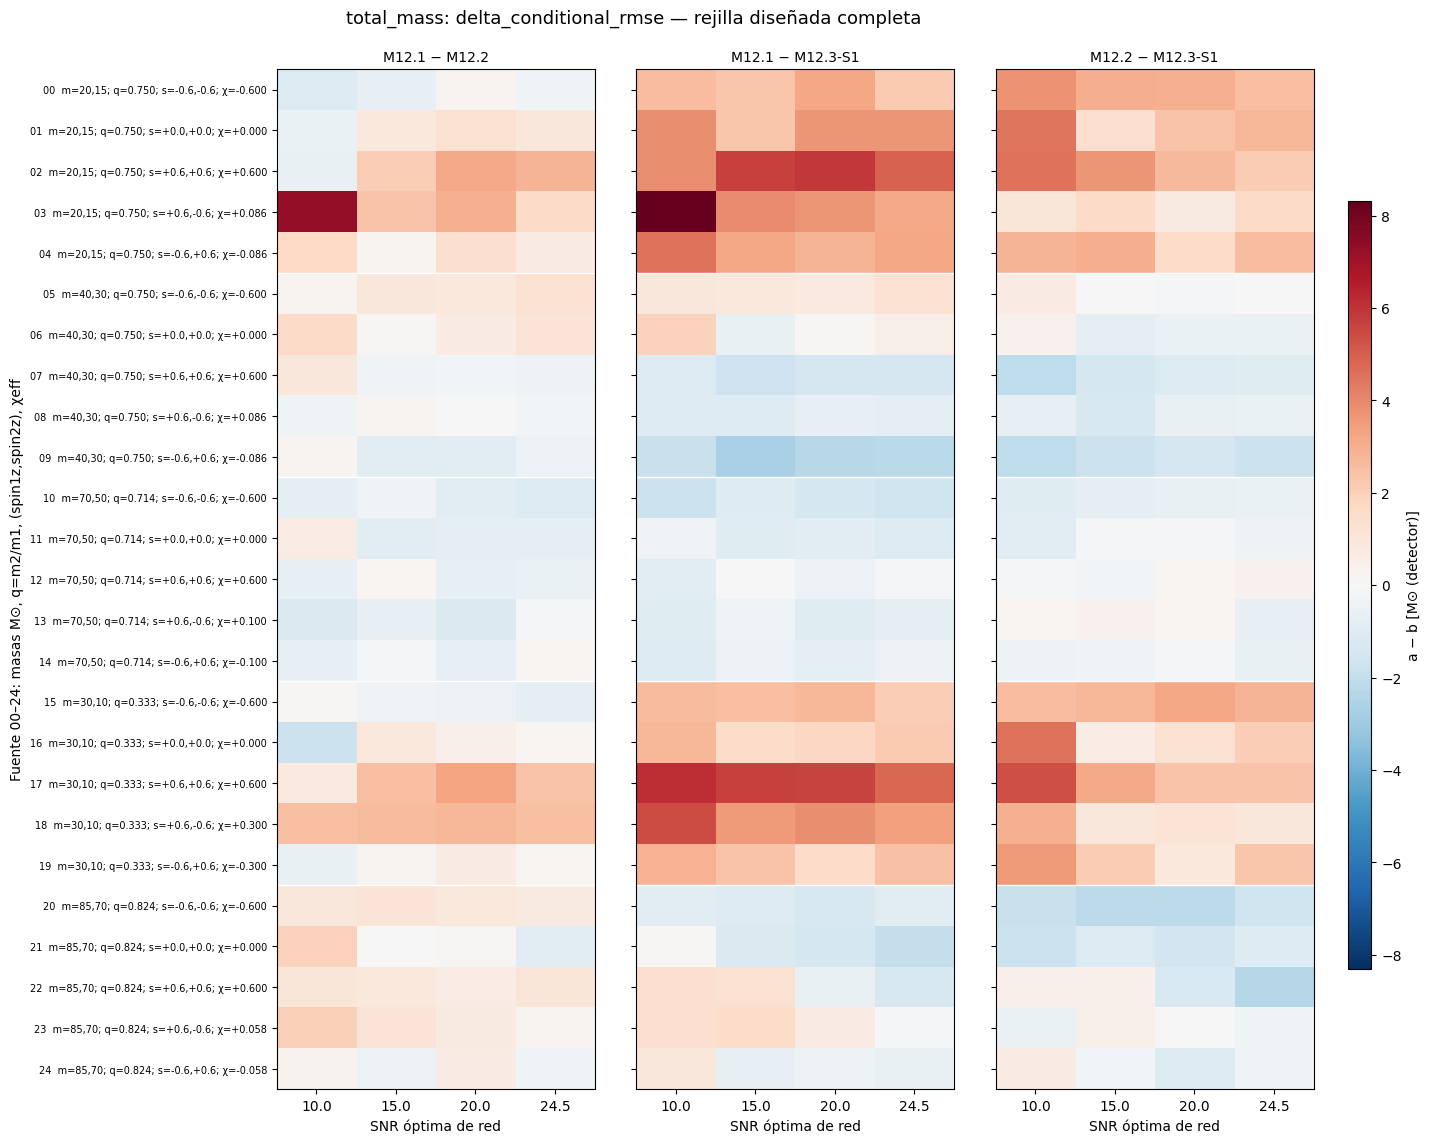

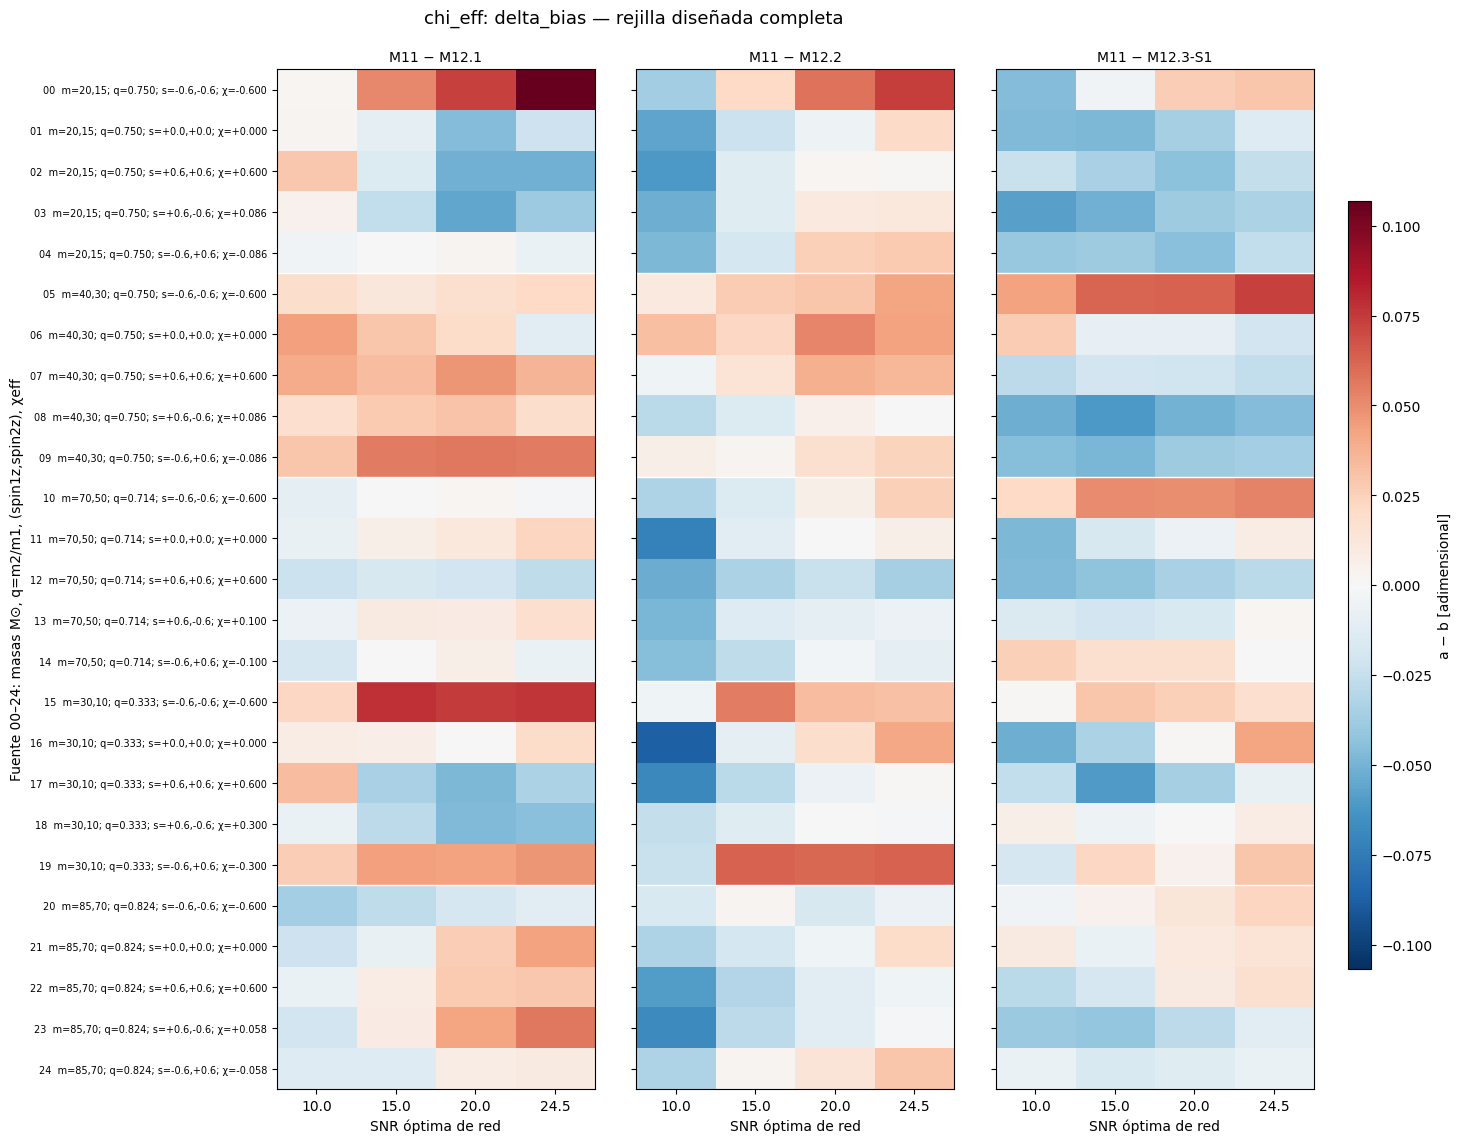

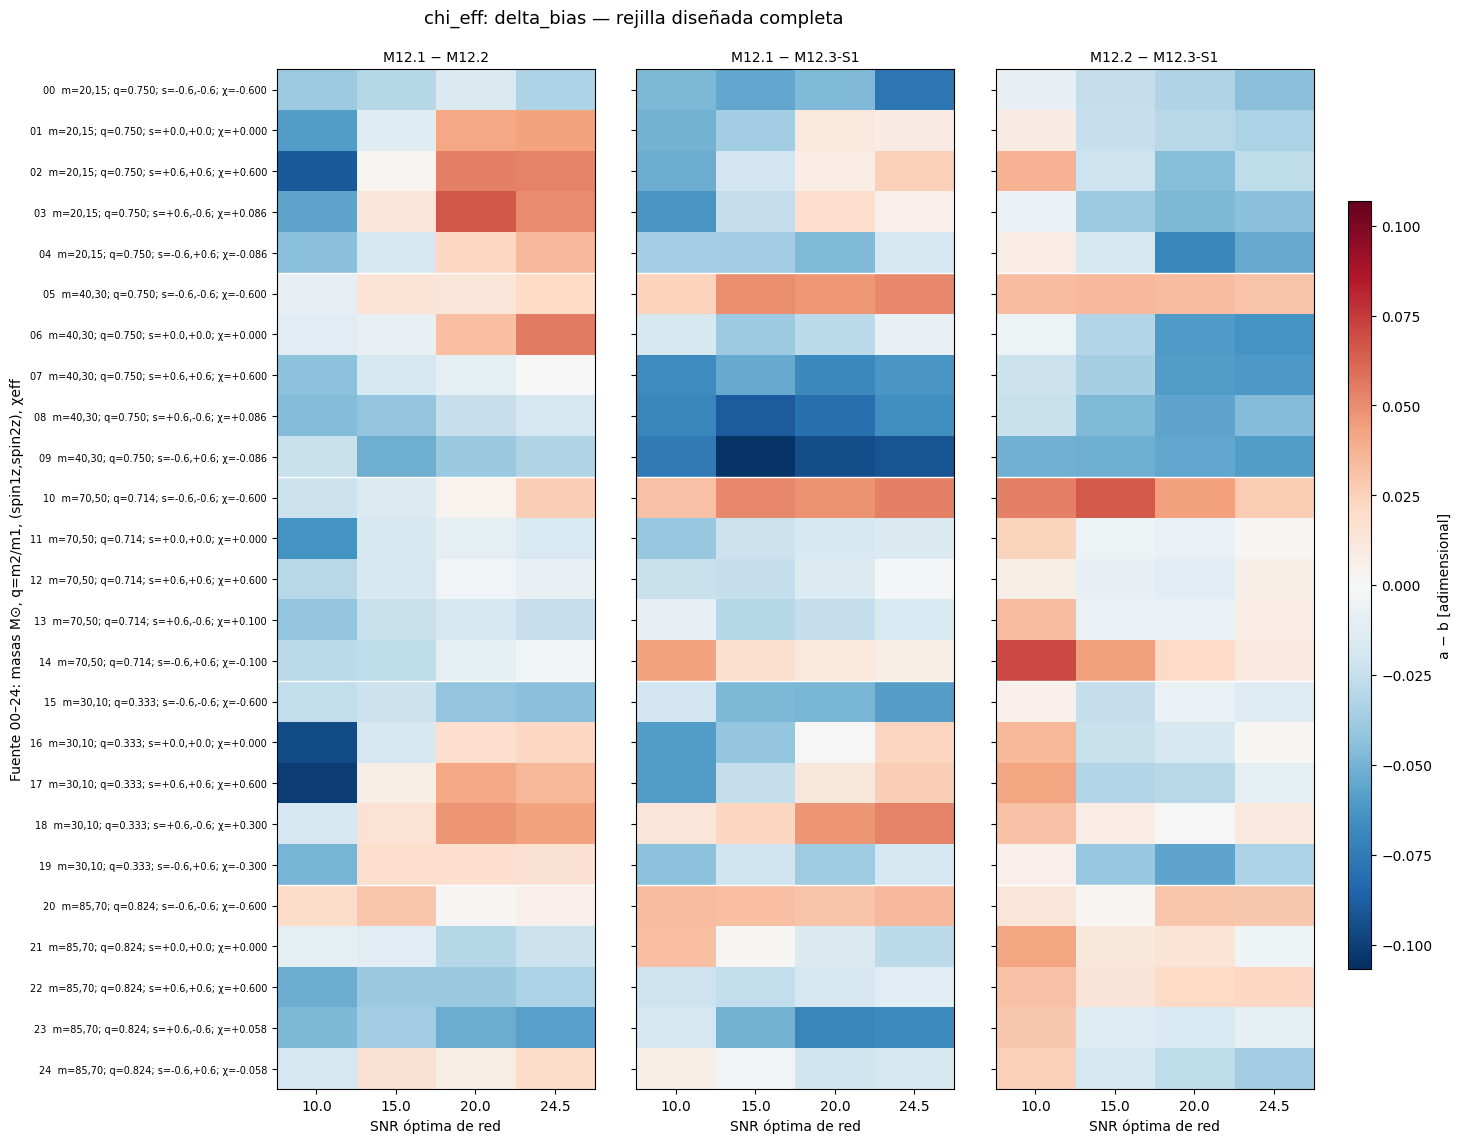

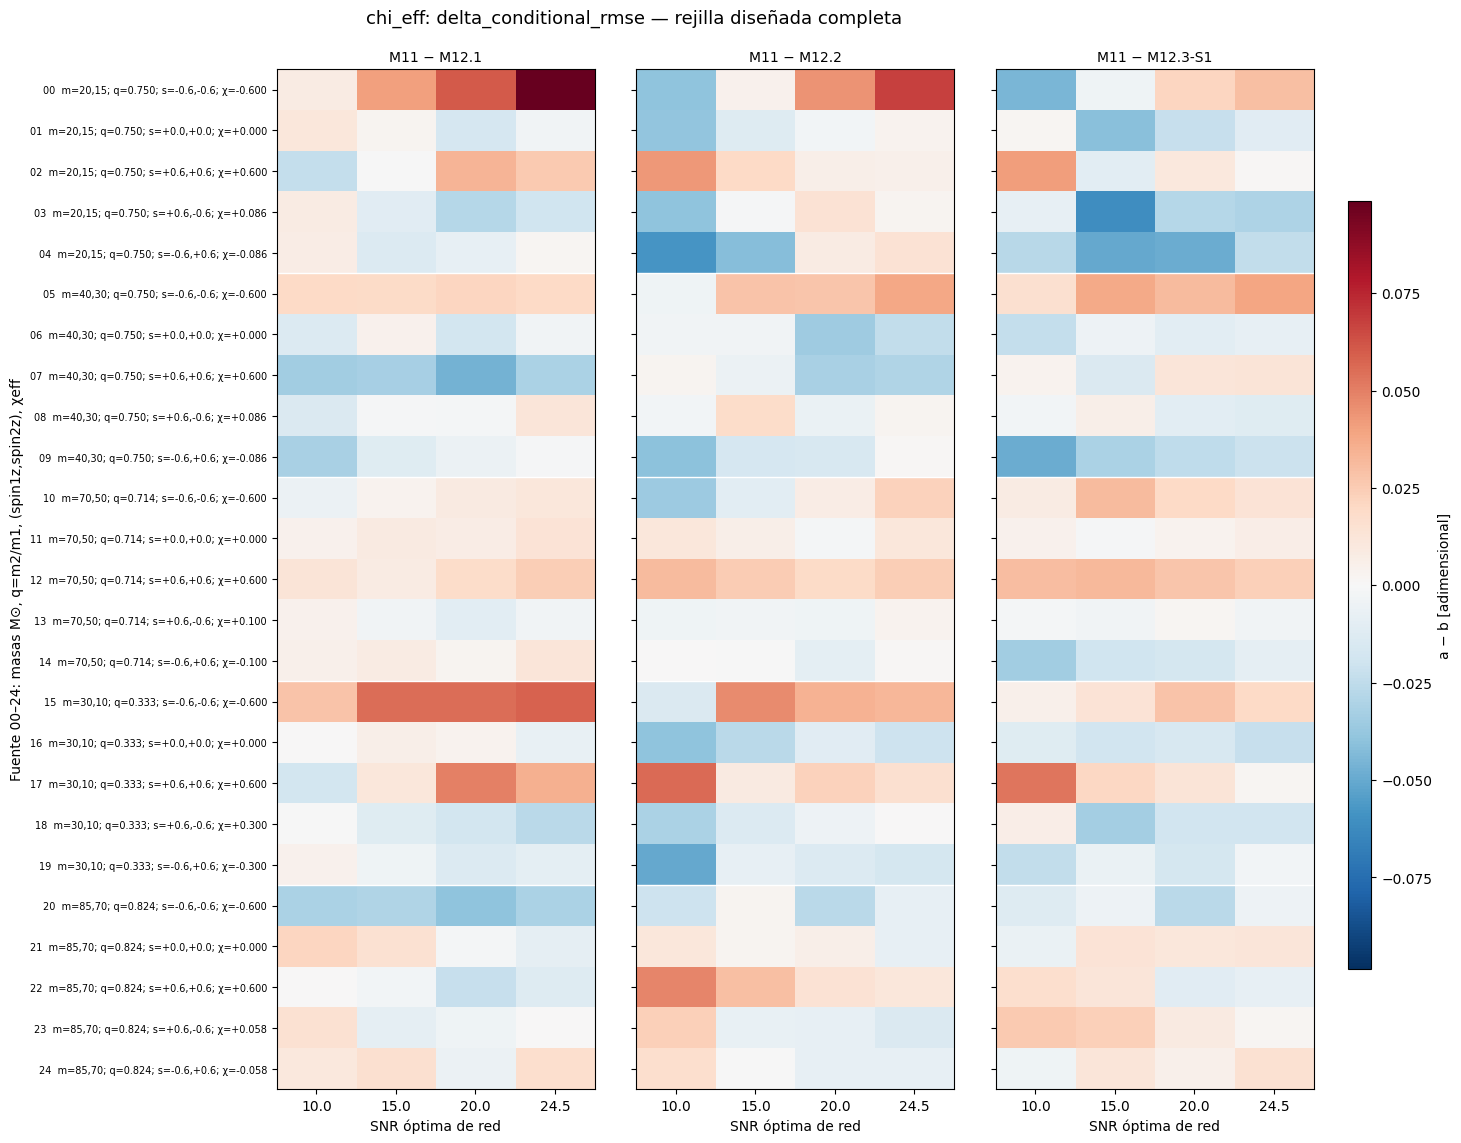

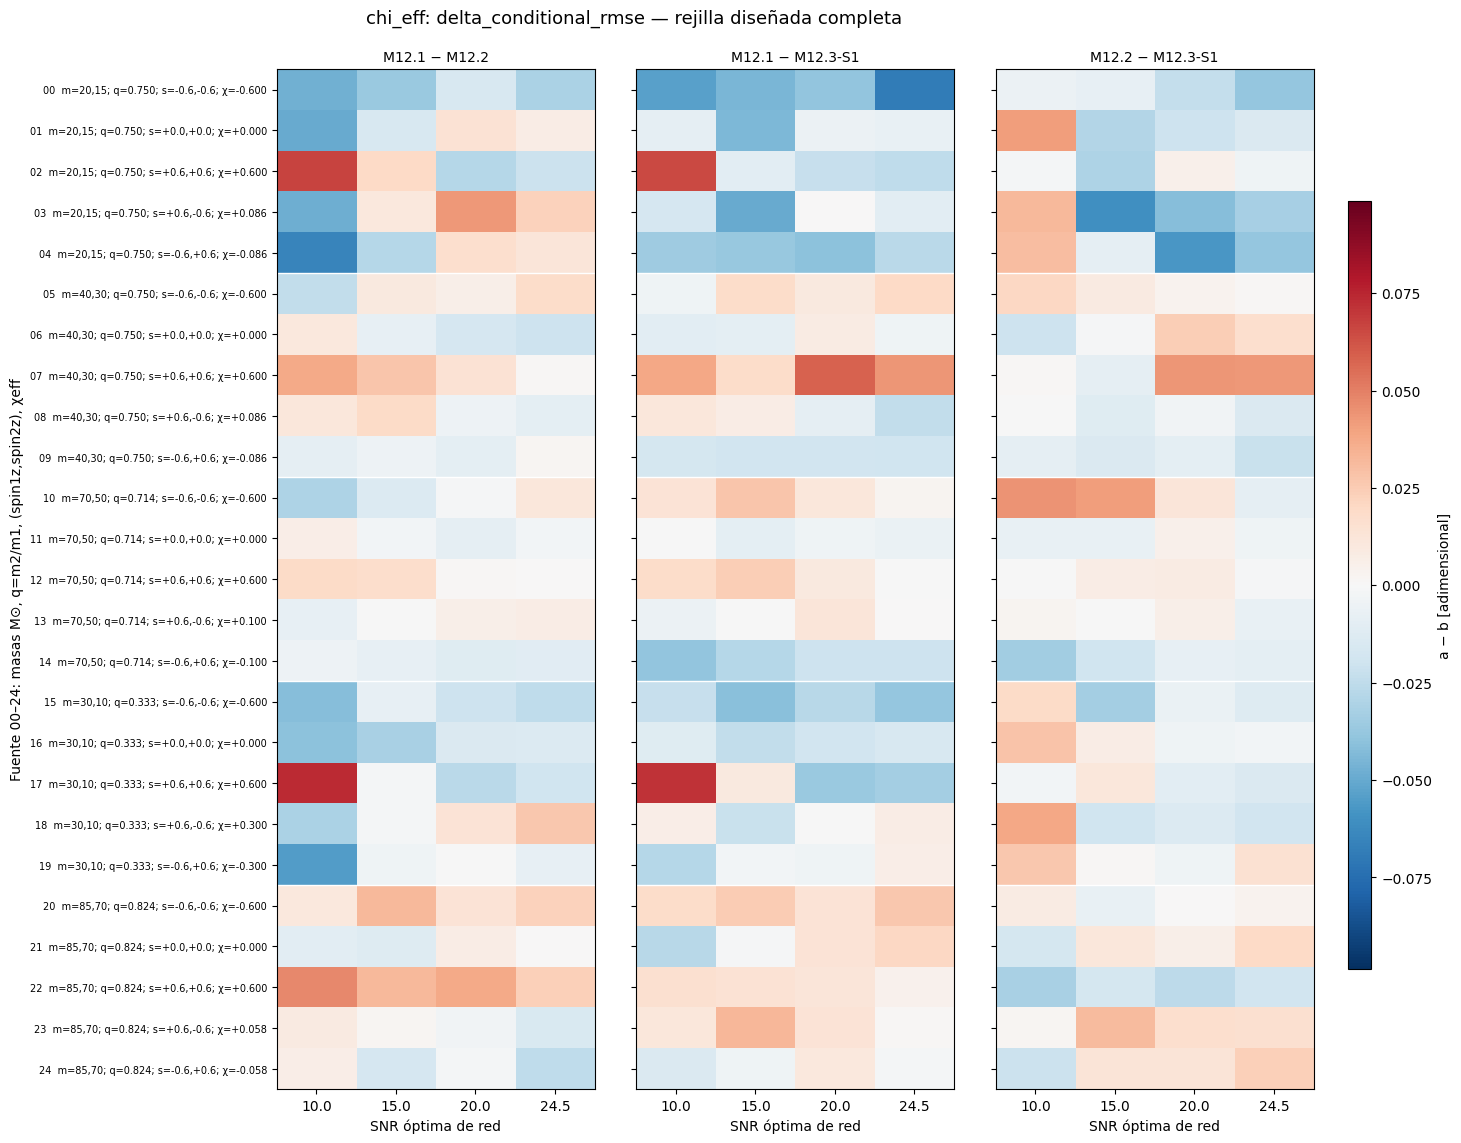

In [11]:
paired["pair"] = paired.model_a + " − " + paired.model_b
PAIR_NAMES = [a+" − "+b for a, b in PAIRS]
paired["rmse_ci_excludes_zero"] = paired.delta_conditional_rmse_ci_low.gt(0) | paired.delta_conditional_rmse_ci_high.lt(0)
pair_summary = paired.groupby(["label", "pair"]).agg(
    conditions=("condition_id", "size"),
    a_lower_rmse=("delta_conditional_rmse", lambda v: int((v < 0).sum())),
    b_lower_rmse=("delta_conditional_rmse", lambda v: int((v > 0).sum())),
    pointwise_ci_excludes_zero=("rmse_ci_excludes_zero", "sum"),
    mean_delta_rmse=("delta_conditional_rmse", "mean"),
    mean_delta_bias=("delta_bias", "mean"), mean_delta_absolute_bias=("delta_absolute_bias", "mean"))
display(pair_summary)
for label in LABELS:
    for metric in ("delta_bias", "delta_conditional_rmse"):
        # Dos páginas de tres parejas, misma escala global por target/métrica.
        bound = max(float(abs(paired.loc[paired.label.eq(label), metric]).max()), 1e-12)
        for page, start in enumerate((0, 3), 1):
            heatmaps(paired, metric, label, column="pair", panels=PAIR_NAMES[start:start+3], signed=True,
                     fixed_limits=(-bound, bound), name=f"{label}_{metric}_pairs_page{page}",
                     color_unit=f"a − b [{UNITS[label]}]")

## 7. Convergencia finita y colas

R=16,32,64,128 usa los primeros R IDs de la misma secuencia: prefijos anidados, no réplicas independientes. R=128 es referencia interna disponible, no verdad ni garantía de convergencia. Diferencias y anchuras de IC se escalan por desviaciones train-only; las tablas originales conservan unidades físicas.

Cada línea tenue representa una condición fuente/SNR, sin selección. La línea negra es la mediana descriptiva de la rejilla, no un IC o estimador poblacional. Se examinan también cambios de contrastes emparejados. Los cuantiles y máximos son descriptivos: el percentil 95 tiene sólo unas seis observaciones de cola con R=128, y menos con R=16.

Los cambios de signo cerca de cero pueden ser pequeños; no constituyen por sí mismos una inestabilidad científicamente relevante. La anchura de IC no debe interpretarse como ancho posterior.


abs_delta_bias_scaled            \
                                       median       max   
label      model    R                                     
chi_eff    M11      16               0.049328  0.226373   
                    32               0.031069  0.173576   
                    64               0.015180  0.100873   
                    128              0.000000  0.000000   
           M12.1    16               0.048815  0.229774   
                    32               0.031087  0.195790   
                    64               0.017903  0.091042   
                    128              0.000000  0.000000   
           M12.2    16               0.050919  0.316243   
                    32               0.034450  0.201151   
                    64               0.020873  0.124882   
                    128              0.000000  0.000000   
           M12.3-S1 16               0.057533  0.314883   
                    32               0.034564  0.169507   
                    64               0.020895  0.078839   
                    128              0.000000  0.000000   
chirp_mass M11      16               0.023707  0.259107   
                    32               0.011860  0.139617   
                    64               0.007524  0.067272   
                    128              0.000000  0.000000   
           M12.1    16               0.021897  0.359517   
                    32               0.010985  0.223749   
                    64               0.006757  0.092198   
                    128              0.000000  0.000000   
           M12.2    16               0.023222  0.178927   
                    32               0.010627  0.137030   
                    64               0.008352  0.075642   
                    128              0.000000  0.000000   
           M12.3-S1 16               0.025406  0.182358   
                    32               0.011747  0.153575   
                    64               0.008427  0.073641   
                    128              0.000000  0.000000   
total_mass M11      16               0.027816  0.300046   
                    32               0.019755  0.130275   
                    64               0.011125  0.064945   
                    128              0.000000  0.000000   
           M12.1    16               0.024706  0.444145   
                    32               0.014504  0.193152   
                    64               0.009809  0.085291   
                    128              0.000000  0.000000   
           M12.2    16               0.026181  0.231508   
                    32               0.011997  0.133462   
                    64               0.010106  0.069089   
                    128              0.000000  0.000000   
           M12.3-S1 16               0.027974  0.231169   
                    32               0.017186  0.158331   
                    64               0.012506  0.067972   
                    128              0.000000  0.000000   

                        abs_delta_conditional_rmse_scaled            \
                                                   median       max   
label      model    R                                                 
chi_eff    M11      16                           0.044125  0.212572   
                    32                           0.029522  0.153968   
                    64                           0.016598  0.082387   
                    128                          0.000000  0.000000   
           M12.1    16                           0.045824  0.279493   
                    32                           0.030043  0.196772   
                    64                           0.013232  0.083324   
                    128                          0.000000  0.000000   
           M12.2    16                           0.046193  0.276322   
                    32                           0.028704  0.165081   
                    64                           0.014422  0.139528   
                    

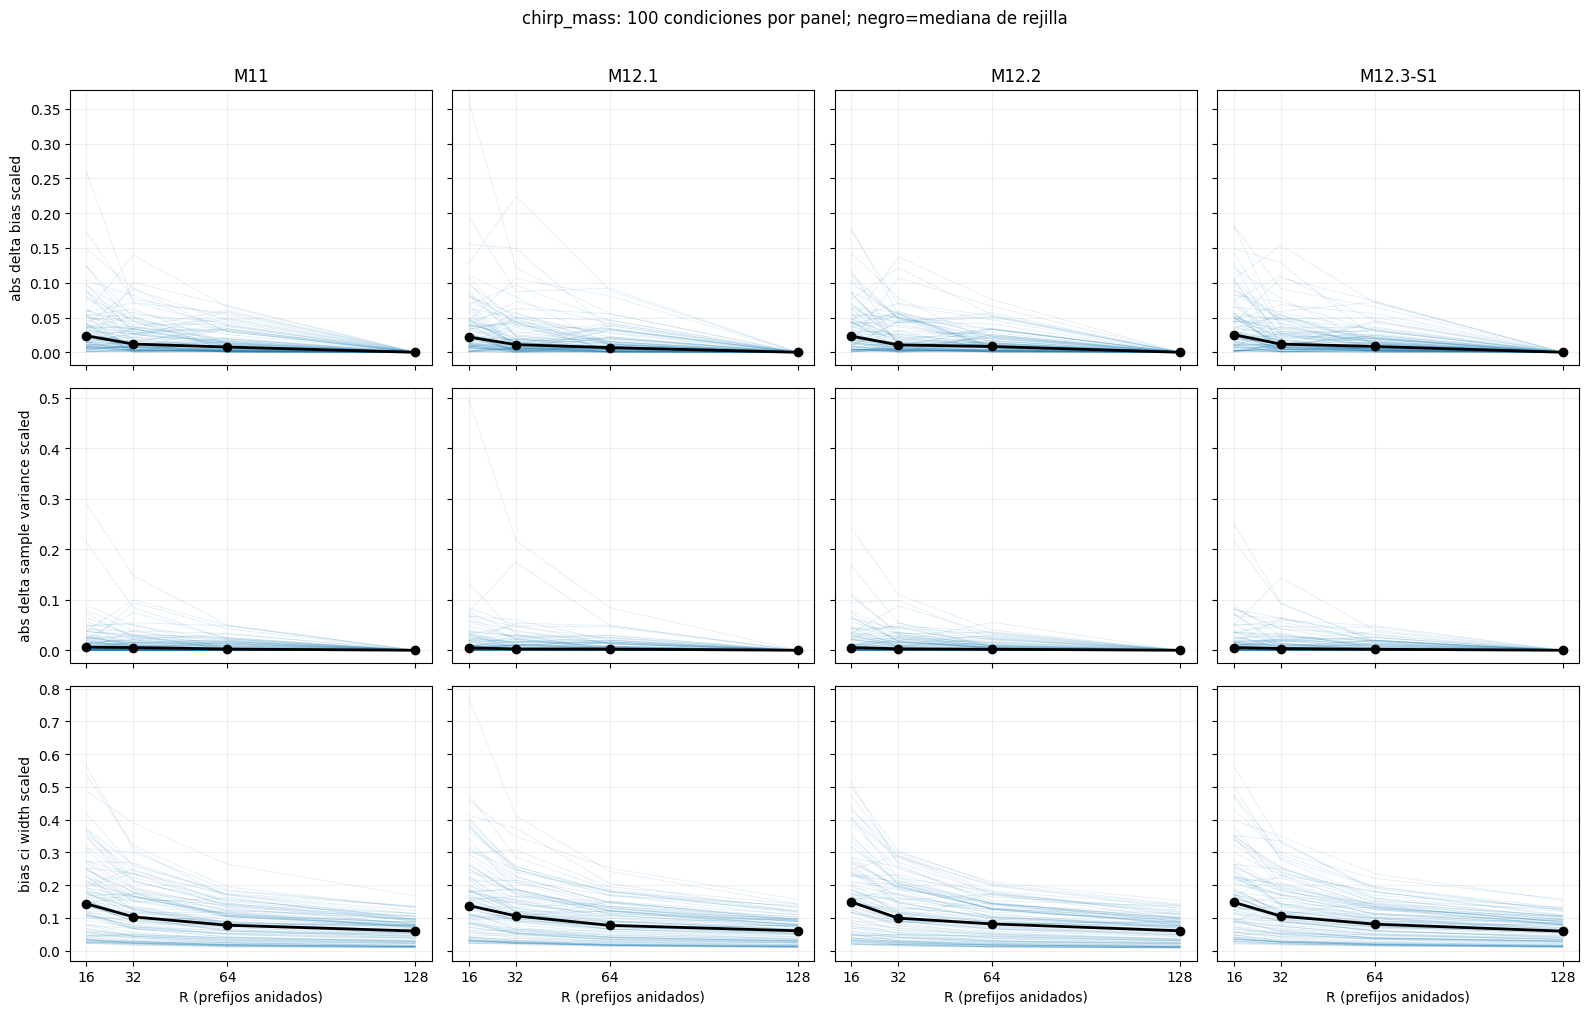

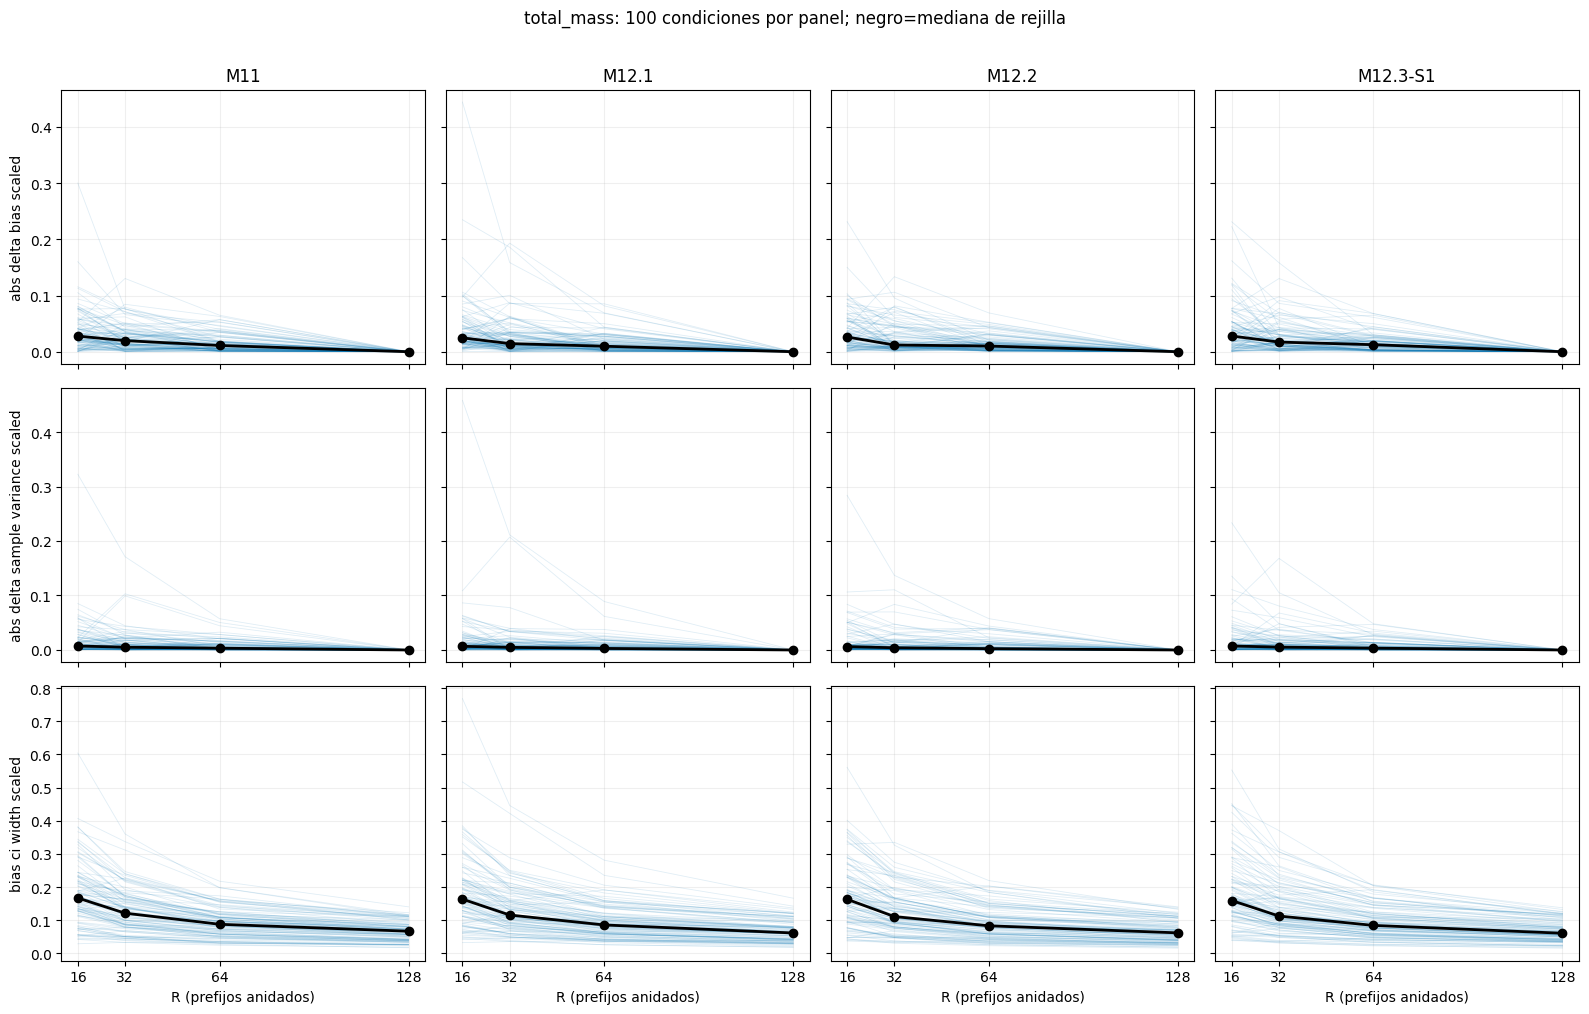

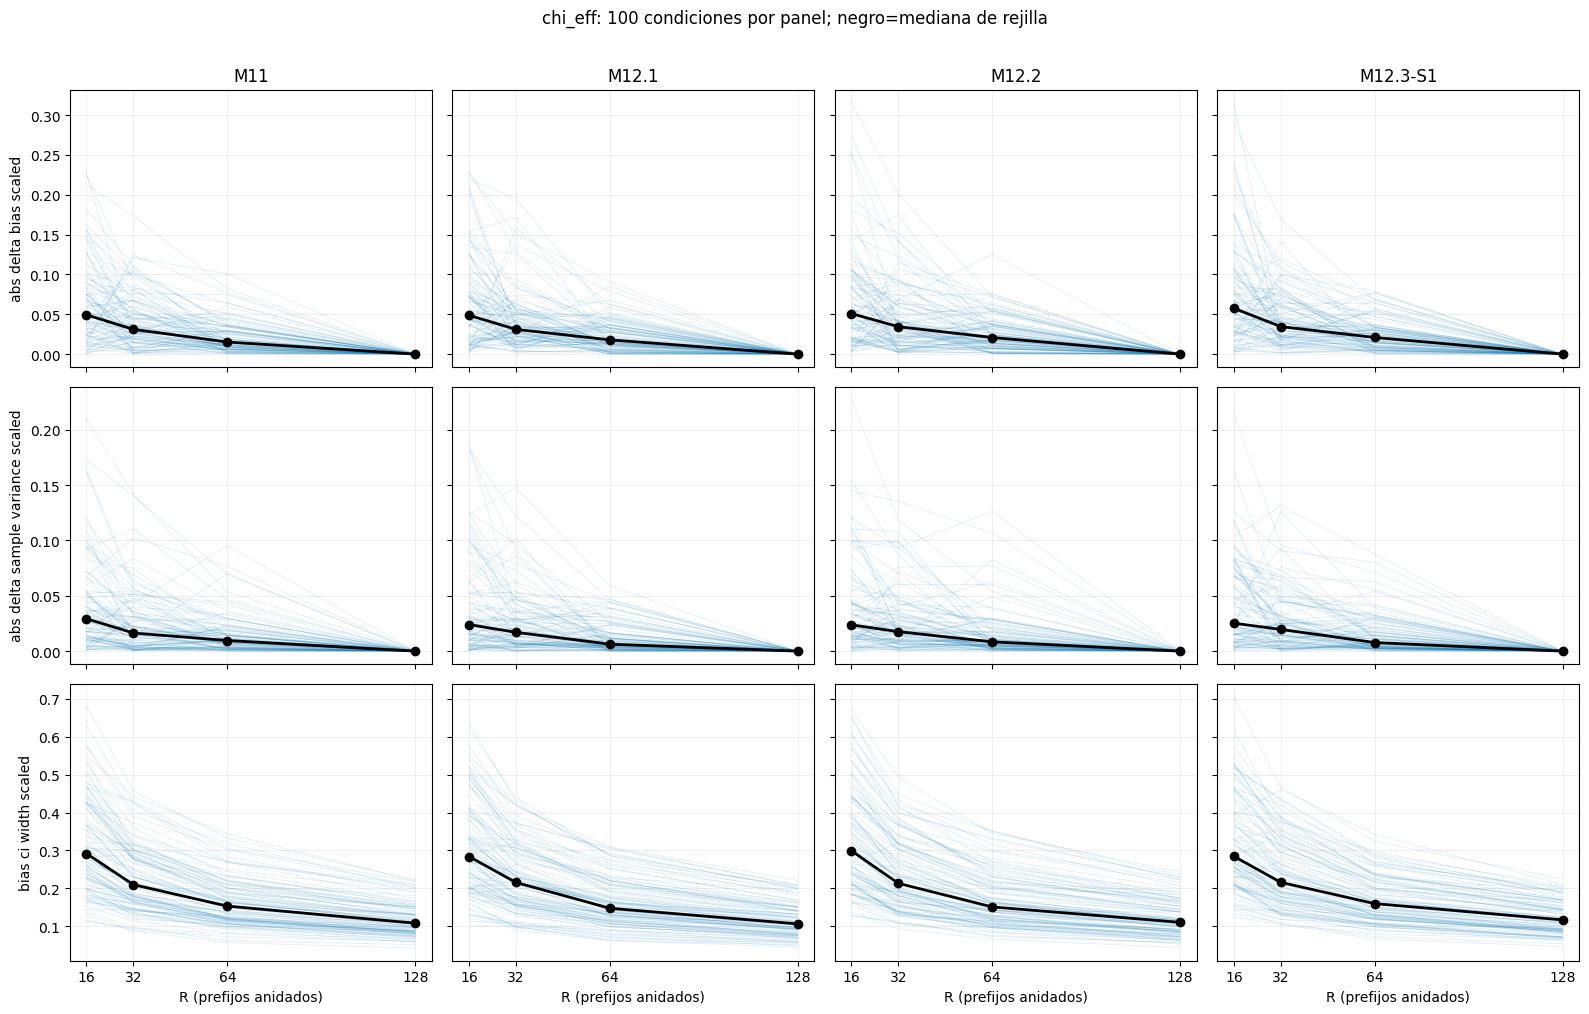

median_scaled_change  max_scaled_change  \
label      model_a model_b  R                                              
chi_eff    M11     M12.1    16               0.032804           0.210667   
                            32               0.019011           0.133124   
                            64               0.012242           0.076489   
                            128              0.000000           0.000000   
                   M12.2    16               0.027086           0.160641   
                            32               0.022340           0.240075   
                            64               0.014335           0.128424   
                            128              0.000000           0.000000   
                   M12.3-S1 16               0.031831           0.213560   
                            32               0.020474           0.105302   
                            64               0.011891           0.082381   
                            128              0.000000           0.000000   
           M12.1   M12.2    16               0.023189           0.218730   
                            32               0.018679           0.142287   
                            64               0.009574           0.172084   
                            128              0.000000           0.000000   
                   M12.3-S1 16               0.026984           0.203439   
                            32               0.021651           0.180984   
                            64               0.012000           0.066806   
                            128              0.000000           0.000000   
           M12.2   M12.3-S1 16               0.027619           0.236646   
                            32               0.022056           0.223146   
                            64               0.015096           0.136033   
                            128              0.000000           0.000000   
chirp_mass M11     M12.1    16               0.014387           0.143928   
                            32               0.009056           0.182543   
                            64               0.006566           0.102398   
                            128              0.000000           0.000000   
                   M12.2    16               0.014967           0.104189   
                            32               0.010143           0.176833   
                            64               0.005658           0.080003   
                            128              0.000000           0.000000   
                   M12.3-S1 16               0.016264           0.142543   
                            32               0.009681           0.150263   
                            64               0.005611           0.101557   
                            128              0.000000           0.000000   
           M12.1   M12.2    16               0.012992           0.197920   
                            32               0.008621           0.132057   
                            64               0.005016           0.121439   
                            128              0.000000           0.000000   
                   M12.3-S1 16               0.011469           0.217058   
                            32               0.009332           0.101657   
                            64               0.005237           0.073284   
                            128              0.000000           0.000000   
           M12.2   M12.3-S1 16               0.013378           0.154903   
                            32               0.008533           0.166656   
                            64               0.004767           0.094635   
                            128              0.000000           0.000000   
total_mass M11     M12.1    16               0.015935           0.168671   
                            32               0.010348           0.191806   
                            64               0.007418           0.099398   
     

absolute_error_q90             \
                                           median        max   
label      model    target_snr                                 
chi_eff    M11      10.0                 0.455986   0.952198   
                    15.0                 0.299971   0.590574   
                    20.0                 0.234022   0.488031   
                    24.5                 0.192396   0.460734   
           M12.1    10.0                 0.429243   0.914078   
                    15.0                 0.315181   0.590853   
                    20.0                 0.233848   0.469505   
                    24.5                 0.193808   0.361120   
           M12.2    10.0                 0.469267   0.992117   
                    15.0                 0.306668   0.615576   
                    20.0                 0.227187   0.439618   
                    24.5                 0.186452   0.401851   
           M12.3-S1 10.0                 0.467828   1.005989   
                    15.0                 0.300705   0.655704   
                    20.0                 0.225454   0.450697   
                    24.5                 0.188765   0.424184   
chirp_mass M11      10.0                 7.383591  22.453087   
                    15.0                 4.217619  13.551660   
                    20.0                 3.098819  10.504602   
                    24.5                 2.967045   8.566433   
           M12.1    10.0                 8.375355  20.995037   
                    15.0                 4.610712  12.363708   
                    20.0                 3.287762  11.095578   
                    24.5                 2.753648   8.189957   
           M12.2    10.0                 8.647556  18.728530   
                    15.0                 4.191597  12.240641   
                    20.0                 3.047882   9.570884   
                    24.5                 2.536727   8.014564   
           M12.3-S1 10.0                 7.710764  18.185374   
                    15.0                 5.057795  11.082628   
                    20.0                 3.152842   9.318647   
                    24.5                 2.700583   7.454055   
total_mass M11      10.0                21.748765  40.836919   
                    15.0                15.533290  25.662821   
                    20.0                11.978173  23.021438   
                    24.5                 9.528428  22.202043   
           M12.1    10.0                23.920654  37.456794   
                    15.0                14.288459  23.506160   
                    20.0                11.543189  20.904371   
                    24.5                 9.860504  18.701815   
           M12.2    10.0                23.891698  33.728609   
                    15.0                13.831226  23.426445   
                    20.0                10.906069  18.678560   
                    24.5                 9.400106  15.805282   
           M12.3-S1 10.0                21.689100  35.621877   
                    15.0                13.771127  22.727957   
                    20.0                11.120736  18.719835   
                    24.5                 9.211914  16.203832   

                               absolute_error_q95             \
                                           median        max   
label      model    target_snr                                 
chi_eff    M11      10.0                 0.513431   1.038037   
                    15.0                 0.347922   0.685941   
                    20.0                 0.269773   0.555962   
                    24.5                 0.220910   0.513310   
           M12.1    10.0                 0.510722   0.985044   
                    15.0                 0.369056   0.698435   
                    20.0                 0.267286   0.501293   
                    24.5                 0.228476   0.430368   
           M12.2    10.0                 0.540124   1.071005  

In [12]:
conv = convergence.copy()
scale = conv.label.map(dict(zip(LABELS, train_std)))
base128 = convergence.loc[convergence.R.eq(128)].set_index(["condition_id", "label", "model"])
conv_index = pd.MultiIndex.from_frame(conv[["condition_id", "label", "model"]])
for metric in ("bias", "conditional_rmse", "sample_variance"):
    exponent = 2 if metric == "sample_variance" else 1
    reference_values = base128[metric].reindex(conv_index).to_numpy()
    conv[f"abs_delta_{metric}_scaled"] = abs(conv[metric]-reference_values)/(scale**exponent)
conv["bias_ci_width_scaled"] = (conv.bias_ci_high-conv.bias_ci_low)/scale
conv_diagnostics = conv.groupby(["label", "model", "R"])[
    ["abs_delta_bias_scaled", "abs_delta_conditional_rmse_scaled", "abs_delta_sample_variance_scaled", "bias_ci_width_scaled"]].agg(["median", "max"])
with pd.option_context("display.max_rows", 48): display(conv_diagnostics)
for label in LABELS:
    fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, sharey="row")
    for col, model in enumerate(MODELS):
        subset = conv.loc[conv.label.eq(label) & conv.model.eq(model)]
        for row, metric in enumerate(("abs_delta_bias_scaled", "abs_delta_sample_variance_scaled", "bias_ci_width_scaled")):
            mat = subset.pivot(index="condition_id", columns="R", values=metric).reindex(columns=PREFIXES)
            ax = axes[row, col]
            ax.plot(PREFIXES, mat.to_numpy().T, color="#0072b2", alpha=.12, lw=.6)
            ax.plot(PREFIXES, mat.median(axis=0), color="black", lw=2, marker="o")
            ax.set_xticks(PREFIXES); ax.grid(alpha=.2)
            if row == 0: ax.set_title(model)
            if col == 0: ax.set_ylabel(metric.replace("_", " "))
            if row == 2: ax.set_xlabel("R (prefijos anidados)")
    fig.suptitle(f"{label}: 100 condiciones por panel; negro=mediana de rejilla", y=1.01)
    fig.tight_layout()
    finish_figure(fig, f"{label}_nested_convergence")

pair_conv = convergence_paired.copy()
pair_base = pair_conv.loc[pair_conv.R.eq(128)].set_index(["condition_id", "label", "model_a", "model_b"])
pair_index = pd.MultiIndex.from_frame(pair_conv[["condition_id", "label", "model_a", "model_b"]])
pair_conv["abs_delta_rmse_contrast_scaled"] = abs(pair_conv.delta_conditional_rmse - pair_base.delta_conditional_rmse.reindex(pair_index).to_numpy()) / pair_conv.label.map(dict(zip(LABELS, train_std)))
pair_conv["contrast_sign_changed_vs128"] = np.sign(pair_conv.delta_conditional_rmse) != np.sign(pair_base.delta_conditional_rmse.reindex(pair_index).to_numpy())
pair_convergence_summary = pair_conv.groupby(["label", "model_a", "model_b", "R"]).agg(
    median_scaled_change=("abs_delta_rmse_contrast_scaled", "median"),
    max_scaled_change=("abs_delta_rmse_contrast_scaled", "max"),
    sign_changes=("contrast_sign_changed_vs128", "sum"))
with pd.option_context("display.max_rows", 72): display(pair_convergence_summary)
tail_summary = summary.groupby(["label", "model", "target_snr"])[["absolute_error_q90", "absolute_error_q95", "max_absolute_error"]].agg(["median", "max"])
with pd.option_context("display.max_rows", 48): display(tail_summary)

## 8. Alcance informacional

Bajo una **distribución conjunta fija**, segundo momento finito, el **mismo observable X y el mismo prior**, para cada target:
$$\mathbb E[(Y-f(X))^2]=\mathbb E[\operatorname{Var}(Y\mid X)]+\mathbb E[(\mathbb E[Y\mid X]-f(X))^2].$$

El primer término es riesgo Bayes de ese experimento; el segundo, exceso del estimador. Es distinto de la descomposición de ruido a fuente fija. La rejilla diseñada no estima estos términos de riesgo poblacional. Varianza entre ruidos no es varianza posterior; predicciones estables no implican posterior estrecha.

Sesgo persistente CNN no demuestra falta de capacidad: pueden intervenir objetivo ponderado, muestreo, optimización, prior, procesamiento o información. Una referencia entrenada tampoco es automáticamente Bayes óptima. Inferencia sobre strain bruto con PSD/extrínsecos verdaderos extra no es un baseline de igual información frente a X normalizada.

M12.5.2 exige prior G1 explícito (distancia condicionada por SNR, colocación dependiente de duración, mezcla de entornos), igual observable/auxiliares, referencia independientemente validada, calibración posterior, precisión Monte Carlo, roles train/val/cal/test separados y evaluación poblacional adecuada. Este análisis no declara separados el límite informacional y el error de estimador.


## 9. Conclusiones científicas calculadas

La celda siguiente resume los datos verificados, por target/modelo y todas las parejas, sin fijar resultados del piloto ni elegir fuentes ilustrativas. Los recuentos, rangos y magnitudes se calculan al ejecutar. Dominancia, menor error y banderas de IC describen esta rejilla; no seleccionan un ganador poblacional ni un cambio arquitectónico.


In [13]:
conclusion_lines = [
    "### A. Alcance y reproducibilidad",
    f"Se verificaron {physical.source_id.nunique()} fuentes, {len(physical)} condiciones, "
    f"{predictions.observation_id.nunique():,} observaciones y {len(predictions):,} filas de predicción. "
    f"Las {len(summary)} filas principales y los {len(convergence)} resúmenes de prefijos conservan "
    f"la identidad finita, con residuo máximo {max_identity_residual:.3g}. "
    "Se verificaron CSV/JSON y hashes registrados, sin releer strain ni checkpoints.",
    "### B. Robustez al ruido y dependencia de SNR"]
for (label, model), row in endpoint_summary.iterrows():
    conclusion_lines.append(
        f"- **{label} / {model}:** de {int(row.sources)} fuentes, la varianza bajó en "
        f"{int(row.variance_decreases)}, RMSE en {int(row.rmse_decreases)} y |bias| en "
        f"{int(row.absolute_bias_decreases)} entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: "
        f"{row.mean_rmse_snr10:.4g} → {row.mean_rmse_snr24p5:.4g} {UNITS[label]}.")
conclusion_lines += ["### C. Sesgo residual y descomposición a SNR 24,5",
    "Dominancia compara bias² con 127/128·s². Banderas de sesgo: IC puntuales sin corrección global."]
for (label, model), group in high_snr.groupby(["label", "model"]):
    conclusion_lines.append(f"- **{label} / {model}:** bias firmado entre {group.bias.min():.4g} y "
        f"{group.bias.max():.4g}; |bias| medio {group.absolute_bias.mean():.4g} {UNITS[label]}. "
        f"{int(group.bias_ci_excludes_zero.sum())}/{len(group)} IC excluyen cero; sesgo² domina en "
        f"{int(group.dominant_component.eq('sesgo²').sum())}/{len(group)}. Mediana de fracción MSE "
        f"por sesgo²: {group.squared_bias_fraction.median():.3f}.")
conclusion_lines += ["### D. Contracción hacia medias train",
    "Dirección, acercamiento efectivo y sobrepaso son distintos; no establecen optimalidad Bayes."]
for (label, model), group in contraction.loc[contraction.target_snr.eq(24.5)].groupby(["label", "model"]):
    conclusion_lines.append(f"- **{label} / {model}:** dirección hacia media en "
        f"{int(group.toward_mean_direction.sum())}/{len(group)}, acercamiento en "
        f"{int(group.closer_to_mean.sum())}/{len(group)}, sobrepaso en {int(group.crosses_mean.sum())}. "
        f"Razón omitida por cercanía a media en {int(group.near_train_mean.sum())} fuentes.")
conclusion_lines += ["### E. Diferencias entre M11, M12.1, M12.2 y M12.3-S1",
    "Convención a−b; 100 condiciones por target/pareja. Estos recuentos no eligen un ganador poblacional."]
for (label, pair), row in pair_summary.iterrows():
    conclusion_lines.append(f"- **{label} / {pair}:** RMSE menor para a en {int(row.a_lower_rmse)}, "
        f"para b en {int(row.b_lower_rmse)} de {int(row.conditions)} condiciones; "
        f"{int(row.pointwise_ci_excludes_zero)} IC puntuales excluyen cero. "
        f"Media descriptiva ΔRMSE={row.mean_delta_rmse:.4g} {UNITS[label]}.")
conclusion_lines += ["### F. Precisión finita y colas",
    "Prefijos anidados: R=128 es referencia interna, no verdad. Los cambios no son réplicas independientes."]
for (label, model), group in conv.loc[conv.R.eq(64)].groupby(["label", "model"]):
    conclusion_lines.append(f"- **{label} / {model}:** de R=64 a 128, |Δbias|/σ_train tiene mediana "
        f"{group.abs_delta_bias_scaled.median():.3g} y máximo {group.abs_delta_bias_scaled.max():.3g}; "
        f"máximo |Δvar|/σ²_train={group.abs_delta_sample_variance_scaled.max():.3g}. "
        "Esto no demuestra convergencia asintótica.")
conclusion_lines += [
    "Los cuantiles y máximos quedan en tail_summary y las tablas completas; 128 ruidos no dan garantía sobre eventos raros.",
    "### G. Lo que establece y no establece el estudio",
    "Se cuantifican robustez, sesgo residual, SNR, contracción y diferencias de cuatro checkpoints "
    "condicionadas a la rejilla/entorno. No se estima riesgo Bayes G1, posterior ni incertidumbre "
    "entre entrenamientos; no se identifica una causa arquitectónica o un límite informacional.",
    "### H. Evidencia pendiente para M12.5.2",
    "Se necesita referencia de igual observable/prior/auxiliares, validación independiente, calibración, "
    "precisión Monte Carlo y evaluación con fuentes de la distribución declarada y roles de splits "
    "preservados. Una referencia raw-strain con información extra es otro experimento."]
conclusions_markdown = "\n\n".join(conclusion_lines)
display(Markdown(conclusions_markdown))

### A. Alcance y reproducibilidad

Se verificaron 25 fuentes, 100 condiciones, 12,800 observaciones y 153,600 filas de predicción. Las 1200 filas principales y los 4800 resúmenes de prefijos conservan la identidad finita, con residuo máximo 1.02e-12. Se verificaron CSV/JSON y hashes registrados, sin releer strain ni checkpoints.

### B. Robustez al ruido y dependencia de SNR

- **chi_eff / M11:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 21 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 0.3074 → 0.1309 adimensional.

- **chi_eff / M12.1:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 23 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 0.3079 → 0.124 adimensional.

- **chi_eff / M12.2:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 22 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 0.3146 → 0.1259 adimensional.

- **chi_eff / M12.3-S1:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 21 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 0.309 → 0.1309 adimensional.

- **chirp_mass / M11:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 23 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 6.507 → 2.644 M⊙ (detector).

- **chirp_mass / M12.1:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 24 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 6.711 → 2.512 M⊙ (detector).

- **chirp_mass / M12.2:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 21 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 6.424 → 2.3 M⊙ (detector).

- **chirp_mass / M12.3-S1:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 23 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 6.191 → 2.185 M⊙ (detector).

- **total_mass / M11:** de 25 fuentes, la varianza bajó en 25, RMSE en 24 y |bias| en 22 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 15.54 → 7.426 M⊙ (detector).

- **total_mass / M12.1:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 22 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 16.11 → 6.731 M⊙ (detector).

- **total_mass / M12.2:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 22 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 15.57 → 6.349 M⊙ (detector).

- **total_mass / M12.3-S1:** de 25 fuentes, la varianza bajó en 25, RMSE en 25 y |bias| en 20 entre SNR 10 y 24,5. Media descriptiva de RMSE condicional: 14.52 → 5.932 M⊙ (detector).

### C. Sesgo residual y descomposición a SNR 24,5

Dominancia compara bias² con 127/128·s². Banderas de sesgo: IC puntuales sin corrección global.

- **chi_eff / M11:** bias firmado entre -0.1292 y 0.3242; |bias| medio 0.06931 adimensional. 20/25 IC excluyen cero; sesgo² domina en 7/25. Mediana de fracción MSE por sesgo²: 0.205.

- **chi_eff / M12.1:** bias firmado entre -0.102 y 0.2175; |bias| medio 0.06847 adimensional. 20/25 IC excluyen cero; sesgo² domina en 8/25. Mediana de fracción MSE por sesgo²: 0.204.

- **chi_eff / M12.2:** bias firmado entre -0.09879 y 0.2501; |bias| medio 0.06569 adimensional. 21/25 IC excluyen cero; sesgo² domina en 5/25. Mediana de fracción MSE por sesgo²: 0.248.

- **chi_eff / M12.3-S1:** bias firmado entre -0.1002 y 0.2944; |bias| medio 0.0684 adimensional. 22/25 IC excluyen cero; sesgo² domina en 5/25. Mediana de fracción MSE por sesgo²: 0.246.

- **chirp_mass / M11:** bias firmado entre -3.888 y 2.18; |bias| medio 1.823 M⊙ (detector). 23/25 IC excluyen cero; sesgo² domina en 14/25. Mediana de fracción MSE por sesgo²: 0.518.

- **chirp_mass / M12.1:** bias firmado entre -3.764 y 2.435; |bias| medio 1.637 M⊙ (detector). 23/25 IC excluyen cero; sesgo² domina en 15/25. Mediana de fracción MSE por sesgo²: 0.514.

- **chirp_mass / M12.2:** bias firmado entre -3.456 y 1.229; |bias| medio 1.43 M⊙ (detector). 23/25 IC excluyen cero; sesgo² domina en 13/25. Mediana de fracción MSE por sesgo²: 0.506.

- **chirp_mass / M12.3-S1:** bias firmado entre -3.44 y 1.314; |bias| medio 1.282 M⊙ (detector). 20/25 IC excluyen cero; sesgo² domina en 8/25. Mediana de fracción MSE por sesgo²: 0.228.

- **total_mass / M11:** bias firmado entre -7.652 y 12.34; |bias| medio 5.685 M⊙ (detector). 24/25 IC excluyen cero; sesgo² domina en 18/25. Mediana de fracción MSE por sesgo²: 0.629.

- **total_mass / M12.1:** bias firmado entre -6.939 y 12.97; |bias| medio 4.727 M⊙ (detector). 24/25 IC excluyen cero; sesgo² domina en 13/25. Mediana de fracción MSE por sesgo²: 0.519.

- **total_mass / M12.2:** bias firmado entre -6.73 y 10.15; |bias| medio 4.405 M⊙ (detector). 23/25 IC excluyen cero; sesgo² domina en 13/25. Mediana de fracción MSE por sesgo²: 0.502.

- **total_mass / M12.3-S1:** bias firmado entre -7.85 y 7.661; |bias| medio 4.051 M⊙ (detector). 25/25 IC excluyen cero; sesgo² domina en 12/25. Mediana de fracción MSE por sesgo²: 0.455.

### D. Contracción hacia medias train

Dirección, acercamiento efectivo y sobrepaso son distintos; no establecen optimalidad Bayes.

- **chi_eff / M11:** dirección hacia media en 17/25, acercamiento en 13/25, sobrepaso en 5. Razón omitida por cercanía a media en 5 fuentes.

- **chi_eff / M12.1:** dirección hacia media en 16/25, acercamiento en 13/25, sobrepaso en 4. Razón omitida por cercanía a media en 5 fuentes.

- **chi_eff / M12.2:** dirección hacia media en 16/25, acercamiento en 12/25, sobrepaso en 4. Razón omitida por cercanía a media en 5 fuentes.

- **chi_eff / M12.3-S1:** dirección hacia media en 15/25, acercamiento en 12/25, sobrepaso en 4. Razón omitida por cercanía a media en 5 fuentes.

- **chirp_mass / M11:** dirección hacia media en 24/25, acercamiento en 24/25, sobrepaso en 0. Razón omitida por cercanía a media en 0 fuentes.

- **chirp_mass / M12.1:** dirección hacia media en 22/25, acercamiento en 22/25, sobrepaso en 0. Razón omitida por cercanía a media en 0 fuentes.

- **chirp_mass / M12.2:** dirección hacia media en 21/25, acercamiento en 21/25, sobrepaso en 0. Razón omitida por cercanía a media en 0 fuentes.

- **chirp_mass / M12.3-S1:** dirección hacia media en 19/25, acercamiento en 19/25, sobrepaso en 0. Razón omitida por cercanía a media en 0 fuentes.

- **total_mass / M11:** dirección hacia media en 25/25, acercamiento en 25/25, sobrepaso en 0. Razón omitida por cercanía a media en 0 fuentes.

- **total_mass / M12.1:** dirección hacia media en 23/25, acercamiento en 23/25, sobrepaso en 0. Razón omitida por cercanía a media en 0 fuentes.

- **total_mass / M12.2:** dirección hacia media en 24/25, acercamiento en 24/25, sobrepaso en 0. Razón omitida por cercanía a media en 0 fuentes.

- **total_mass / M12.3-S1:** dirección hacia media en 24/25, acercamiento en 24/25, sobrepaso en 0. Razón omitida por cercanía a media en 0 fuentes.

### E. Diferencias entre M11, M12.1, M12.2 y M12.3-S1

Convención a−b; 100 condiciones por target/pareja. Estos recuentos no eligen un ganador poblacional.

- **chi_eff / M11 − M12.1:** RMSE menor para a en 48, para b en 52 de 100 condiciones; 38 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.00241 adimensional.

- **chi_eff / M11 − M12.2:** RMSE menor para a en 51, para b en 49 de 100 condiciones; 48 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.0001039 adimensional.

- **chi_eff / M11 − M12.3-S1:** RMSE menor para a en 53, para b en 47 de 100 condiciones; 51 IC puntuales excluyen cero. Media descriptiva ΔRMSE=-0.00206 adimensional.

- **chi_eff / M12.1 − M12.2:** RMSE menor para a en 56, para b en 44 de 100 condiciones; 53 IC puntuales excluyen cero. Media descriptiva ΔRMSE=-0.002306 adimensional.

- **chi_eff / M12.1 − M12.3-S1:** RMSE menor para a en 59, para b en 41 de 100 condiciones; 48 IC puntuales excluyen cero. Media descriptiva ΔRMSE=-0.004469 adimensional.

- **chi_eff / M12.2 − M12.3-S1:** RMSE menor para a en 58, para b en 42 de 100 condiciones; 40 IC puntuales excluyen cero. Media descriptiva ΔRMSE=-0.002164 adimensional.

- **chirp_mass / M11 − M12.1:** RMSE menor para a en 34, para b en 66 de 100 condiciones; 60 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.09764 M⊙ (detector).

- **chirp_mass / M11 − M12.2:** RMSE menor para a en 24, para b en 76 de 100 condiciones; 56 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.3251 M⊙ (detector).

- **chirp_mass / M11 − M12.3-S1:** RMSE menor para a en 34, para b en 66 de 100 condiciones; 65 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.4393 M⊙ (detector).

- **chirp_mass / M12.1 − M12.2:** RMSE menor para a en 35, para b en 65 de 100 condiciones; 47 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.2274 M⊙ (detector).

- **chirp_mass / M12.1 − M12.3-S1:** RMSE menor para a en 40, para b en 60 de 100 condiciones; 64 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.3417 M⊙ (detector).

- **chirp_mass / M12.2 − M12.3-S1:** RMSE menor para a en 41, para b en 59 de 100 condiciones; 54 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.1143 M⊙ (detector).

- **total_mass / M11 − M12.1:** RMSE menor para a en 22, para b en 78 de 100 condiciones; 54 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.3488 M⊙ (detector).

- **total_mass / M11 − M12.2:** RMSE menor para a en 22, para b en 78 de 100 condiciones; 58 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.8421 M⊙ (detector).

- **total_mass / M11 − M12.3-S1:** RMSE menor para a en 34, para b en 66 de 100 condiciones; 74 IC puntuales excluyen cero. Media descriptiva ΔRMSE=1.427 M⊙ (detector).

- **total_mass / M12.1 − M12.2:** RMSE menor para a en 40, para b en 60 de 100 condiciones; 51 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.4933 M⊙ (detector).

- **total_mass / M12.1 − M12.3-S1:** RMSE menor para a en 46, para b en 54 de 100 condiciones; 82 IC puntuales excluyen cero. Media descriptiva ΔRMSE=1.078 M⊙ (detector).

- **total_mass / M12.2 − M12.3-S1:** RMSE menor para a en 49, para b en 51 de 100 condiciones; 65 IC puntuales excluyen cero. Media descriptiva ΔRMSE=0.5851 M⊙ (detector).

### F. Precisión finita y colas

Prefijos anidados: R=128 es referencia interna, no verdad. Los cambios no son réplicas independientes.

- **chi_eff / M11:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.0152 y máximo 0.101; máximo |Δvar|/σ²_train=0.0951. Esto no demuestra convergencia asintótica.

- **chi_eff / M12.1:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.0179 y máximo 0.091; máximo |Δvar|/σ²_train=0.0592. Esto no demuestra convergencia asintótica.

- **chi_eff / M12.2:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.0209 y máximo 0.125; máximo |Δvar|/σ²_train=0.126. Esto no demuestra convergencia asintótica.

- **chi_eff / M12.3-S1:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.0209 y máximo 0.0788; máximo |Δvar|/σ²_train=0.0875. Esto no demuestra convergencia asintótica.

- **chirp_mass / M11:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.00752 y máximo 0.0673; máximo |Δvar|/σ²_train=0.0501. Esto no demuestra convergencia asintótica.

- **chirp_mass / M12.1:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.00676 y máximo 0.0922; máximo |Δvar|/σ²_train=0.0844. Esto no demuestra convergencia asintótica.

- **chirp_mass / M12.2:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.00835 y máximo 0.0756; máximo |Δvar|/σ²_train=0.0556. Esto no demuestra convergencia asintótica.

- **chirp_mass / M12.3-S1:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.00843 y máximo 0.0736; máximo |Δvar|/σ²_train=0.0488. Esto no demuestra convergencia asintótica.

- **total_mass / M11:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.0111 y máximo 0.0649; máximo |Δvar|/σ²_train=0.0574. Esto no demuestra convergencia asintótica.

- **total_mass / M12.1:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.00981 y máximo 0.0853; máximo |Δvar|/σ²_train=0.089. Esto no demuestra convergencia asintótica.

- **total_mass / M12.2:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.0101 y máximo 0.0691; máximo |Δvar|/σ²_train=0.0575. Esto no demuestra convergencia asintótica.

- **total_mass / M12.3-S1:** de R=64 a 128, |Δbias|/σ_train tiene mediana 0.0125 y máximo 0.068; máximo |Δvar|/σ²_train=0.0481. Esto no demuestra convergencia asintótica.

Los cuantiles y máximos quedan en tail_summary y las tablas completas; 128 ruidos no dan garantía sobre eventos raros.

### G. Lo que establece y no establece el estudio

Se cuantifican robustez, sesgo residual, SNR, contracción y diferencias de cuatro checkpoints condicionadas a la rejilla/entorno. No se estima riesgo Bayes G1, posterior ni incertidumbre entre entrenamientos; no se identifica una causa arquitectónica o un límite informacional.

### H. Evidencia pendiente para M12.5.2

Se necesita referencia de igual observable/prior/auxiliares, validación independiente, calibración, precisión Monte Carlo y evaluación con fuentes de la distribución declarada y roles de splits preservados. Una referencia raw-strain con información extra es otro experimento.

## 10. Exportación opcional y registro

`EXPORT=False` no escribe artefactos. Activarlo reserva una carpeta nueva antes de las figuras; si existe, se detiene. Se exportan tablas derivadas CSV, conclusiones/procedencia JSON y PNG de las figuras, sin duplicar strain/checkpoints/predicciones ni sobrescribir `full_analysis_v1`.

Para otra exportación, cambiar el nombre de carpeta y reiniciar ejecución secuencial. El recibo `complete=True` se escribe al final: una carpeta parcial sin él no representa análisis terminado. NaN en CSV denota fracción/razón indefinida, no cero.


In [14]:
if EXPORT:
    export_tables = {
        "conditional_summary.csv": summary, "snr_endpoints.csv": endpoints,
        "high_snr_bias.csv": high_snr, "contraction.csv": contraction,
        "grid_snr_summary.csv": endpoint_summary.reset_index(),
        "grid_pair_summary.csv": pair_summary.reset_index(),
        "paired_convergence_summary.csv": pair_convergence_summary.reset_index(),
    }
    for name, frame in export_tables.items():
        contracts.write_csv(OUTPUT / name, frame.to_dict("records"))
    contracts.write_json(OUTPUT / "scientific_conclusions.json", {"markdown": conclusions_markdown})
    notebook_path = PROJECT_ROOT / "notebooks/m12/M12_5_1_full_repeated_noise_analysis.ipynb"
    exports = [*export_tables, "scientific_conclusions.json", *saved_plots]
    contracts.write_json(OUTPUT / "notebook_analysis.json", dict(
        complete=True, notebook=contracts.record(notebook_path, True),
        inputs={str(p.relative_to(STUDY_ROOT)): contracts.record(p, True) for p in required},
        analysis_code_sha256=contracts.digest(scalar_analysis.__file__),
        finite_R_max_residual=max_identity_residual, bootstrap_recomputed=False,
        limitations="Designed grid; conditional noise uncertainty; nested prefixes; pointwise CIs; no population Bayes/posterior claim",
        outputs={name: contracts.record(OUTPUT / name, True) for name in exports}))
    print("Exportación nueva:", OUTPUT)
else:
    print("Exportación desactivada; artefactos existentes intactos.")

Exportación desactivada; artefactos existentes intactos.


## 11. Scientific conclusions — M12.5.1-B

### 11.1. Experimental validation and scope

The full M12.5.1-B experiment evaluated four frozen CNN checkpoints (M11, M12.1, M12.2 and M12.3-S1) using 25 deliberately selected BBH configurations, four optimal-network-SNR levels (10, 15, 20 and 24.5), and 128 independent Gaussian-noise realizations per condition.

The resulting 12,800 observations were shared across all four models, yielding 153,600 parameter predictions.

Provenance, checkpoint identity, observation alignment, metadata consistency and the finite-sample bias–variance decomposition were validated. The maximum numerical residual in the MSE decomposition was approximately $1.02\times10^{-12}$.

This study provides a controlled characterization of estimator behavior. However, the selected sources and fixed PSD environment do not constitute a representative sample of the full G1 population.

### 11.2. Strong SNR dependence and noise sensitivity

Increasing SNR from 10 to 24.5 substantially reduced conditional prediction errors.

Noise-sampling variance decreased in all 300 source–model–target combinations, while conditional RMSE decreased in 299 of 300.

For the baseline M11 estimator, the mean source-specific conditional RMSE decreased from:

- $6.507$ to $2.644\,M_\odot$ for chirp mass.
- $15.536$ to $7.426\,M_\odot$ for total mass.
- $0.307$ to $0.131$ for effective spin.

These findings demonstrate that the frozen CNNs exploit observational information that becomes more informative as SNR increases.

Nevertheless, improved stability against noise does not imply that predictions converge to the true parameters.

### 11.3. Persistent systematic bias at high SNR

Although noise variance and conditional RMSE generally decreased, substantial systematic biases remained at SNR 24.5.

For M11, the mean absolute conditional bias across the 25 sources was:

| Parameter | Mean absolute bias at SNR 24.5 |
|---|---:|
| Chirp mass | $1.823\,M_\odot$ |
| Total mass | $5.685\,M_\odot$ |
| Effective spin | $0.0693$ |

For chirp mass and total mass, squared bias was the dominant contribution to conditional MSE in 14/25 and 18/25 M11 source configurations, respectively.

For effective spin, squared bias dominated in only 7/25 configurations, indicating a different balance between systematic errors and noise sensitivity.

Consequently, the remaining error cannot be explained solely by fluctuations among independent noise realizations.

### 11.4. Regression contraction toward G1 training means

The analysis confirms persistent contraction of mass predictions toward their corresponding G1 training means.

At SNR 24.5, M11 predictions exhibited bias directed toward the training mean in:

- 24/25 sources for chirp mass.
- 25/25 sources for total mass.
- 17/25 sources for effective spin.

The effect is therefore particularly consistent for mass estimation.

Importantly, a bias directed toward the training mean is not automatically evidence of an incorrect estimator. Under squared-error minimization, the Bayes-optimal estimator is the conditional expectation, which may naturally exhibit contraction under a broad prior and noisy observations.

The present study establishes the empirical persistence of contraction but cannot determine whether it is statistically optimal.

### 11.5. Effect of M12 training interventions

The M12 interventions modify the conditional error structure, particularly for mass estimation.

At SNR 24.5, M12.3-S1 achieved the lowest mean source-specific conditional RMSE for both mass targets:

- Chirp mass: $2.185\,M_\odot$, compared with $2.644\,M_\odot$ for M11.
- Total mass: $5.932\,M_\odot$, compared with $7.426\,M_\odot$ for M11.

Its corresponding mean absolute biases were reduced to approximately $1.282\,M_\odot$ and $4.051\,M_\odot$, respectively.

However, contraction remained present, particularly for total mass.

For effective spin, improvements were less consistent. At SNR 24.5, M12.1 achieved the smallest mean conditional RMSE ($0.124$), while M12.3-S1 remained close to M11.

These results suggest that training-distribution interventions can mitigate some mass biases without resolving all target-dependent limitations.

They do not establish a globally superior checkpoint because the designed grid differs from the G1 validation distribution. Model comparisons also involve correlated, multiple pointwise contrasts rather than a confirmatory population-level comparison.

### 11.6. Monte Carlo precision and remaining limitations

The convergence analysis using nested subsets of 16, 32, 64 and 128 noise realizations indicates improving stability of conditional estimates.

Nevertheless, some source-dependent differences remain between 64 and 128 realizations, particularly for effective spin and extreme conditions.

The current results are therefore appropriate for identifying robust patterns and evaluating conditional estimator behavior, but they do not establish asymptotic convergence or precisely characterize very rare prediction errors.

Furthermore, the experiment uses one PSD environment, fixed extrinsic configurations per source and a single trained checkpoint per intervention. It does not quantify variability across detector environments, astrophysical populations or independent training runs.

### 11.7. What this experiment establishes about recoverable information

The main research objective of M12.5 is to distinguish:

**H1 — Information limitation:** the observed gravitational-wave data do not sufficiently constrain the physical parameters.

**H2 — Estimator limitation:** the observations contain useful parameter information that the current CNN fails to exploit efficiently.

M12.5.1-B provides evidence that both noise sensitivity and persistent systematic estimation errors contribute to conditional MSE.

However, this bias–variance decomposition is not equivalent to the fundamental decomposition of population squared-error risk:

$$
\mathbb E[(Y-f(X))^2]
=
\underbrace{\mathbb E[\mathrm{Var}(Y\mid X)]}_{\text{Irreducible Bayes risk}}
+
\underbrace{\mathbb E[(f(X)-\mathbb E[Y\mid X])^2]}_{\text{Excess estimator risk}}.
$$

The latter requires a fixed joint distribution, the same observable $X$, the same prior and an appropriate reference for the conditional target distribution.

Repeated-noise experiments at fixed physical parameters cannot separately identify these terms, regardless of the number of noise realizations.

Therefore, persistent bias at SNR 24.5 is not sufficient evidence that the CNN architecture is inadequate, and small prediction variance does not establish narrow posterior uncertainty.

### 11.8. Implications for M12.5.2

The present findings motivate an independent inference reference rather than an immediate redesign of the neural network.

The next stage must distinguish:

1. **Physical information:** parameter information accessible from detector strain under a validated physical likelihood and prior.
2. **Representation information:** information preserved after the G1 whitening, filtering, cropping and per-detector normalization.
3. **Estimator efficiency:** information contained in the normalized CNN input $X$ that the frozen models may fail to exploit.

A raw-strain Bayesian reference can characterize physical degeneracies, but it cannot directly establish CNN inefficiency if it uses additional amplitude, PSD or extrinsic information.

A fair estimator-efficiency comparison requires a validated reference using the same observable $X$, compatible priors and equivalent auxiliary information.

### 11.9. Final research conclusion

**M12.5.1-B confirms that increasing observational SNR substantially improves the stability and accuracy of the frozen CNN estimators, while significant systematic mass-estimation biases and regression contraction persist.**

The M12 training interventions mitigate part of the mass bias, but their improvements are not uniform across parameters and do not establish whether the residual error is avoidable.

The experiment successfully characterizes conditional estimator behavior across a larger set of physical configurations. It does not measure the irreducible information limit of G1.

**Research decision:** close the controlled repeated-noise study and proceed to M12.5.2, prioritizing an independently validated information reference before changing the CNN architecture.

The outstanding scientific question is:

*To what extent are the residual errors explained by physical and representation-level information limitations, and to what extent do they reflect recoverable information that the current CNN estimators fail to exploit?*